# Individual-level instability of ICU risk predictions

## Notebook 3 of 3: external evaluation in 205 eICU-CRD hospitals, multiplicity, deferral, sensitivity analyses and governance

Notebooks 1 and 2 built harmonised cohorts and measured, in MIMIC-IV, how much an individual's predicted risk and decision depend on the development sample, and how well the bootstrap audit measures this. This notebook asks what happens **when the models are used in other hospitals**, which is where clinical decisions are actually made.

**Questions**

1. **Standard external validation.** How do the four model classes discriminate, calibrate and add net benefit in eICU-CRD, pooled and hospital by hospital (random-effects meta-analysis with prediction intervals, TRIPOD-Cluster)?
2. **Transport of instability.** Are individual predictions for patients in other hospitals more unstable than for comparable development patients? The *instability transport ratio* compares each external patient's instability with the instability of development patients at the same predicted risk.
3. **Why.** Is extra instability concentrated in patients who are atypical of the development population (membership model) and in particular hospitals?
4. **Two failure modes.** Do miscalibration (a bias problem, seen by standard validation) and instability (a variance problem, invisible to it) occur in the same hospitals, or in different ones?
5. **Sample size, externally.** Using the independent development samples of notebook 2, how does true instability in eICU-CRD patients fall with development size, and does the bootstrap still estimate it correctly outside the development population?
6. **Two sources of arbitrariness.** How large is decision arbitrariness from *model choice* (predictive multiplicity across a Rashomon set of near-equivalent models) compared with arbitrariness from *the sample* (instability)?
7. **What to do about it.** Does deferring the patients flagged as unstable to clinical review remove truly unstable decisions, and is the bootstrap flag better than simply deferring patients close to the threshold?
8. **Robustness and governance.** Pre-specified sensitivity analyses, and a pre-specified stability acceptance policy applied to every model (stability report card, model facts).

The notebook closes with a central illustration, an automatically generated results digest, the combined reporting checklist (TRIPOD+AI and TRIPOD-Cluster) and a study-wide provenance manifest covering all three notebooks.

**Data governance.** `outputs/part3/data` and `cache/part3_*` contain patient-level predictions and are protected by `.gitignore`. Figures and tables contain aggregates only; hospital identifiers are replaced by rank numbers in all figures.

## 0. Pre-specified analysis plan

| Element | Specification |
|---|---|
| External population | eICU-CRD main cohort from notebook 1 (first ICU stay per patient, 205 hospitals) |
| Models | The four full-sample MIMIC-IV models of notebook 2 and their 200 bootstrap refits (predictions stored by notebook 2; no refitting) |
| Performance | AUROC, calibration-in-the-large, calibration slope, observed/expected (O/E), integrated calibration index, Brier score, net benefit at 0.10, 0.20, 0.30. Pooled 95% intervals from 1,000 hospital-cluster bootstrap resamples |
| Hospital level | Hospitals with at least 100 stays (sensitivity: 50). Per hospital: AUROC (Hanley-McNeil SE), log O/E, calibration slope (at least 10 events and 10 non-events), instability index, decision-unstable share, flag rate across refits. REML random-effects meta-analysis with 95% confidence and prediction intervals and I-squared |
| Instability measure | Per patient SD of the 200 refit risks. Development reference: out-of-bag SD (only refits that did not see the patient, at least 5), so that development and external patients are both unseen by the refits. Risk coordinate: mean risk over the same unseen refits. Decision instability ratio (DIR): observed decision-unstable eICU-CRD patients divided by those expected from development patients at the same risk |
| Instability transport ratio (ITR) | Sum of external SDs divided by the sum of the development SDs expected at the same risk (40 risk bins on the logit scale, linear interpolation). ITR = 1: instability transports unchanged; ITR > 1: amplified. 95% interval from 1,000 hospital-cluster bootstrap resamples |
| Atypicality | Membership model (histogram gradient boosting, 5-fold cross-fitted) separating eICU-CRD from MIMIC-IV patients using all predictors and their missingness; atypicality = log density ratio |
| Thresholds | 0.10 (primary), 0.20, 0.30; decision-unstable = more than 10% of models disagree with the majority |
| Multiverse, externally | Notebook 2's 30 independent development samples per size predicted 20,000 eICU-CRD patients; truth and bootstrap estimates are compared exactly as in notebook 2 |
| Multiplicity | 12 pre-specified candidate specifications fitted on the notebook 2 development pool; Rashomon set = AUROC on the MIMIC-IV audit panel within 0.01 of the best (sensitivity: 0.02); measures in eICU-CRD: viable prediction range, ambiguity, discrepancy |
| Deferral | Patients ranked by (a) bootstrap decision instability, (b) closeness of risk to the threshold, (c) random; residual share of truly decision-unstable patients among those not deferred |
| Sensitivity analyses | S1 all ICU stays with patient-cluster bootstrap; S2 secondary outcome (ICU stay of 7 days or more); S3 hourly-mean vital-sign rule; S4a model without the GCS motor score; S4b external evaluation restricted to hospitals that chart the GCS motor score; S5 random forest recalibrated on out-of-bag predictions; S6 hospital threshold of 50 stays. B = 100 refits each |
| Governance | Pre-specified stability policy (section 12) evaluated for development and external populations |
| Post hoc additions (after the first full run, labelled as such) | Risk-standardised decision instability ratio and its use in the calibration-versus-instability classification; missingness-pattern mechanism analysis and membership model on missingness alone (section 6); S7 refits without missingness indicators; Monte Carlo intervals for the multiverse truth; reporting rule for sample sizes more than 10 times beyond the evaluated range |

In [1]:
import datetime as dt
import hashlib
import inspect
import json
import math
import os
import platform
import sys
import time
import warnings
import zlib
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, Patch
from scipy.optimize import minimize_scalar
from scipy.stats import norm, rankdata, spearmanr
from scipy.stats import t as student_t
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer

import cpmaudit
from cpmaudit import ModelBuilder, StabilityAudit, StabilityPolicy, StabilityResult, model_facts
from cpmaudit.metrics import brier_score, calibration_intercept_slope, roc_auc
from cpmaudit.models import fit_quietly
from cpmaudit.multiplicity import multiplicity_measures, rashomon_set
from cpmaudit.resampling import BootstrapSampler

try:
    from joblib import parallel_config
except ImportError:  # joblib < 1.3
    from joblib import parallel_backend as parallel_config

warnings.filterwarnings("ignore", category=FutureWarning)


def expit(x):
    """Logistic function (plain NumPy, so that functions sent to parallel workers pickle cleanly)."""
    return 0.5 * (1.0 + np.tanh(0.5 * np.asarray(x, dtype=np.float64)))

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)

ENVIRONMENT = {
    "python": sys.version.split()[0], "platform": platform.platform(), "cpu_count": os.cpu_count(),
    "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__, "cpmaudit": cpmaudit.__version__,
}
for key, value in ENVIRONMENT.items():
    print(f"{key:>13}: {value}")

       python: 3.11.5
     platform: Windows-10-10.0.26300-SP0
    cpu_count: 14
        numpy: 2.4.6
       pandas: 3.1.1
        scipy: 1.17.1
 scikit-learn: 1.9.1
   matplotlib: 3.11.2
     cpmaudit: 0.1.0


## 1. Configuration

`STUDY_P3_PRESET=quick` runs every analysis in a reduced form (fewer refits and resamples) to check the set-up. The default `full` preset is the pre-specified analysis. `STUDY_P3_SENS_MODELS` (comma-separated, e.g. `lr,hgb`) limits the sensitivity analyses to some model classes if time is short; by default all four are run.

In [2]:
PRESET = os.environ.get("STUDY_P3_PRESET", "full").lower()
assert PRESET in ("full", "quick"), "STUDY_P3_PRESET must be 'full' or 'quick'"
FULL = PRESET == "full"

CONFIG = {
    "preset": PRESET,
    "seed": 20261122,
    "min_hospital_stays": 100,
    "min_hospital_stays_sensitivity": 50,
    "min_events_slope": 10,
    "cluster_boot": 1000 if FULL else 60,
    "subgroup_boot": 300 if FULL else 40,
    "risk_bins": 40,
    "domain_folds": 5,
    "rashomon_epsilon": 0.01,
    "rashomon_epsilon_sensitivity": 0.02,
    "b_sens": 100 if FULL else 10,
    "deferral_grid": [round(x, 3) for x in np.linspace(0, 0.4, 41)],
    "gcs_charting_max_missing": 0.10,
    "calibration_band": (0.8, 1.25),
    "unstable_limit_hospital": 0.10,
    "n_jobs": int(os.environ.get("STUDY_N_JOBS", max(1, (os.cpu_count() or 2) - 1))),
    "project_dir": Path(os.environ.get("STUDY_PROJECT_DIR", Path.cwd())),
    "force": os.environ.get("STUDY_FORCE_REBUILD", "0") == "1",
}
SENS_MODELS = [m.strip() for m in os.environ.get("STUDY_P3_SENS_MODELS", "lr,ridge,rf,hgb").split(",") if m.strip()]
N_JOBS = CONFIG["n_jobs"]

PROJECT = CONFIG["project_dir"]
P1, P2 = PROJECT / "outputs" / "part1", PROJECT / "outputs" / "part2"
OUT = PROJECT / "outputs" / "part3"
DIRS = {name: OUT / name for name in ("figures", "tables", "data", "logs")}
CACHE = PROJECT / "cache" / f"part3_{PRESET}"
for folder in list(DIRS.values()) + [CACHE]:
    folder.mkdir(parents=True, exist_ok=True)
for private in (DIRS["data"], CACHE.parent):
    (private / ".gitignore").write_text("*\n", encoding="utf-8")
print(f"Preset: {PRESET}; parallel workers: {N_JOBS}; sensitivity models: {SENS_MODELS}")
print("Project folder:", PROJECT.resolve())

Preset: full; parallel workers: 13; sensitivity models: ['lr', 'ridge', 'rf', 'hgb']
Project folder: C:\Users\kruta\Downloads


In [3]:
def stable_int(value):
    return zlib.crc32(str(value).encode()) & 0x7FFFFFFF


def seed_for(*keys):
    return int(np.random.SeedSequence([CONFIG["seed"], *[stable_int(k) for k in keys]]).generate_state(1)[0])


def sha256_file(path, block=1 << 20):
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(block), b""):
            digest.update(chunk)
    return digest.hexdigest()


class Provenance:
    def __init__(self, path):
        self.path = Path(path)
        self.entries, self.steps, self.chain = [], [], "0" * 64
        self.started = dt.datetime.now(dt.timezone.utc)

    def register(self, path, kind, description=""):
        file_hash = sha256_file(path)
        self.chain = hashlib.sha256((self.chain + file_hash).encode()).hexdigest()
        p = Path(path).resolve()
        rel = str(p.relative_to(PROJECT.resolve())) if str(p).startswith(str(PROJECT.resolve())) else str(path)
        self.entries.append({"file": rel, "kind": kind, "description": description, "sha256": file_hash,
                             "chain_sha256": self.chain, "bytes": p.stat().st_size})

    def step(self, name, seconds):
        self.steps.append({"step": name, "seconds": round(seconds, 1)})

    def save(self, extra=None):
        payload = {"notebook": "part3_external_multiplicity_governance", "started_utc": self.started.isoformat(timespec="seconds"),
                   "finished_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
                   "environment": ENVIRONMENT, "steps": self.steps, "files": self.entries,
                   "final_chain_sha256": self.chain, **(extra or {})}
        self.path.write_text(json.dumps(payload, indent=2, default=str), encoding="utf-8")
        return self.path


PROV = Provenance(DIRS["logs"] / "provenance_manifest.json")


class timed:
    def __init__(self, name):
        self.name = name

    def __enter__(self):
        self.t0 = time.perf_counter()
        print(f"\n>>> {self.name}", flush=True)
        return self

    def __exit__(self, *exc):
        seconds = time.perf_counter() - self.t0
        PROV.step(self.name, seconds)
        print(f"<<< {self.name}: {seconds / 60:.1f} min", flush=True)


def save_table(df, name, description="", index=False):
    path = DIRS["tables"] / f"{name}.csv"
    df.to_csv(path, index=index)
    PROV.register(path, "table", description)
    return path


def save_json(obj, name, description="", folder="data"):
    path = DIRS[folder] / f"{name}.json"
    path.write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")
    PROV.register(path, "json", description)
    return path


def save_figure(fig, name, description=""):
    for ext in ("png", "pdf"):
        path = DIRS["figures"] / f"{name}.{ext}"
        fig.savefig(path, dpi=300 if ext == "png" else None, bbox_inches="tight", facecolor="white")
        PROV.register(path, f"figure-{ext}", description)
    plt.show()


def run_parallel(tasks):
    with parallel_config(backend="loky", inner_max_num_threads=1):
        return Parallel(n_jobs=N_JOBS, verbose=0)(tasks)

In [4]:
NEUTRAL, INK, INK2, GRID = "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
DB_COLORS = {"MIMIC-IV": "#2a78d6", "eICU-CRD": "#eb6834"}
MODEL_COLORS = {"lr": "#6250d6", "ridge": "#e87ba4", "rf": "#008300", "hgb": "#eda100"}
MODEL_MARKERS = {"lr": "o", "ridge": "s", "rf": "^", "hgb": "D"}
MODEL_LABELS = {"lr": "Logistic regression", "ridge": "Ridge logistic regression", "rf": "Random forest", "hgb": "Gradient boosting"}
MODEL_SHORT = {"lr": "LR", "ridge": "Ridge", "rf": "RF", "hgb": "GBM"}
DIVERGING = LinearSegmentedColormap.from_list("ratio", ["#2a78d6", "#f0efec", "#e34948"])
STATUS = {"pass": "#0ca30c", "fail": "#d92b2b"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.labelcolor": INK2, "axes.edgecolor": NEUTRAL, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True, "axes.spines.top": False,
    "axes.spines.right": False, "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 2, "pdf.fonttype": 42, "ps.fonttype": 42,
})


def panel_label(ax, letter):
    ax.set_title(f"{letter}   {ax.get_title(loc='left')}", loc="left")


def plain_log_axis(axis, subs=(1.0, 2.0, 5.0), fmt="{:,.0f}"):
    axis.set_major_locator(matplotlib.ticker.LogLocator(base=10, subs=subs))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fmt.format(v)))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())


RATIO_TICKS_WIDE = (0.1, 0.25, 0.5, 1.0, 2.0, 4.0, 10.0)
RATIO_TICKS_MID = (0.25, 0.33, 0.5, 0.67, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0)


def ratio_axis(ax, which, lo, hi):
    """Ratio axis: log scale with readable fixed ticks, or linear when the range is narrow."""
    lo, hi = float(lo), float(hi)
    axis = ax.xaxis if which == "x" else ax.yaxis
    if not (np.isfinite(lo) and np.isfinite(hi) and lo > 0) or hi / lo < 1.6:
        return
    (ax.set_xscale if which == "x" else ax.set_yscale)("log")
    pool = RATIO_TICKS_WIDE if hi / lo >= 5 else RATIO_TICKS_MID
    ticks = [t for t in pool if lo * 0.97 <= t <= hi * 1.03]
    if len(ticks) < 3:
        ticks = sorted(set(ticks) | {round(lo, 2), round(hi, 2)})
    axis.set_major_locator(matplotlib.ticker.FixedLocator(ticks))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_locator(matplotlib.ticker.NullLocator())


def risk_log_axis(axis, lo, hi):
    ticks = [t for t in (0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0) if lo * 0.9 <= t <= hi * 1.1]
    axis.set_major_locator(matplotlib.ticker.FixedLocator(ticks))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_locator(matplotlib.ticker.NullLocator())


def model_handles(models, line=True):
    return [Line2D([0], [0], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], lw=2 if line else 0,
                   markersize=6, label=MODEL_LABELS[m]) for m in models]

## 2. Inputs from notebooks 1 and 2, with integrity checks

Every file produced by notebook 2 and used here is re-hashed and compared with notebook 2's provenance manifest, so the external analysis is provably based on the same development results that were reported.

In [5]:
SPEC = json.loads((P1 / "data" / "analysis_spec.json").read_text(encoding="utf-8"))
P1_SUMMARY = json.loads((P1 / "data" / "study_summary.json").read_text(encoding="utf-8"))
P2_SUMMARY = json.loads((P2 / "data" / "part2_summary.json").read_text(encoding="utf-8"))
P2_CFG = P2_SUMMARY["config"]
MODELS_LIST = P2_SUMMARY["models"]
THRESHOLDS = tuple(P2_SUMMARY["thresholds"])
T0 = P2_SUMMARY["primary_threshold"]
UNSTABLE = P2_CFG["unstable_share"]
WIDE = P2_CFG["wide_interval"]
PRED = SPEC["predictors"]
OUTCOME = SPEC["outcomes"]["primary"]
OUTCOME2 = SPEC["outcomes"]["secondary"]
GROUPS = SPEC["missing_indicator_groups"]
GROUP_NAMES = list(GROUPS)
MV_DESIGN = json.loads((PROJECT / P2_SUMMARY["multiverse_design"]).read_text(encoding="utf-8"))
SIZES, N_RILEY = MV_DESIGN["sizes"], MV_DESIGN["n_riley"]
MV_CACHE = PROJECT / P2_SUMMARY["multiverse_cache"]

dev = pd.read_parquet(PROJECT / SPEC["datasets"]["development_main"]).reset_index(drop=True)
ext = pd.read_parquet(PROJECT / SPEC["datasets"]["external_main"]).reset_index(drop=True)
ext["site_id"] = ext["site_id"].astype(str)
for frame in (dev, ext):
    frame["age_band"] = pd.cut(frame["age"], [0, 49, 64, 79, 200], labels=["18-49", "50-64", "65-79", "80+"]).astype(str)
X_dev, y_dev = dev[PRED].to_numpy(np.float64), dev[OUTCOME].to_numpy(np.int64)
X_ext, y_ext = ext[PRED].to_numpy(np.float64), ext[OUTCOME].to_numpy(np.int64)
N_DEV, N_EXT = len(y_dev), len(y_ext)
PREV_EXT = y_ext.mean()

# Integrity: files from notebook 2 against its manifest
p2_manifest = json.loads((P2 / "logs" / "provenance_manifest.json").read_text(encoding="utf-8"))
p2_hash = {e["file"].replace("\\", "/"): e["sha256"] for e in p2_manifest["files"]}
rows = []
for m in MODELS_LIST:
    for kind, rel in P2_SUMMARY["full_audit_files"][m].items():
        rel_n = rel.replace("\\", "/")
        current = sha256_file(PROJECT / rel)
        rows.append({"model": m, "file": rel_n, "registered": rel_n in p2_hash,
                     "matches": (p2_hash[rel_n] == current) if rel_n in p2_hash else None, "sha256": current[:16]})
INTEGRITY = pd.DataFrame(rows)
display(INTEGRITY)
registered = INTEGRITY[INTEGRITY["registered"]]
assert registered["matches"].all(), "A notebook 2 file differs from its registered hash: rerun notebook 2 before notebook 3."
if not INTEGRITY["registered"].all():
    print("Note: some audit files were reused from the cache by the last run of notebook 2, so its manifest did not re-register them. "
          "Their current hashes are recorded in this notebook's manifest.")
for rel in INTEGRITY["file"]:
    PROV.register(PROJECT / rel, "input-notebook2", "Notebook 2 full-sample audit file used here")
print(f"MIMIC-IV: {N_DEV:,} patients; eICU-CRD: {N_EXT:,} patients, {int(y_ext.sum()):,} deaths ({PREV_EXT:.2%}), "
      f"{ext['site_id'].nunique()} hospitals. Notebook 2 preset: {P2_SUMMARY['preset']} ({P2_SUMMARY['preset_key']}).")
print(f"Notebook 2 files verified: {int(registered.shape[0])} registered and matching, "
      f"{int((~INTEGRITY['registered']).sum())} reused from cache (hash recorded here).")

,model,file,registered,matches,sha256
0,lr,outputs/part2/data/full_audit_lr_01fb9742.npz,False,None,bacada7ca0fe467e
1,lr,outputs/part2/data/full_audit_lr_01fb9742_repl...,False,None,18477190335b40c8
2,lr,outputs/part2/data/full_audit_lr_01fb9742.json,False,None,384fbf8addec6b2b
3,ridge,outputs/part2/data/full_audit_ridge_01fb9742.npz,False,None,6d02f81e44c7acfd
4,ridge,outputs/part2/data/full_audit_ridge_01fb9742_r...,False,None,2d2c6338f67cf722
5,ridge,outputs/part2/data/full_audit_ridge_01fb9742.json,False,None,4a1e47ae12fc760a
6,rf,outputs/part2/data/full_audit_rf_01fb9742.npz,False,None,3e1b9de5c32ef2a8
7,rf,outputs/part2/data/full_audit_rf_01fb9742_repl...,False,None,95d025083c6ac894
8,rf,outputs/part2/data/full_audit_rf_01fb9742.json,False,None,8c49ef5f3a362bee
9,hgb,outputs/part2/data/full_audit_hgb_01fb9742.npz,False,None,b077e1d614ee1ce8


Note: some audit files were reused from the cache by the last run of notebook 2, so its manifest did not re-register them. Their current hashes are recorded in this notebook's manifest.
MIMIC-IV: 39,966 patients; eICU-CRD: 94,114 patients, 8,753 deaths (9.30%), 205 hospitals. Notebook 2 preset: full (01fb9742).
Notebook 2 files verified: 0 registered and matching, 12 reused from cache (hash recorded here).


In [6]:
def load_full(m):
    f = {k: PROJECT / v for k, v in P2_SUMMARY["full_audit_files"][m].items()}
    arrays = np.load(f["npz"])
    meta = json.loads(f["json"].read_text(encoding="utf-8"))
    return StabilityResult(
        y=y_dev, p_original=arrays["p"].astype(np.float64), P=arrays["P"], thresholds=THRESHOLDS, interval_level=0.95,
        y_external=y_ext, p_original_external=arrays["p_ext"].astype(np.float64), P_external=arrays["P_ext"],
        replicate_metrics=pd.read_parquet(f["metrics"]), performance_apparent=meta["performance_apparent"],
        performance_external_original=meta["performance_external_original"], config=meta["config"],
        failures=meta["failures"], flip_tolerance=UNSTABLE, wide_interval=WIDE)


FULL_RES = {m: load_full(m) for m in MODELS_LIST}
for m, res in FULL_RES.items():
    assert res.P_external.shape == (res.n_replicates, N_EXT), "stored external predictions do not match the eICU-CRD cohort"
    print(f"{MODEL_LABELS[m]:<27} {res.n_replicates} refits; development {res.P.shape[1]:,}; external {res.P_external.shape[1]:,}")

Logistic regression         200 refits; development 39,966; external 94,114
Ridge logistic regression   200 refits; development 39,966; external 94,114
Random forest               200 refits; development 39,966; external 94,114
Gradient boosting           200 refits; development 39,966; external 94,114


### Shared definitions

The per-patient summaries are identical to notebook 2 (SD, MAPE against the original model, decision instability, logit-normal decision instability and 95% interval width).

In [7]:
EPS = 1e-4


def logit(p):
    p = np.clip(np.asarray(p, dtype=np.float64), EPS, 1 - EPS)
    return np.log(p / (1 - p))


def add_logit_normal(out):
    mu, s = out["logit_mean"], np.maximum(out["logit_sd"], 1e-9)
    for t in THRESHOLDS:
        q = norm.cdf((mu - math.log(t / (1 - t))) / s)
        out[f"minority@{t:g}"] = np.minimum(q, 1 - q)
    out["width95"] = expit(mu + 1.96 * s) - expit(mu - 1.96 * s)
    return out


def spread_summary(P, ref=None, use=None):
    """Per-patient spread of risks across models; `use` (models x patients, boolean) restricts which models count."""
    P = np.asarray(P, dtype=np.float64)
    L = logit(P)
    if use is None:
        k = P.shape[0]
        out = {"n_models": np.full(P.shape[1], float(k)), "mean": P.mean(axis=0), "sd": P.std(axis=0, ddof=1),
               "logit_mean": L.mean(axis=0), "logit_sd": L.std(axis=0, ddof=1)}
        if ref is not None:
            out["mape"] = np.abs(P - ref[None, :]).mean(axis=0)
            for t in THRESHOLDS:
                out[f"cii@{t:g}"] = ((P >= t) != (ref >= t)[None, :]).mean(axis=0)
        for t in THRESHOLDS:
            above = (P >= t).mean(axis=0)
            out[f"minority_emp@{t:g}"] = np.minimum(above, 1 - above)
        return add_logit_normal(out)
    w = use.astype(np.float64)
    m = w.sum(axis=0)
    ms = np.maximum(m, 1.0)
    mean = (w * P).sum(axis=0) / ms
    var = (w * (P - mean) ** 2).sum(axis=0) / np.maximum(m - 1, 1.0)
    lmean = (w * L).sum(axis=0) / ms
    lsd = np.sqrt((w * (L - lmean) ** 2).sum(axis=0) / np.maximum(m - 1, 1.0))
    out = {"n_models": m, "mean": mean, "sd": np.sqrt(var), "logit_mean": lmean, "logit_sd": lsd}
    if ref is not None:
        out["mape"] = (w * np.abs(P - ref[None, :])).sum(axis=0) / ms
        for t in THRESHOLDS:
            out[f"cii@{t:g}"] = (w * ((P >= t) != (ref >= t)[None, :])).sum(axis=0) / ms
    for t in THRESHOLDS:
        above = (w * (P >= t)).sum(axis=0) / ms
        out[f"minority_emp@{t:g}"] = np.minimum(above, 1 - above)
    return add_logit_normal(out)


def truth_summary(T, f):
    K = T.shape[0]
    s = spread_summary(T)
    c = 1.0 / math.sqrt(1.0 - f)
    s["sd"], s["logit_sd"] = s["sd"] * c, s["logit_sd"] * c
    s["mape"] = np.mean(np.abs(T.astype(np.float64) - s["mean"][None, :]), axis=0) * math.sqrt(K / (K - 1)) * c
    return add_logit_normal(s)


def population_summary(s):
    row = {"instability_index": float(np.mean(s["mape"])) if "mape" in s else np.nan,
           "mean_sd": float(np.mean(s["sd"])), "rms_sd": float(np.sqrt(np.mean(s["sd"] ** 2))),
           "width95_median": float(np.median(s["width95"])), "width95_p90": float(np.quantile(s["width95"], 0.9)),
           "share_wide": float(np.mean(s["width95"] > WIDE))}
    for t in THRESHOLDS:
        row[f"share_unstable@{t:g}"] = float(np.mean(s[f"minority@{t:g}"] > UNSTABLE))
        row[f"share_unstable_emp@{t:g}"] = float(np.mean(s[f"minority_emp@{t:g}"] > UNSTABLE))
    return row


def risk_curve(risk, value, n_bins=None):
    """Expected value as a function of predicted risk: bin means on the logit scale, linear interpolation."""
    n_bins = n_bins or CONFIG["risk_bins"]
    L = logit(risk)
    edges = np.unique(np.quantile(L, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, L, side="right") - 1, 0, len(edges) - 2)
    cnt = np.bincount(b, minlength=len(edges) - 1)
    ok = cnt > 0
    xc = np.bincount(b, weights=L, minlength=len(edges) - 1)[ok] / cnt[ok]
    yc = np.bincount(b, weights=value, minlength=len(edges) - 1)[ok] / cnt[ok]
    return lambda r: np.interp(logit(r), xc, yc)


def inbag_from(metrics, y, scheme="simple", groups=None):
    """Regenerate which rows each bootstrap refit was trained on from the stored replicate seeds."""
    reps = metrics[metrics["sample"] == "bootstrap_test"].sort_values("replicate")
    sampler = BootstrapSampler(scheme=scheme, groups=groups)
    M = np.zeros((len(reps), y.size), dtype=bool)
    for b, seed in enumerate(reps["seed"].to_numpy()):
        M[b, sampler.draw(y.size, np.random.default_rng(int(seed)), y)] = True
    return M


def inbag_matrix(res):
    M = inbag_from(res.replicate_metrics, y_dev)
    app = res.replicate_metrics.query("sample == 'bootstrap_apparent'").sort_values("replicate")["mean_risk"].to_numpy()
    sampler = BootstrapSampler(scheme="simple")
    seeds = res.replicate_metrics.query("sample == 'bootstrap_test'").sort_values("replicate")["seed"].to_numpy()
    for b in range(min(3, len(seeds))):
        idx = sampler.draw(N_DEV, np.random.default_rng(int(seeds[b])), y_dev)
        assert abs(float(res.P[b][idx].astype(np.float64).mean()) - app[b]) < 1e-4, "bootstrap rows could not be regenerated"
    return M


HOSP = ext["site_id"].astype(str).to_numpy()
HOSP_CODES, HOSP_INDEX = np.unique(HOSP, return_inverse=True)
HOSP_ROWS = [np.flatnonzero(HOSP_INDEX == h) for h in range(len(HOSP_CODES))]

## 3. Standard external validation (Figure P3-1, Table 9)

Pooled performance of each original MIMIC-IV model in eICU-CRD with 95% intervals from resampling **hospitals** (patients in the same hospital are not independent). Development reference: the out-of-bag estimate from notebook 2, the honest internal estimate for all model classes. The spread of the 200 refits' external performance is shown alongside.

In [8]:
def logistic_fit(y, lp, offset=False):
    """Calibration slope (or intercept with lp as offset) and its standard error by Newton-Raphson."""
    y = np.asarray(y, float)
    lp = np.asarray(lp, float)
    if offset:
        b = 0.0
        for _ in range(50):
            mu = expit(b + lp)
            step = (y - mu).sum() / max((mu * (1 - mu)).sum(), 1e-12)
            b += step
            if abs(step) < 1e-10:
                break
        return b, 1 / math.sqrt(max((expit(b + lp) * (1 - expit(b + lp))).sum(), 1e-12))
    X = np.column_stack([np.ones_like(lp), lp])
    beta = np.zeros(2)
    for _ in range(100):
        mu = expit(X @ beta)
        W = mu * (1 - mu)
        H = X.T @ (X * W[:, None])
        step = np.linalg.solve(H + 1e-10 * np.eye(2), X.T @ (y - mu))
        beta += step
        if np.max(np.abs(step)) < 1e-9:
            break
    cov = np.linalg.inv(H + 1e-10 * np.eye(2))
    return beta[1], math.sqrt(cov[1, 1])


def auc_fast(y, p):
    y = np.asarray(y)
    n1 = y.sum()
    n0 = y.size - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    r = rankdata(p)
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def net_benefit(y, p, t):
    n = y.size
    flag = p >= t
    return (np.sum(flag & (y == 1)) - np.sum(flag & (y == 0)) * t / (1 - t)) / n


def ext_metrics(y, p):
    lp = logit(p)
    out = {"auroc": auc_fast(y, p), "oe_ratio": y.sum() / p.sum(), "brier": float(np.mean((y - p) ** 2)),
           "calibration_slope": logistic_fit(y, lp)[0], "calibration_intercept": logistic_fit(y, lp, offset=True)[0]}
    for t in THRESHOLDS:
        out[f"net_benefit@{t:g}"] = net_benefit(y, p, t)
        out[f"net_benefit_treat_all@{t:g}"] = net_benefit(y, np.ones_like(p), t)
    return out


def cluster_boot_chunk(y, p, rows_by_hospital, n_boot, seed):
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        pick = rng.integers(0, len(rows_by_hospital), len(rows_by_hospital))
        idx = np.concatenate([rows_by_hospital[i] for i in pick])
        out.append(ext_metrics(y[idx], p[idx]))
    return out


def cluster_bootstrap(y, p, n_boot, key, rows_by_hospital=None):
    rows_by_hospital = rows_by_hospital or HOSP_ROWS
    chunks = np.array_split(np.arange(n_boot), max(1, min(N_JOBS * 2, n_boot)))
    outs = run_parallel([delayed(cluster_boot_chunk)(y, p, rows_by_hospital, len(c), seed_for(key, k))
                         for k, c in enumerate(chunks) if len(c)])
    return pd.DataFrame([r for o in outs for r in o])


EXT_ROWS, EXT_BOOT = [], {}
with timed("External performance with hospital-cluster bootstrap"):
    for m, res in FULL_RES.items():
        cpath = CACHE / f"extboot_{m}.parquet"
        if CONFIG["force"] or not cpath.exists():
            cluster_bootstrap(y_ext, res.p_original_external, CONFIG["cluster_boot"], (m, "extboot")).to_parquet(cpath)
        EXT_BOOT[m] = pd.read_parquet(cpath)
        point = ext_metrics(y_ext, res.p_original_external)
        point["ici"] = res.performance_external_original.get("ici", np.nan)
        opt = res.optimism().set_index("metric")
        rm = res.replicate_metrics
        refit_ext = rm[rm["sample"] == "external"]
        for key, value in point.items():
            row = {"model": m, "metric": key, "external": value}
            if key in EXT_BOOT[m]:
                row["lower"], row["upper"] = EXT_BOOT[m][key].quantile([0.025, 0.975]).to_numpy()
            if key in opt.index:
                row["development_oob"] = opt.loc[key, "oob_mean"]
                row["development_apparent"] = opt.loc[key, "apparent"]
            if key in refit_ext:
                row["refits_lower"], row["refits_upper"] = refit_ext[key].quantile([0.025, 0.975]).to_numpy()
            EXT_ROWS.append(row)
TABLE9 = pd.DataFrame(EXT_ROWS)
save_table(TABLE9.assign(model=TABLE9["model"].map(MODEL_LABELS)).round(4), "table9_external_performance",
           "External performance in eICU-CRD with hospital-cluster bootstrap intervals, development OOB reference and refit range")
display(TABLE9[TABLE9["metric"].isin(["auroc", "oe_ratio", "calibration_slope", "calibration_intercept", "brier", f"net_benefit@{T0:g}"])]
        .pivot_table(index="metric", columns="model", values="external").round(3))


>>> External performance with hospital-cluster bootstrap
<<< External performance with hospital-cluster bootstrap: 0.0 min


model,hgb,lr,rf,ridge
metric,,,,
auroc,0.839,0.807,0.835,0.808
brier,0.070,0.074,0.070,0.074
calibration_intercept,-0.420,-0.336,-0.302,-0.322
calibration_slope,0.930,0.758,1.560,0.778
net_benefit@0.1,0.045,0.040,0.039,0.040
oe_ratio,0.750,0.800,0.783,0.806


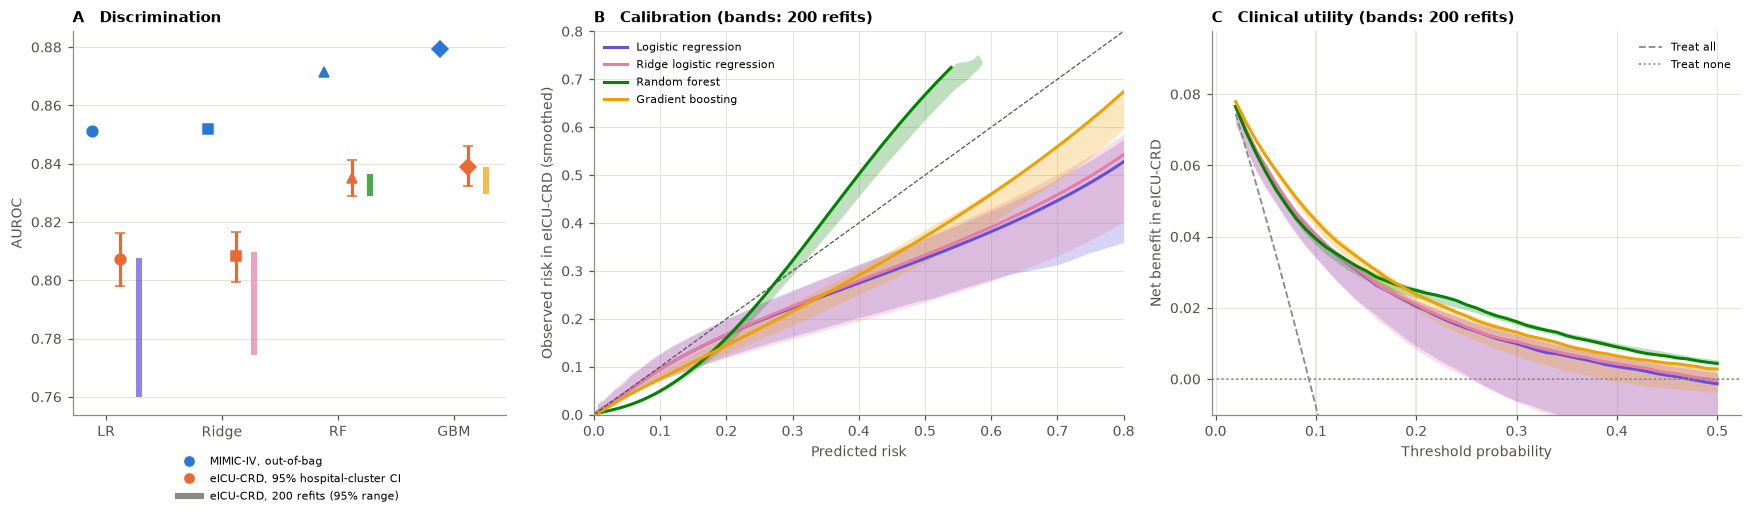

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [0.9, 1.1, 1.1]})
ax = axes[0]
for i, m in enumerate(MODELS_LIST):
    t = TABLE9[(TABLE9["model"] == m) & (TABLE9["metric"] == "auroc")].iloc[0]
    ax.errorbar(i - 0.12, t["development_oob"], fmt=MODEL_MARKERS[m], color=DB_COLORS["MIMIC-IV"], markersize=7)
    ax.errorbar(i + 0.12, t["external"], yerr=[[t["external"] - t["lower"]], [t["upper"] - t["external"]]], fmt=MODEL_MARKERS[m],
                color=DB_COLORS["eICU-CRD"], markersize=7, capsize=3)
    ax.vlines(i + 0.28, t["refits_lower"], t["refits_upper"], color=MODEL_COLORS[m], lw=4, alpha=0.7)
ax.set_xticks(range(len(MODELS_LIST)))
ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
ax.set_ylabel("AUROC")
ax.set_title("Discrimination")
B_FULL = FULL_RES[MODELS_LIST[0]].n_replicates
ax.legend(handles=[Line2D([0], [0], color=DB_COLORS["MIMIC-IV"], marker="o", lw=0, label="MIMIC-IV, out-of-bag"),
                   Line2D([0], [0], color=DB_COLORS["eICU-CRD"], marker="o", lw=0, label="eICU-CRD, 95% hospital-cluster CI"),
                   Line2D([0], [0], color=NEUTRAL, lw=4, label=f"eICU-CRD, {B_FULL} refits (95% range)")],
          fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1)
ax.grid(axis="x", visible=False)
panel_label(ax, "A")

ax = axes[1]
grid = np.linspace(0.005, 0.8, 120)
for m, res in FULL_RES.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        ci = res.calibration_instability(population="external", grid=grid, method="spline")
        reps = np.vstack(ci["replicates"])
        band = np.nanquantile(reps, [0.025, 0.975], axis=0)
    ax.fill_between(ci["predicted"], band[0], band[1], color=MODEL_COLORS[m], alpha=0.25, lw=0)
    ax.plot(ci["predicted"], ci["original"], color=MODEL_COLORS[m], lw=2, label=MODEL_LABELS[m])
ax.plot([0, 0.8], [0, 0.8], color=INK2, lw=0.8, ls="--")
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 0.8)
ax.set_xlabel("Predicted risk")
ax.set_ylabel("Observed risk in eICU-CRD (smoothed)")
ax.set_title(f"Calibration (bands: {B_FULL} refits)")
ax.legend(fontsize=7.5, loc="upper left")
panel_label(ax, "B")

ax = axes[2]
ths = np.round(np.linspace(0.02, 0.5, 49), 3)
for m, res in FULL_RES.items():
    dc = res.decision_curve_instability(population="external", thresholds=ths)
    rep = dc[dc["strategy"] == "replicate"].pivot_table(index="threshold", columns="replicate", values="net_benefit")
    ax.fill_between(rep.index, rep.quantile(0.025, axis=1), rep.quantile(0.975, axis=1), color=MODEL_COLORS[m], alpha=0.25, lw=0)
    g = dc[dc["strategy"] == "original"]
    ax.plot(g["threshold"], g["net_benefit"], color=MODEL_COLORS[m], lw=2)
g = dc[dc["strategy"] == "treat_all"]
ax.plot(g["threshold"], g["net_benefit"], color=NEUTRAL, ls="--", lw=1.2, label="Treat all")
ax.axhline(0, color=NEUTRAL, ls=":", lw=1.2, label="Treat none")
for t in THRESHOLDS:
    ax.axvline(t, color=GRID, lw=1, zorder=0)
ax.set_ylim(-0.01, PREV_EXT * 1.05)
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit in eICU-CRD")
ax.set_title(f"Clinical utility (bands: {B_FULL} refits)")
ax.legend(fontsize=7.5, loc="upper right")
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p3_fig1_external_performance", "External discrimination, calibration and net benefit in eICU-CRD")

## 4. Does instability transport? (Figure P3-2)

For development patients the reference is the out-of-bag SD (refits that did not see the patient); for eICU-CRD patients all refits are unseen. The same risk standardisation is applied to decisions: the **decision instability ratio** (DIR) divides the number of decision-unstable eICU-CRD patients by the number expected if each had the development decision instability of MIMIC-IV patients at the same risk, so that differences in how many patients sit near the threshold are removed. Table 10b asks whether decision-unstable patients are also those whose risk is estimated worst (calibration and Brier score within the stable and unstable groups). **A.** Mean SD of predicted risk by predicted-risk bin in MIMIC-IV (dashed) and eICU-CRD (solid). **B.** Instability transport ratio with 95% hospital-cluster bootstrap interval. **C.** Decision-unstable patients per 1,000 at each threshold in the two populations.

In [10]:
DEV_OOB, EXT_S, EXPECTED_SD, ITR, INBAG = {}, {}, {}, {}, {}
with timed("Instability in development (out-of-bag) and external populations"):
    for m, res in FULL_RES.items():
        INBAG[m] = inbag_matrix(res)
        DEV_OOB[m] = spread_summary(res.P, ref=res.p_original, use=~INBAG[m])
        EXT_S[m] = spread_summary(res.P_external, ref=res.p_original_external)
        ok = DEV_OOB[m]["n_models"] >= 5
        EXPECTED_SD[m] = risk_curve(DEV_OOB[m]["mean"][ok], DEV_OOB[m]["sd"][ok])
        dev_uns = (DEV_OOB[m][f"minority_emp@{T0:g}"] > UNSTABLE).astype(np.float64)
        ITR[m] = {"expected_sd": EXPECTED_SD[m](EXT_S[m]["mean"]), "dev_ok": ok,
                  "expected_unstable": np.clip(risk_curve(DEV_OOB[m]["mean"][ok], dev_uns[ok])(EXT_S[m]["mean"]), 0, 1),
                  "unstable": (EXT_S[m][f"minority_emp@{T0:g}"] > UNSTABLE).astype(np.float64)}


def ratio_ci(num, den, n_boot, seed):
    rng = np.random.default_rng(seed)
    rows = [r for r in HOSP_ROWS if r.size]
    sums_n = np.array([num[r].sum() for r in rows])
    sums_d = np.array([den[r].sum() for r in rows])
    boots = np.full(n_boot, np.nan)
    for b in range(n_boot):
        pick = rng.integers(0, len(rows), len(rows))
        d_b = sums_d[pick].sum()
        if d_b > 0:
            boots[b] = sums_n[pick].sum() / d_b
    if np.isfinite(boots).sum() < 0.9 * n_boot:
        return num.sum() / den.sum(), np.nan, np.nan
    return num.sum() / den.sum(), np.nanquantile(boots, 0.025), np.nanquantile(boots, 0.975)


trans_rows = []
for m, res in FULL_RES.items():
    est, lo, hi = ratio_ci(EXT_S[m]["sd"], ITR[m]["expected_sd"], CONFIG["cluster_boot"], seed_for(m, "itr"))
    ITR[m].update({"itr": est, "lower": lo, "upper": hi})
    dir_est, dir_lo, dir_hi = ratio_ci(ITR[m]["unstable"], ITR[m]["expected_unstable"], CONFIG["cluster_boot"], seed_for(m, "dir"))
    ITR[m].update({"dir": dir_est, "dir_lower": dir_lo, "dir_upper": dir_hi})
    d, e = population_summary(DEV_OOB[m]), population_summary(EXT_S[m])
    row = {"model": MODEL_LABELS[m], "itr": est, "itr_lower": lo, "itr_upper": hi,
           "decision_instability_ratio": dir_est, "dir_lower": dir_lo, "dir_upper": dir_hi,
           "mean_sd_development_oob": d["mean_sd"], "mean_sd_external": e["mean_sd"],
           "instability_index_external": e["instability_index"], "share_wide_external": e["share_wide"],
           "mean_risk_development": res.p_original.mean(), "mean_risk_external": res.p_original_external.mean()}
    for t in THRESHOLDS:
        row[f"unstable_per_1000_development@{t:g}"] = 1000 * d[f"share_unstable_emp@{t:g}"]
        row[f"unstable_per_1000_external@{t:g}"] = 1000 * e[f"share_unstable_emp@{t:g}"]
    trans_rows.append(row)
TABLE10 = pd.DataFrame(trans_rows)
save_table(TABLE10.round(5), "table10_instability_transport", "Instability in MIMIC-IV (out-of-bag) and eICU-CRD and the instability transport ratio")
display(TABLE10.round(4))

# Are decision-unstable patients also the ones the model gets wrong? (aggregates only)
rows = []
for m, res in FULL_RES.items():
    uns = EXT_S[m][f"minority_emp@{T0:g}"] > UNSTABLE
    for label, sel in (("decision-stable", ~uns), ("decision-unstable", uns)):
        if sel.sum() < 20:
            continue
        y, p = y_ext[sel], res.p_original_external[sel]
        rows.append({"model": MODEL_LABELS[m], "group": label, "patients": int(sel.sum()), "deaths": int(y.sum()),
                     "observed_mortality": y.mean(), "mean_predicted": p.mean(), "oe_ratio": y.sum() / p.sum(),
                     "brier": float(np.mean((y - p) ** 2)), "auroc_within_group": auc_fast(y, p),
                     "flagged_share": float(np.mean(p >= T0))})
TABLE10B = pd.DataFrame(rows)
save_table(TABLE10B.round(4), "table10b_outcomes_by_stability", "Observed and predicted mortality in decision-stable and decision-unstable eICU-CRD patients")
display(TABLE10B.round(3))


>>> Instability in development (out-of-bag) and external populations
<<< Instability in development (out-of-bag) and external populations: 0.2 min


,model,itr,itr_lower,itr_upper,decision_instability_ratio,dir_lower,dir_upper,mean_sd_development_oob,mean_sd_external,instability_index_external,share_wide_external,mean_risk_development,mean_risk_external,unstable_per_1000_development@0.1,unstable_per_1000_external@0.1,unstable_per_1000_development@0.2,unstable_per_1000_external@0.2,unstable_per_1000_development@0.3,unstable_per_1000_external@0.3
0,Logistic regression,3.0403,2.7480,3.3428,2.8062,2.5652,3.0776,0.0103,0.0365,0.0283,0.4484,0.0973,0.1162,77.1406,249.7716,49.2919,168.4234,32.3775,114.9563
1,Ridge logistic regression,2.9261,2.6775,3.1827,2.8564,2.6039,3.1310,0.0099,0.0340,0.0269,0.4240,0.0972,0.1154,75.6393,251.1104,47.9908,165.0764,31.2766,110.9399
2,Random forest,0.9781,0.9733,0.9822,0.9772,0.9703,0.9837,0.0121,0.0143,0.0132,0.0700,0.0976,0.1188,113.0961,152.8253,73.7127,102.1952,35.8805,41.5135
3,Gradient boosting,1.1031,1.0927,1.1160,1.0942,1.0824,1.1078,0.0245,0.0359,0.0322,0.4648,0.0973,0.1241,149.6522,227.1076,115.9235,184.9353,89.0757,135.9734


,model,group,patients,deaths,observed_mortality,mean_predicted,oe_ratio,brier,auroc_within_group,flagged_share
0,Logistic regression,decision-stable,70607,6533,0.093,0.116,0.799,0.071,0.845,0.262
1,Logistic regression,decision-unstable,23507,2220,0.094,0.117,0.804,0.085,0.609,0.497
2,Ridge logistic regression,decision-stable,70481,6492,0.092,0.115,0.801,0.070,0.848,0.259
3,Ridge logistic regression,decision-unstable,23633,2261,0.096,0.117,0.820,0.086,0.605,0.507
4,Random forest,decision-stable,79731,8072,0.101,0.122,0.829,0.074,0.845,0.473
5,Random forest,decision-unstable,14383,681,0.047,0.100,0.472,0.048,0.534,0.491
6,Gradient boosting,decision-stable,72740,7044,0.097,0.128,0.756,0.069,0.873,0.316
7,Gradient boosting,decision-unstable,21374,1709,0.080,0.110,0.726,0.075,0.543,0.537


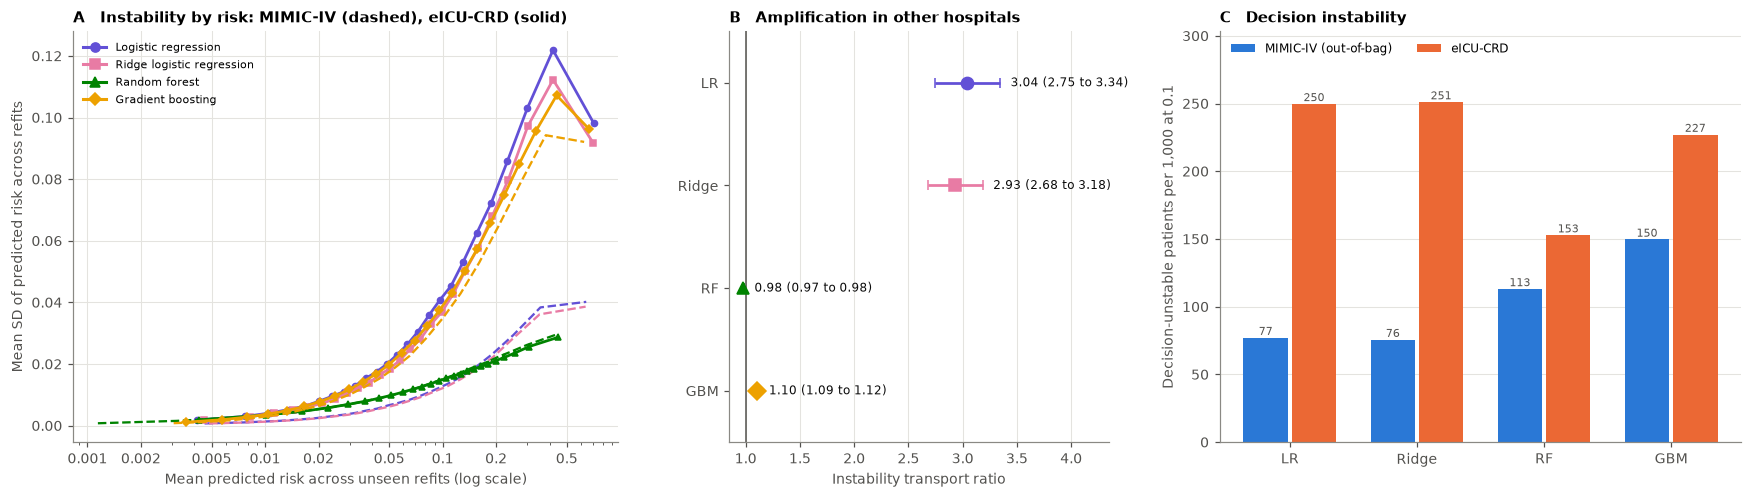

In [11]:
def binned_curve(x, y, n_bins=25):
    L = logit(x)
    edges = np.unique(np.quantile(L, np.linspace(0, 1, n_bins + 1)))
    b = np.clip(np.searchsorted(edges, L, side="right") - 1, 0, len(edges) - 2)
    cnt = np.bincount(b, minlength=len(edges) - 1)
    ok = cnt > 0
    return (np.bincount(b, weights=x, minlength=len(edges) - 1)[ok] / cnt[ok],
            np.bincount(b, weights=y, minlength=len(edges) - 1)[ok] / cnt[ok])


fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.15, 0.8, 1.1]})
ax = axes[0]
for m, res in FULL_RES.items():
    ok = ITR[m]["dev_ok"]
    xd, yd = binned_curve(DEV_OOB[m]["mean"][ok], DEV_OOB[m]["sd"][ok])
    xe, ye = binned_curve(EXT_S[m]["mean"], EXT_S[m]["sd"])
    ax.plot(xd, yd, color=MODEL_COLORS[m], ls="--", lw=1.5)
    ax.plot(xe, ye, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=4, lw=1.8)
ax.set_xscale("log")
plain_log_axis(ax.xaxis, fmt="{:g}")
ax.set_xlabel("Mean predicted risk across unseen refits (log scale)")
ax.set_ylabel("Mean SD of predicted risk across refits")
ax.set_title("Instability by risk: MIMIC-IV (dashed), eICU-CRD (solid)")
ax.legend(handles=model_handles(MODELS_LIST), fontsize=7.5, loc="upper left")
panel_label(ax, "A")

ax = axes[1]
for i, m in enumerate(MODELS_LIST):
    r = ITR[m]
    ax.errorbar(r["itr"], i, xerr=[[r["itr"] - r["lower"]], [r["upper"] - r["itr"]]], fmt=MODEL_MARKERS[m],
                color=MODEL_COLORS[m], markersize=8, capsize=3, lw=1.8)
    ax.annotate(f"{r['itr']:.2f} ({r['lower']:.2f} to {r['upper']:.2f})", (r["upper"], i), xytext=(7, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axvline(1, color=INK2, lw=1)
ax.set_yticks(range(len(MODELS_LIST)))
ax.set_yticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
lo = min(ITR[m]["lower"] for m in MODELS_LIST)
hi = max(ITR[m]["upper"] for m in MODELS_LIST)
ax.set_xlim(min(lo * 0.9, 0.85), max(hi, 1.05) * 1.3)
ax.set_ylim(len(MODELS_LIST) - 0.5, -0.5)
ax.set_xlabel("Instability transport ratio")
ax.set_title("Amplification in other hospitals")
ax.grid(axis="y", visible=False)
panel_label(ax, "B")

ax = axes[2]
width = 0.38
xs = np.arange(len(MODELS_LIST))
for j, (pop, color) in enumerate((("development", DB_COLORS["MIMIC-IV"]), ("external", DB_COLORS["eICU-CRD"]))):
    vals = [TABLE10.loc[TABLE10["model"] == MODEL_LABELS[m], f"unstable_per_1000_{pop}@{T0:g}"].iloc[0] for m in MODELS_LIST]
    ax.bar(xs + (j - 0.5) * width, vals, width=width - 0.03, color=color, label="MIMIC-IV (out-of-bag)" if j == 0 else "eICU-CRD")
    for x, v in zip(xs + (j - 0.5) * width, vals):
        ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax.set_xticks(xs)
ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
ax.set_ylabel(f"Decision-unstable patients per 1,000 at {T0:g}")
ax.set_title("Decision instability")
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
ax.legend(fontsize=8, loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p3_fig2_instability_transport", "Instability in development and external populations and the instability transport ratio")

## 5. Hospital-level heterogeneity (Figures P3-3, P3-S1; Table 11)

For each hospital with at least 100 eligible stays and each model: discrimination, calibration, instability transport ratio, share of decision-unstable patients, and the range of the hospital's flag rate across the 200 refits (how many of its patients would be flagged depends on the development sample). Random-effects meta-analysis (REML, Hartung-Knapp-style t quantile for the prediction interval) gives the average, its 95% confidence interval and the 95% **prediction interval**, the range expected in a new hospital (TRIPOD-Cluster).

Standard errors: AUROC by Hanley and McNeil on the logit scale; log O/E as sqrt((1 - O/N)/O); calibration slope from the observed information (hospitals with at least 10 events and 10 non-events); log ITR by the delta method for a ratio of paired means; decision-unstable share on the logit scale with a 0.5 continuity correction.

In [12]:
def reml_meta(yi, vi):
    yi, vi = np.asarray(yi, float), np.asarray(vi, float)
    ok = np.isfinite(yi) & np.isfinite(vi) & (vi > 0)
    yi, vi = yi[ok], vi[ok]
    k = yi.size
    if k < 3:
        return {"k": k}

    def nll(tau2):
        w = 1 / (vi + tau2)
        mu = np.sum(w * yi) / np.sum(w)
        return 0.5 * (np.sum(np.log(vi + tau2)) + math.log(np.sum(w)) + np.sum(w * (yi - mu) ** 2))

    upper = max(10 * np.var(yi), 10 * np.max(vi), 1e-6)
    opt = minimize_scalar(nll, bounds=(0, upper), method="bounded", options={"xatol": 1e-10})
    tau2 = opt.x if opt.fun < nll(0.0) else 0.0
    w = 1 / (vi + tau2)
    mu = np.sum(w * yi) / np.sum(w)
    se = math.sqrt(1 / np.sum(w))
    tcrit = student_t.ppf(0.975, max(k - 2, 1))
    wf = 1 / vi
    s2 = (k - 1) * wf.sum() / (wf.sum() ** 2 - (wf ** 2).sum())
    return {"k": k, "mu": mu, "se": se, "lower": mu - 1.96 * se, "upper": mu + 1.96 * se,
            "pi_lower": mu - tcrit * math.sqrt(tau2 + se ** 2), "pi_upper": mu + tcrit * math.sqrt(tau2 + se ** 2),
            "tau2": tau2, "tau": math.sqrt(tau2), "i2": tau2 / (tau2 + s2)}


def auc_se(a, n1, n0):
    q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
    return math.sqrt(max((a * (1 - a) + (n1 - 1) * (q1 - a * a) + (n0 - 1) * (q2 - a * a)) / (n1 * n0), 1e-12))


def clean_level(v, dim=None):
    v = str(v).strip()
    if v.lower() in ("", "nan", "none", "<na>"):
        return "Unknown"
    if dim == "hospital_teaching":
        return {"t": "Yes", "f": "No", "true": "Yes", "false": "No", "1": "Yes", "0": "No"}.get(v.lower(), v)
    if dim == "sex":
        return {"f": "Female", "m": "Male"}.get(v.lower(), v)
    return v


LEVEL_ORDER = {"hospital_beds": ["<100", "100 - 249", "250 - 499", ">= 500"], "age_band": ["18-49", "50-64", "65-79", "80+"]}


def ordered_levels(dim, values):
    present = list(pd.unique(values))
    pref = [v for v in LEVEL_ORDER.get(dim, []) if v in present]
    rest = sorted(v for v in present if v not in pref and v != "Unknown")
    return pref + rest + (["Unknown"] if "Unknown" in present else [])


motor_missing = ext.groupby("site_id")["gcs_motor_min"].apply(lambda s: s.isna().mean())
hosp_char = ext.groupby("site_id")[["hospital_region", "hospital_teaching", "hospital_beds"]].first()
hosp_char = hosp_char.apply(lambda c: c.map(lambda v: clean_level(v, c.name)))


def hospital_table(m, min_stays, p=None, P=None, s=None, exp_sd=None, exp_uns=None):
    res = FULL_RES[m]
    p = res.p_original_external if p is None else p
    P = res.P_external if P is None else P
    s = EXT_S[m] if s is None else s
    exp_sd = ITR[m]["expected_sd"] if exp_sd is None else exp_sd
    exp_uns = ITR[m]["expected_unstable"] if exp_uns is None else exp_uns
    rows = []
    for h, idx in enumerate(HOSP_ROWS):
        if idx.size < min_stays:
            continue
        y, ph = y_ext[idx], p[idx]
        n1 = int(y.sum())
        n0 = idx.size - n1
        row = {"model": m, "site_id": HOSP_CODES[h], "n": idx.size, "events": n1}
        if n1 >= 1 and n0 >= 1:
            a = auc_fast(y, ph)
            if 0 < a < 1:
                row.update({"auroc": a, "logit_auroc": math.log(a / (1 - a)), "se_logit_auroc": auc_se(a, n1, n0) / (a * (1 - a))})
        if n1 >= 1:
            oe = n1 / ph.sum()
            row.update({"oe": oe, "log_oe": math.log(oe), "se_log_oe": math.sqrt(max(1 - n1 / idx.size, 1e-9) / n1)})
        if n1 >= CONFIG["min_events_slope"] and n0 >= CONFIG["min_events_slope"]:
            sl, se_sl = logistic_fit(y, logit(ph))
            row.update({"slope": sl, "se_slope": se_sl})
        sd_h, ex_h = s["sd"][idx], exp_sd[idx]
        itr = sd_h.sum() / ex_h.sum()
        d = sd_h / sd_h.mean() - ex_h / ex_h.mean()
        row.update({"itr": itr, "log_itr": math.log(itr), "se_log_itr": float(d.std(ddof=1) / math.sqrt(idx.size)),
                    "mape": float(s["mape"][idx].mean())})
        u = float(np.mean(s[f"minority_emp@{T0:g}"][idx] > UNSTABLE))
        uc = (u * idx.size + 0.5) / (idx.size + 1)
        row.update({"unstable_share": u, "logit_unstable": math.log(uc / (1 - uc)),
                    "se_logit_unstable": math.sqrt(1 / (idx.size * uc * (1 - uc)))})
        o_u, e_u = u * idx.size, float(exp_uns[idx].sum())
        row.update({"expected_unstable_share": e_u / idx.size, "dir": o_u / e_u if e_u > 0 else np.nan,
                    "log_dir": math.log((o_u + 0.5) / (e_u + 0.5)),
                    "se_log_dir": math.sqrt(max(1 - (o_u + 0.5) / (idx.size + 1), 1e-9) / (o_u + 0.5))})
        rates = (P[:, idx] >= T0).mean(axis=1)
        row.update({"flag_rate_original": float(np.mean(ph >= T0)), "flag_rate_lower": float(np.quantile(rates, 0.025)),
                    "flag_rate_upper": float(np.quantile(rates, 0.975))})
        rows.append(row)
    out = pd.DataFrame(rows)
    out["gcs_motor_missing"] = out["site_id"].map(motor_missing)
    return out.join(hosp_char, on="site_id")


META_SPEC = {"AUROC": ("logit_auroc", "se_logit_auroc", expit), "O/E": ("log_oe", "se_log_oe", np.exp),
             "Calibration slope": ("slope", "se_slope", lambda v: v), "Instability transport ratio": ("log_itr", "se_log_itr", np.exp),
             f"Decision-unstable share at {T0:g}": ("logit_unstable", "se_logit_unstable", expit),
             "Decision instability ratio": ("log_dir", "se_log_dir", np.exp)}


def meta_table(hosp, label):
    rows = []
    for metric, (est, se, back) in META_SPEC.items():
        if est not in hosp:
            continue
        r = reml_meta(hosp[est], hosp[se] ** 2)
        if r.get("k", 0) < 3:
            continue
        rows.append({"model": label, "metric": metric, "hospitals": r["k"], "pooled": back(r["mu"]), "lower": back(r["lower"]),
                     "upper": back(r["upper"]), "pi_lower": back(r["pi_lower"]), "pi_upper": back(r["pi_upper"]),
                     "tau": r["tau"], "i2": r["i2"]})
    return pd.DataFrame(rows)


with timed("Hospital-level analysis"):
    HOSP_T = {m: hospital_table(m, CONFIG["min_hospital_stays"]) for m in MODELS_LIST}
    HOSP_T50 = {m: hospital_table(m, CONFIG["min_hospital_stays_sensitivity"]) for m in MODELS_LIST}
HOSP_ALL = pd.concat(HOSP_T.values(), ignore_index=True)
HOSP_ALL["hospital_rank"] = HOSP_ALL.groupby("model")["n"].rank(ascending=False, method="first").astype(int)
save_table(HOSP_ALL.drop(columns="site_id").assign(model=HOSP_ALL["model"].map(MODEL_LABELS)).round(5),
           "tableS_p3_hospital_level", "Hospital-level performance and instability (hospitals identified by size rank only)")
TABLE11 = pd.concat([meta_table(HOSP_T[m], m) for m in MODELS_LIST], ignore_index=True)
save_table(TABLE11.assign(model=TABLE11["model"].map(MODEL_LABELS)).round(4), "table11_hospital_meta_analysis",
           "Random-effects meta-analysis across hospitals: pooled estimate, 95% CI, 95% prediction interval, tau and I-squared")
n_h = len(HOSP_T[MODELS_LIST[0]])
print(f"Hospitals with at least {CONFIG['min_hospital_stays']} stays: {n_h} of {len(HOSP_CODES)} "
      f"({int(HOSP_T[MODELS_LIST[0]]['n'].sum()):,} of {N_EXT:,} stays)")
display(TABLE11.assign(model=TABLE11["model"].map(MODEL_SHORT)).round(3))


>>> Hospital-level analysis
<<< Hospital-level analysis: 0.1 min
Hospitals with at least 100 stays: 153 of 205 (92,071 of 94,114 stays)


,model,metric,hospitals,pooled,lower,upper,pi_lower,pi_upper,tau,i2
0,LR,AUROC,152,0.812,0.804,0.819,0.759,0.855,0.157,0.305
1,LR,O/E,152,0.741,0.693,0.791,0.357,1.535,0.367,0.894
2,LR,Calibration slope,137,0.815,0.789,0.842,0.624,1.006,0.096,0.453
3,LR,Instability transport ratio,153,2.669,2.469,2.884,1.015,7.017,0.488,0.998
4,LR,Decision-unstable share at 0.1,153,0.247,0.224,0.272,0.064,0.612,0.791,0.984
5,LR,Decision instability ratio,153,2.565,2.376,2.769,1.007,6.534,0.472,0.982
6,Ridge,AUROC,152,0.812,0.804,0.819,0.760,0.855,0.154,0.298
7,Ridge,O/E,152,0.743,0.697,0.793,0.364,1.519,0.360,0.890
8,Ridge,Calibration slope,137,0.829,0.803,0.855,0.645,1.013,0.092,0.425
9,Ridge,Instability transport ratio,153,2.606,2.411,2.817,0.990,6.860,0.488,0.999


**Figure P3-3.** Logistic regression in every eligible eICU-CRD hospital, hospitals ordered by their estimate (95% confidence intervals). Black line: random-effects pooled estimate; grey band: 95% prediction interval for a new hospital. Figure P3-S1 summarises the pooled estimates and prediction intervals for all four model classes.

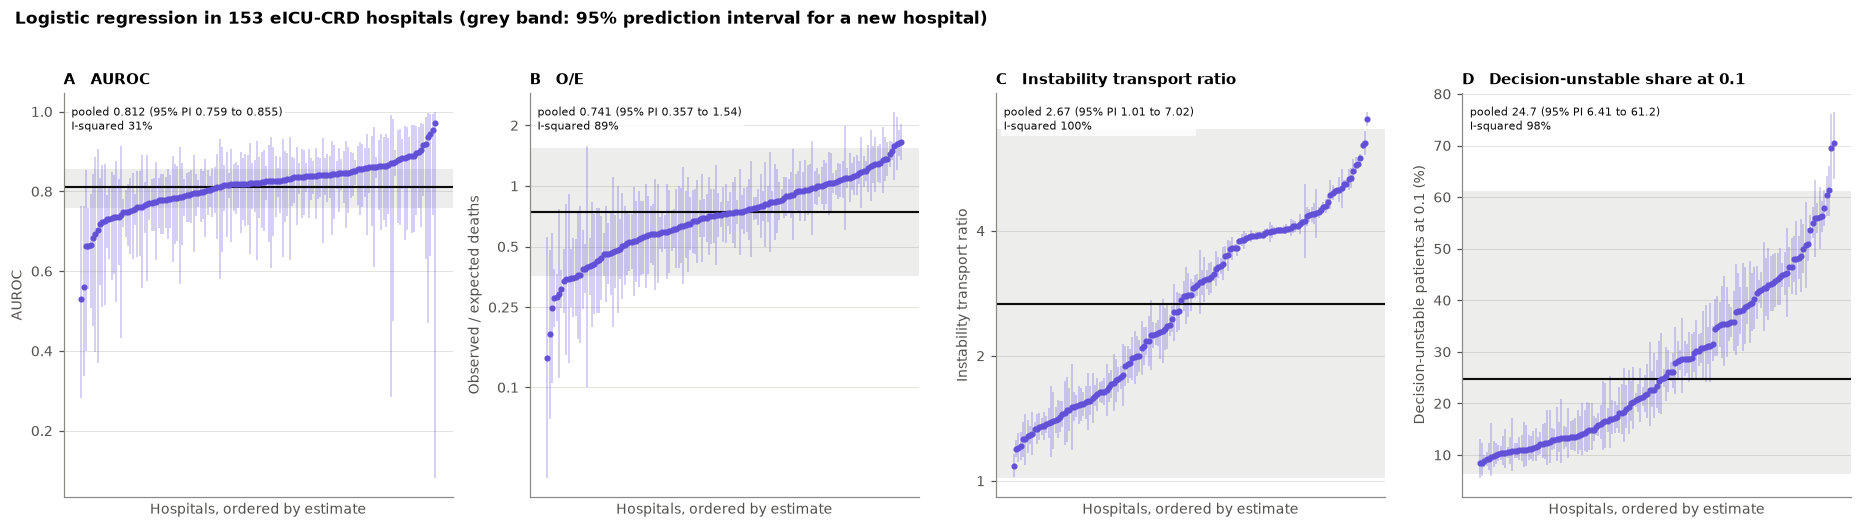

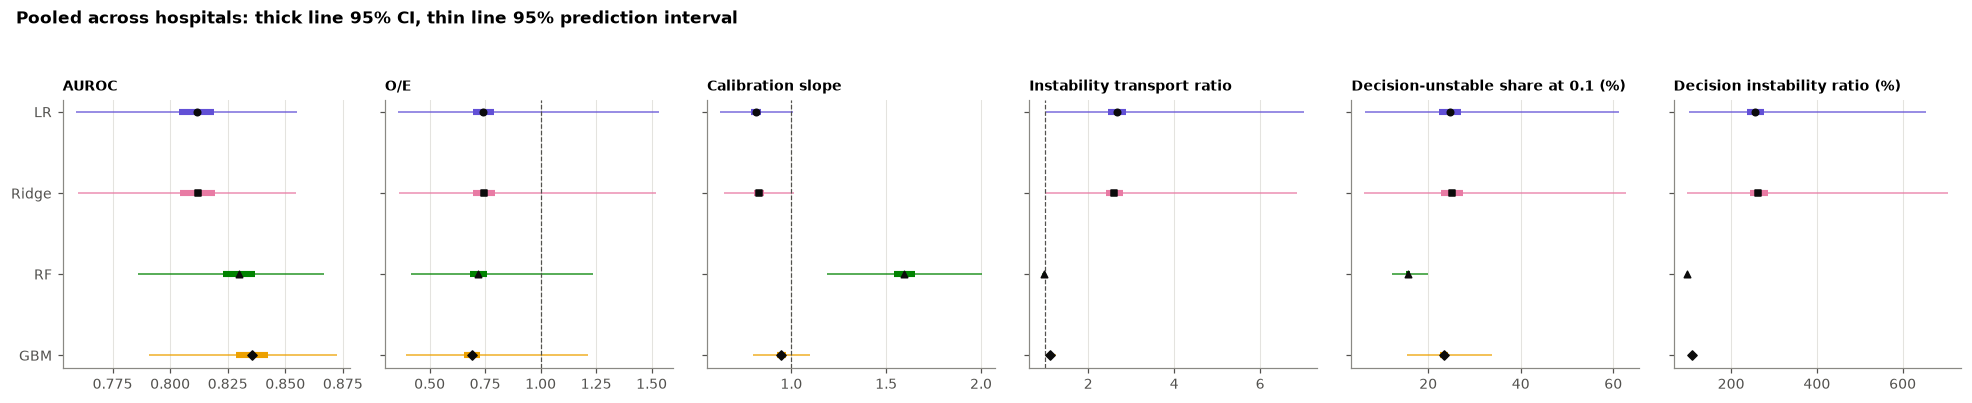

In [13]:
REF = "lr" if "lr" in MODELS_LIST else MODELS_LIST[0]
h = HOSP_T[REF]
meta_ref = TABLE11[TABLE11["model"] == REF].set_index("metric")


def hospital_ci(d, col):
    if col == "auroc":
        return expit(d["logit_auroc"] - 1.96 * d["se_logit_auroc"]), expit(d["logit_auroc"] + 1.96 * d["se_logit_auroc"])
    if col == "oe":
        return np.exp(d["log_oe"] - 1.96 * d["se_log_oe"]), np.exp(d["log_oe"] + 1.96 * d["se_log_oe"])
    if col == "itr":
        return np.exp(d["log_itr"] - 1.96 * d["se_log_itr"]), np.exp(d["log_itr"] + 1.96 * d["se_log_itr"])
    return expit(d["logit_unstable"] - 1.96 * d["se_logit_unstable"]), expit(d["logit_unstable"] + 1.96 * d["se_logit_unstable"])


panels = [("auroc", "AUROC", "AUROC", False), ("oe", "O/E", "Observed / expected deaths", True),
          ("itr", "Instability transport ratio", "Instability transport ratio", True),
          ("unstable_share", f"Decision-unstable share at {T0:g}", f"Decision-unstable patients at {T0:g} (%)", False)]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.6))
for ax, (col, metric, ylabel, logy), letter in zip(axes, panels, "ABCD"):
    d = h.dropna(subset=[col]).sort_values(col).reset_index(drop=True)
    scale = 100 if col == "unstable_share" else 1
    x = np.arange(len(d))
    lo, hi = hospital_ci(d, col)
    ax.vlines(x, scale * lo, scale * hi, color=MODEL_COLORS[REF], alpha=0.35, lw=1)
    ax.scatter(x, scale * d[col], s=9, color=MODEL_COLORS[REF], zorder=3)
    if metric in meta_ref.index:
        r = meta_ref.loc[metric]
        ax.axhspan(scale * r["pi_lower"], scale * r["pi_upper"], color=NEUTRAL, alpha=0.15, lw=0)
        ax.axhline(scale * r["pooled"], color=INK, lw=1.4)
        ax.text(0.02, 0.97, f"pooled {scale * r['pooled']:.3g} (95% PI {scale * r['pi_lower']:.3g} to {scale * r['pi_upper']:.3g})\n"
                            f"I-squared {100 * r['i2']:.0f}%", transform=ax.transAxes, va="top", fontsize=7.5, color=INK,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
    if logy:
        ratio_axis(ax, "y", float(np.nanmin(lo)), float(np.nanmax(hi)))
    ax.set_xlabel("Hospitals, ordered by estimate")
    ax.set_ylabel(ylabel)
    ax.set_title(metric)
    ax.set_xticks([])
    panel_label(ax, letter)
fig.suptitle(f"{MODEL_LABELS[REF]} in {len(h)} eICU-CRD hospitals (grey band: 95% prediction interval for a new hospital)",
             x=0.01, ha="left", y=1.03, fontweight="bold")
fig.tight_layout()
save_figure(fig, "p3_fig3_hospital_heterogeneity", "Hospital-level discrimination, calibration, instability transport and decision instability")

fig, axes = plt.subplots(1, len(META_SPEC), figsize=(18, 3.4), sharey=True)
for ax, metric in zip(axes, META_SPEC):
    sc = 100 if metric.startswith("Decision") else 1
    for i, m in enumerate(MODELS_LIST):
        r = TABLE11[(TABLE11["model"] == m) & (TABLE11["metric"] == metric)]
        if r.empty:
            continue
        r = r.iloc[0]
        ax.hlines(i, sc * r["pi_lower"], sc * r["pi_upper"], color=MODEL_COLORS[m], lw=1.2, alpha=0.7)
        ax.hlines(i, sc * r["lower"], sc * r["upper"], color=MODEL_COLORS[m], lw=4)
        ax.scatter(sc * r["pooled"], i, color=INK, s=18, zorder=3, marker=MODEL_MARKERS[m])
    if metric in ("O/E", "Instability transport ratio", "Calibration slope"):
        ax.axvline(1, color=INK2, lw=0.8, ls="--")
    ax.set_title(metric + (" (%)" if sc == 100 else ""), fontsize=9)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(MODELS_LIST)))
axes[0].set_yticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
axes[0].invert_yaxis()
fig.suptitle("Pooled across hospitals: thick line 95% CI, thin line 95% prediction interval", x=0.01, ha="left", y=1.06, fontweight="bold")
fig.tight_layout()
save_figure(fig, "p3_figS1_meta_analysis_summary", "Random-effects summaries with confidence and prediction intervals for all model classes")

### Two different failure modes (Figure P3-4)

Each dot is a hospital (area proportional to its number of stays). Horizontal axis: calibration (O/E; the shaded band from 0.8 to 1.25 is a conventional tolerance). Vertical axis: the hospital's **decision instability ratio**, the number of decision-unstable patients divided by the number expected from MIMIC-IV patients at the same risk (1 = as stable as in development). Hospitals are marked as having excess decision instability when the lower 95% limit of the ratio is above 1. Standard external validation only sees the horizontal axis. A weak correlation between the axes means that a calibration check cannot stand in for an instability audit.

*Note on the pre-specified version.* The plan fixed an absolute limit of 10% decision-unstable patients per hospital. In the full run that limit lay below the development level for most model classes, so almost every hospital exceeded it and the classification carried little information. The pre-specified counts are still saved (`tableS_p3_failure_modes_prespecified.csv`); the risk-standardised ratio was added after the first full run and is reported as a post hoc refinement.

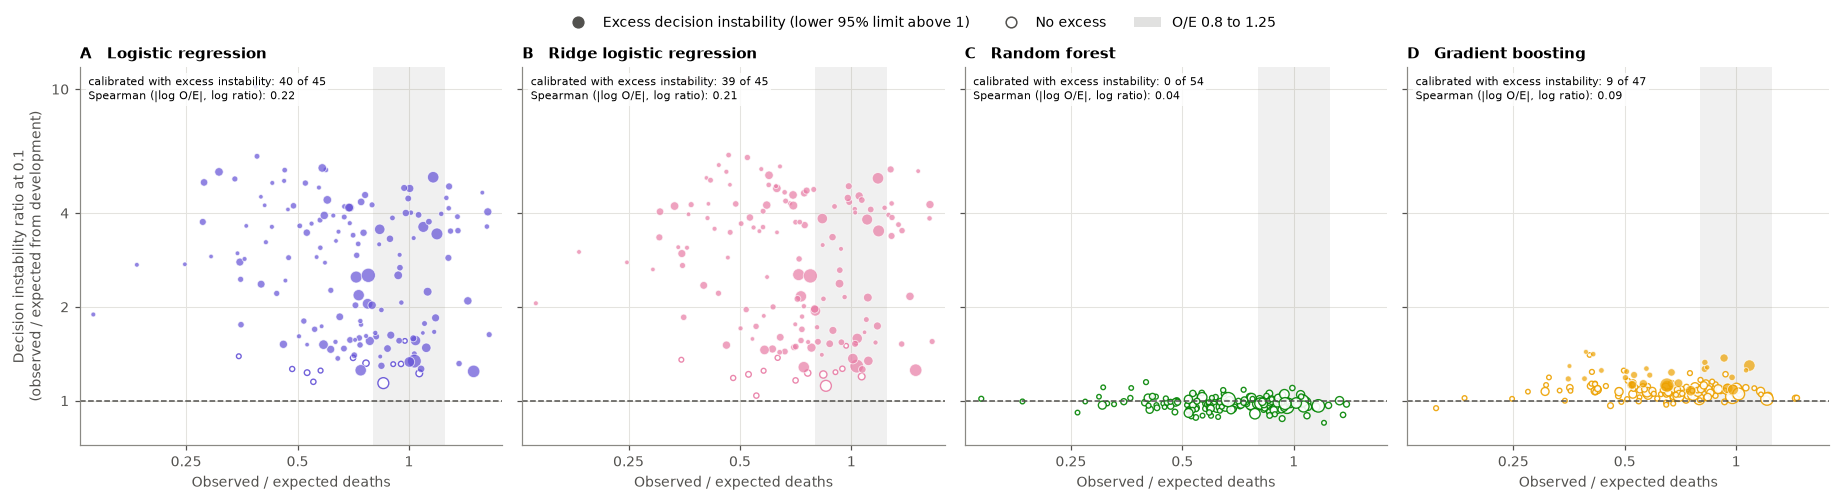

,model,hospitals,spearman_abs_log_oe_vs_log_dir,"calibrated, no excess","calibrated, excess instability","miscalibrated, no excess","miscalibrated, excess instability",share_of_calibrated_with_excess,share_of_all_with_excess
0,Logistic regression,152,0.219,5,40,7,100,0.889,0.921
1,Ridge logistic regression,152,0.207,6,39,8,99,0.867,0.908
2,Random forest,152,0.042,54,0,98,0,0.000,0.000
3,Gradient boosting,152,0.092,38,9,86,19,0.191,0.184


In [14]:
lo_b, hi_b = CONFIG["calibration_band"]
LIM = CONFIG["unstable_limit_hospital"]
pre_rows, fm_rows = [], []
for m in MODELS_LIST:
    d = HOSP_T[m].dropna(subset=["oe"])
    calibrated = d["oe"].between(lo_b, hi_b)
    unstable = d["unstable_share"] > LIM
    pre_rows.append({"model": MODEL_LABELS[m], "hospitals": len(d), "limit": LIM,
                     "calibrated and below limit": int((calibrated & ~unstable).sum()),
                     "calibrated and above limit": int((calibrated & unstable).sum()),
                     "miscalibrated and below limit": int((~calibrated & ~unstable).sum()),
                     "miscalibrated and above limit": int((~calibrated & unstable).sum())})
save_table(pd.DataFrame(pre_rows), "tableS_p3_failure_modes_prespecified", "Pre-specified classification with an absolute 10% limit")

oe_all = HOSP_ALL["oe"].dropna()
OE_LIM = (min(float(oe_all.min()), lo_b) * 0.92, max(float(oe_all.max()), hi_b) * 1.08)
dir_all = pd.concat([HOSP_T[m]["dir"] for m in MODELS_LIST]).replace(0, np.nan).dropna()
DIR_LIM = (min(float(dir_all.min()), 0.8) * 0.9, max(float(dir_all.max()), 1.25) * 1.1)
fig, axes = plt.subplots(1, len(MODELS_LIST), figsize=(4.2 * len(MODELS_LIST), 4.3), sharey=True)
for ax, m, letter in zip(np.atleast_1d(axes), MODELS_LIST, "ABCD"):
    d = HOSP_T[m].dropna(subset=["oe", "dir"])
    d = d[d["dir"] > 0]
    calibrated = d["oe"].between(lo_b, hi_b)
    excess = np.exp(d["log_dir"] - 1.96 * d["se_log_dir"]) > 1
    ax.axvspan(lo_b, hi_b, color=NEUTRAL, alpha=0.12, lw=0)
    ax.axhline(1, color=INK2, ls="--", lw=1)
    ax.scatter(d.loc[~excess, "oe"], d.loc[~excess, "dir"], s=6 + d.loc[~excess, "n"] / d["n"].max() * 80, facecolors="white",
               edgecolors=MODEL_COLORS[m], linewidths=0.9, alpha=0.9)
    ax.scatter(d.loc[excess, "oe"], d.loc[excess, "dir"], s=6 + d.loc[excess, "n"] / d["n"].max() * 80, color=MODEL_COLORS[m],
               alpha=0.7, edgecolors="white", linewidths=0.6)
    rho = spearmanr(np.abs(np.log(d["oe"])), np.log(d["dir"])).correlation
    counts = {"calibrated, no excess": int((calibrated & ~excess).sum()), "calibrated, excess instability": int((calibrated & excess).sum()),
              "miscalibrated, no excess": int((~calibrated & ~excess).sum()), "miscalibrated, excess instability": int((~calibrated & excess).sum())}
    fm_rows.append({"model": MODEL_LABELS[m], "hospitals": len(d), "spearman_abs_log_oe_vs_log_dir": rho, **counts,
                    "share_of_calibrated_with_excess": counts["calibrated, excess instability"] / max(int(calibrated.sum()), 1),
                    "share_of_all_with_excess": float(excess.mean())})
    ax.text(0.02, 0.98, f"calibrated with excess instability: {counts['calibrated, excess instability']} of {int(calibrated.sum())}\n"
                        f"Spearman (|log O/E|, log ratio): {rho:.2f}", transform=ax.transAxes, va="top", fontsize=7.5,
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))
    ratio_axis(ax, "x", *OE_LIM)
    ax.set_xlim(*OE_LIM)
    ratio_axis(ax, "y", *DIR_LIM)
    ax.set_ylim(*DIR_LIM)
    ax.set_xlabel("Observed / expected deaths")
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
np.atleast_1d(axes)[0].set_ylabel(f"Decision instability ratio at {T0:g}\n(observed / expected from development)")
fig.legend(handles=[Line2D([0], [0], marker="o", lw=0, color=INK2, markersize=7, label="Excess decision instability (lower 95% limit above 1)"),
                    Line2D([0], [0], marker="o", lw=0, markerfacecolor="white", markeredgecolor=INK2, markersize=7, label="No excess"),
                    Patch(facecolor=NEUTRAL, alpha=0.25, label=f"O/E {lo_b:g} to {hi_b:g}")],
           loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.06))
fig.tight_layout()
save_figure(fig, "p3_fig4_two_failure_modes", "Hospital-level calibration versus risk-standardised decision instability")
FAILURE_MODES = pd.DataFrame(fm_rows)
save_table(FAILURE_MODES.round(3), "tableS_p3_failure_modes", "Hospitals by calibration and excess decision instability (post hoc, risk-standardised)")
display(FAILURE_MODES.round(3))

### Flag-rate instability and hospital calibration plots (Figures P3-S2 and P3-S3)

**S2.** For each hospital, the share of its patients flagged at the primary threshold by the original model (dot) and the 95% range across the refits (line): the workload a hospital would plan for depends on the development sample. **S3.** Calibration of the reference model in the 12 largest hospitals (deciles of predicted risk, Wilson 95% intervals; hospitals identified by size rank only).

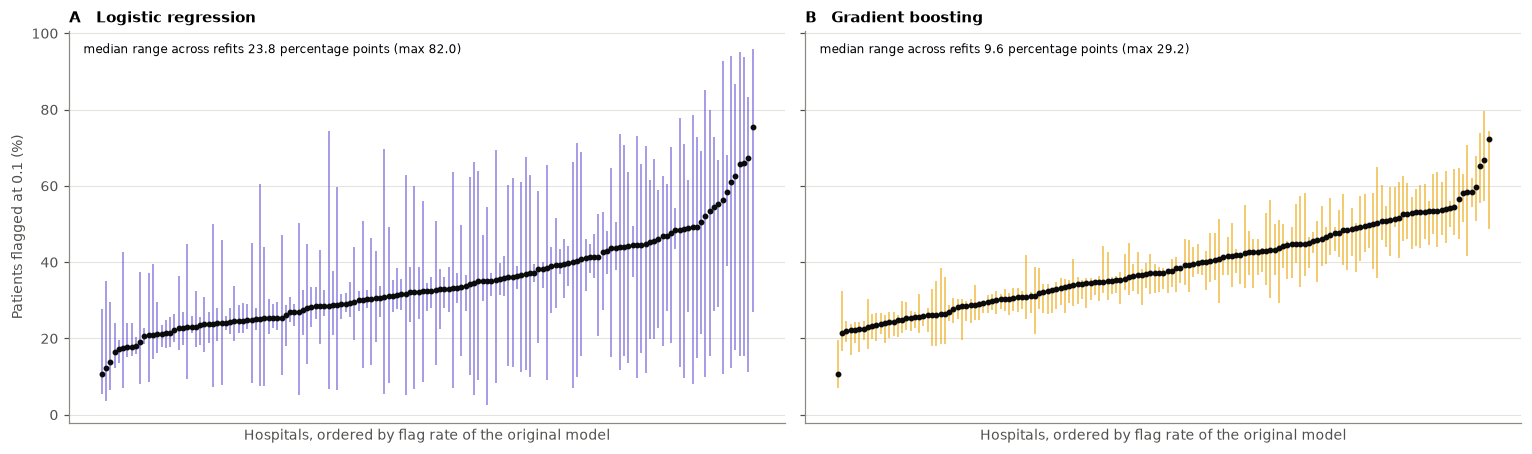

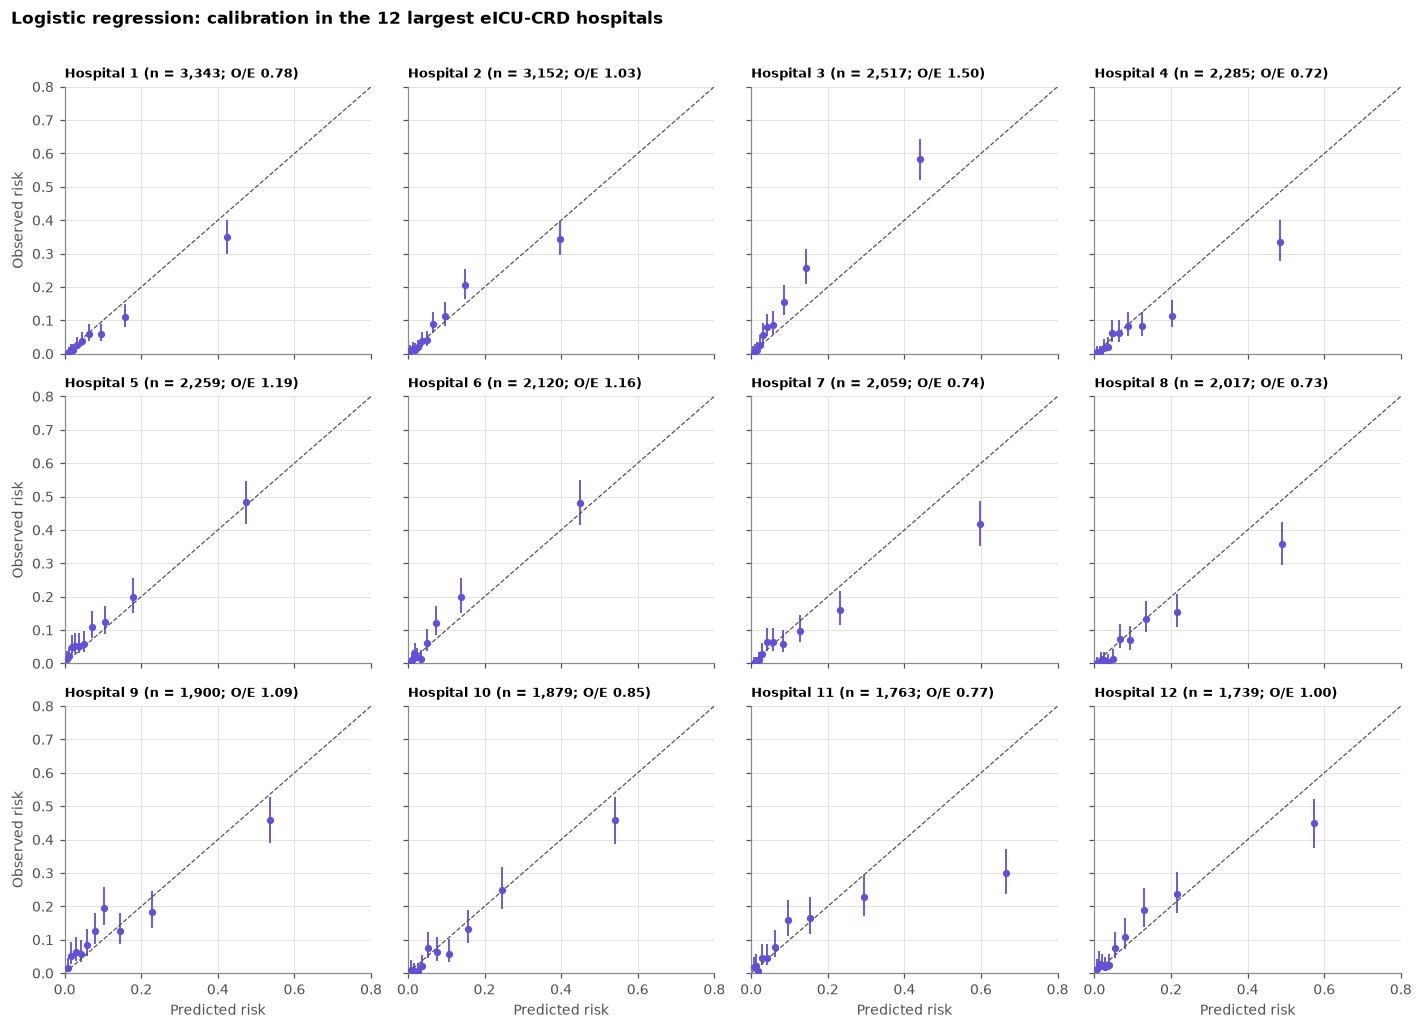

In [15]:
show = [m for m in ("lr", "hgb") if m in HOSP_T] or MODELS_LIST[:2]
fig, axes = plt.subplots(1, len(show), figsize=(7 * len(show), 4.2), sharey=True)
FLAG_RANGE = {}
for ax, m, letter in zip(np.atleast_1d(axes), show, "AB"):
    d = HOSP_T[m].sort_values("flag_rate_original").reset_index(drop=True)
    x = np.arange(len(d))
    ax.vlines(x, 100 * d["flag_rate_lower"], 100 * d["flag_rate_upper"], color=MODEL_COLORS[m], lw=1.2, alpha=0.6)
    ax.scatter(x, 100 * d["flag_rate_original"], s=8, color=INK, zorder=3)
    width = 100 * (d["flag_rate_upper"] - d["flag_rate_lower"])
    FLAG_RANGE[m] = {"median_points": float(width.median()), "max_points": float(width.max())}
    ax.text(0.02, 0.97, f"median range across refits {width.median():.1f} percentage points (max {width.max():.1f})",
            transform=ax.transAxes, va="top", fontsize=8)
    ax.set_xticks([])
    ax.set_xlabel("Hospitals, ordered by flag rate of the original model")
    ax.set_title(MODEL_LABELS[m])
    panel_label(ax, letter)
np.atleast_1d(axes)[0].set_ylabel(f"Patients flagged at {T0:g} (%)")
fig.tight_layout()
save_figure(fig, "p3_figS2_flag_rate_instability", "Hospital flag rates of the original model and their range across refits")


def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h_ = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return c - h_, c + h_


largest = HOSP_T[REF].dropna(subset=["oe"]).sort_values("n", ascending=False).head(12)
fig, axes = plt.subplots(3, 4, figsize=(13, 9.2), sharex=True, sharey=True)
top = [np.quantile(FULL_RES[REF].p_original_external[HOSP_ROWS[int(np.flatnonzero(HOSP_CODES == s)[0])]], 0.95) for s in largest["site_id"]]
pmax = float(min(1.0, max(0.4, math.ceil(max(top) * 10 + 1) / 10)))
for ax in axes.ravel()[len(largest):]:
    ax.set_visible(False)
for ax, (rank, row) in zip(axes.ravel(), enumerate(largest.itertuples(), start=1)):
    idx = HOSP_ROWS[int(np.flatnonzero(HOSP_CODES == row.site_id)[0])]
    p, y = FULL_RES[REF].p_original_external[idx], y_ext[idx]
    q = np.unique(np.quantile(p, np.linspace(0, 1, 11)))
    b = np.clip(np.searchsorted(q, p, side="right") - 1, 0, len(q) - 2)
    for k in range(len(q) - 1):
        sel = b == k
        if sel.sum() < 5:
            continue
        lo, hi = wilson(y[sel].sum(), sel.sum())
        ax.vlines(p[sel].mean(), lo, hi, color=MODEL_COLORS[REF], lw=1.2)
        ax.scatter(p[sel].mean(), y[sel].mean(), color=MODEL_COLORS[REF], s=14, zorder=3)
    ax.plot([0, pmax], [0, pmax], color=INK2, ls="--", lw=0.8)
    ax.set_xlim(0, pmax)
    ax.set_ylim(0, pmax)
    ax.set_title(f"Hospital {rank} (n = {row.n:,}; O/E {row.oe:.2f})", fontsize=8.5)
for ax in axes[-1]:
    ax.set_xlabel("Predicted risk")
for ax in axes[:, 0]:
    ax.set_ylabel("Observed risk")
fig.suptitle(f"{MODEL_LABELS[REF]}: calibration in the 12 largest eICU-CRD hospitals", x=0.01, ha="left", y=1.01, fontweight="bold")
fig.tight_layout()
save_figure(fig, "p3_figS3_hospital_calibration", "Calibration of the reference model in the 12 largest eICU-CRD hospitals")

## 6. Why: patients and hospitals unlike the development population (Figure P3-5, Table 12)

A membership model learns to tell eICU-CRD patients from MIMIC-IV patients from all 53 predictors and their missingness (gradient boosting, 5-fold cross-fitting, so no patient is scored by a model that saw them). Its AUROC measures how different the two populations are. For each eICU-CRD patient, the log density ratio log[P(eICU | x) / P(MIMIC | x)] minus the log ratio of cohort sizes measures how atypical that patient is of the development data. If extra instability comes from extrapolation, the instability transport ratio should rise with atypicality, for patients and for hospitals.

In [16]:
def domain_task(train_idx, test_idx, seed, X, z):
    clf = HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=50,
                                         l2_regularization=1.0, early_stopping=False, random_state=seed % (2**31 - 1))
    clf.fit(X[train_idx], z[train_idx])
    return test_idx, clf.predict_proba(X[test_idx])[:, 1]


dpath = CACHE / "domain_oof.npy"
X_all = np.vstack([X_dev, X_ext])
z_all = np.r_[np.zeros(N_DEV, int), np.ones(N_EXT, int)]
with timed("Membership model (MIMIC-IV versus eICU-CRD)"):
    if CONFIG["force"] or not dpath.exists():
        folds = StratifiedKFold(CONFIG["domain_folds"], shuffle=True, random_state=seed_for("domain") % (2**31 - 1))
        outs = run_parallel([delayed(domain_task)(tr, te, seed_for("domain", k), X_all, z_all)
                             for k, (tr, te) in enumerate(folds.split(X_all, z_all))])
        oof = np.empty(len(z_all))
        for te, p in outs:
            oof[te] = p
        np.save(dpath, oof)
    OOF = np.load(dpath)
DOMAIN_AUROC = auc_fast(z_all, OOF)
OOF_C = np.clip(OOF, 1e-6, 1 - 1e-6)
LOG_DR = np.log(OOF_C / (1 - OOF_C)) - math.log(N_EXT / N_DEV)
ATYP = LOG_DR[N_DEV:]
ATYP_DEV = LOG_DR[:N_DEV]
DECILE = np.clip(np.searchsorted(np.quantile(ATYP, np.linspace(0, 1, 11)[1:-1]), ATYP, side="right"), 0, 9)
for m in MODELS_LIST:
    HOSP_T[m]["mean_atypicality"] = [float(ATYP[HOSP_ROWS[int(np.flatnonzero(HOSP_CODES == s)[0])]].mean()) for s in HOSP_T[m]["site_id"]]
print(f"Membership model AUROC: {DOMAIN_AUROC:.3f} (0.5 = indistinguishable populations, 1 = completely separable)")

atyp_rows = []
for m in MODELS_LIST:
    ratio_i = EXT_S[m]["sd"] / np.maximum(ITR[m]["expected_sd"], 1e-12)
    rho = spearmanr(ATYP, ratio_i).correlation
    hosp_rho = spearmanr(HOSP_T[m]["mean_atypicality"], HOSP_T[m]["itr"]).correlation
    for d in range(10):
        idx = DECILE == d
        atyp_rows.append({"model": m, "decile": d + 1, "atypicality_median": float(np.median(ATYP[idx])), "n": int(idx.sum()),
                          "itr": EXT_S[m]["sd"][idx].sum() / ITR[m]["expected_sd"][idx].sum(),
                          "unstable_per_1000": 1000 * float(np.mean(EXT_S[m][f"minority_emp@{T0:g}"][idx] > UNSTABLE)),
                          "mean_risk": float(FULL_RES[m].p_original_external[idx].mean()),
                          "oe": float(y_ext[idx].sum() / FULL_RES[m].p_original_external[idx].sum()),
                          "spearman_patient": rho, "spearman_hospital": hosp_rho})
TABLE12 = pd.DataFrame(atyp_rows)
save_table(TABLE12.assign(model=TABLE12["model"].map(MODEL_LABELS)).round(5), "table12_instability_by_atypicality",
           "Instability transport ratio, decision instability and calibration by decile of atypicality")
display(TABLE12.pivot_table(index="decile", columns="model", values="itr").round(3))


>>> Membership model (MIMIC-IV versus eICU-CRD)
<<< Membership model (MIMIC-IV versus eICU-CRD): 0.0 min
Membership model AUROC: 0.998 (0.5 = indistinguishable populations, 1 = completely separable)


model,hgb,lr,rf,ridge
decile,,,,
1,1.046,1.166,0.989,1.137
2,1.062,1.416,0.989,1.337
3,1.084,1.728,0.991,1.587
4,1.117,2.274,0.996,2.069
5,1.138,3.179,0.988,2.954
6,1.144,3.697,0.974,3.541
7,1.130,4.012,0.965,3.888
8,1.115,4.254,0.963,4.151
9,1.108,4.429,0.959,4.321


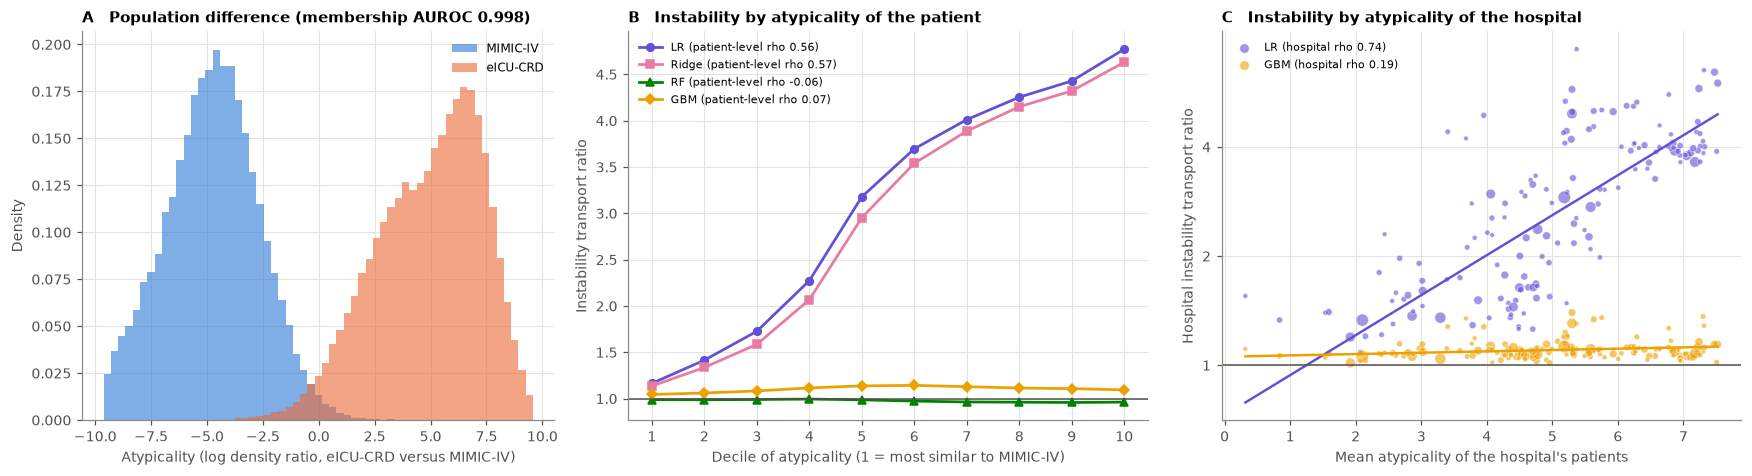

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
ax = axes[0]
bins = np.linspace(np.quantile(LOG_DR, 0.002), np.quantile(LOG_DR, 0.998), 60)
ax.hist(ATYP_DEV, bins=bins, density=True, color=DB_COLORS["MIMIC-IV"], alpha=0.6, label="MIMIC-IV")
ax.hist(ATYP, bins=bins, density=True, color=DB_COLORS["eICU-CRD"], alpha=0.6, label="eICU-CRD")
ax.set_xlabel("Atypicality (log density ratio, eICU-CRD versus MIMIC-IV)")
ax.set_ylabel("Density")
ax.set_title(f"Population difference (membership AUROC {DOMAIN_AUROC:.3f})")
ax.legend(fontsize=8)
panel_label(ax, "A")

ax = axes[1]
for m in MODELS_LIST:
    t = TABLE12[TABLE12["model"] == m]
    ax.plot(t["decile"], t["itr"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=5, lw=1.8,
            label=f"{MODEL_SHORT[m]} (patient-level rho {t['spearman_patient'].iloc[0]:.2f})")
ax.axhline(1, color=INK2, lw=1)
ax.set_xticks(range(1, 11))
ax.set_xlabel("Decile of atypicality (1 = most similar to MIMIC-IV)")
ax.set_ylabel("Instability transport ratio")
ax.set_title("Instability by atypicality of the patient")
ax.legend(fontsize=7.5)
panel_label(ax, "B")

ax = axes[2]
for m in show:
    d = HOSP_T[m]
    ax.scatter(d["mean_atypicality"], d["itr"], s=8 + d["n"] / d["n"].max() * 60, color=MODEL_COLORS[m], alpha=0.6,
               edgecolors="white", linewidths=0.5, label=f"{MODEL_SHORT[m]} (hospital rho {spearmanr(d['mean_atypicality'], d['itr']).correlation:.2f})")
    b1, b0 = np.polyfit(d["mean_atypicality"], np.log(d["itr"]), 1, w=np.sqrt(d["n"]))
    xs = np.linspace(d["mean_atypicality"].min(), d["mean_atypicality"].max(), 50)
    ax.plot(xs, np.exp(b0 + b1 * xs), color=MODEL_COLORS[m], lw=1.6)
ax.axhline(1, color=INK2, lw=1)
sel = HOSP_ALL["model"].isin(show)
ratio_axis(ax, "y", float(HOSP_ALL.loc[sel, "itr"].min()), float(HOSP_ALL.loc[sel, "itr"].max()))
ax.set_xlabel("Mean atypicality of the hospital's patients")
ax.set_ylabel("Hospital instability transport ratio")
ax.set_title("Instability by atypicality of the hospital")
ax.legend(fontsize=7.5, loc="upper left")
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p3_fig5_atypicality", "Population difference, instability by atypicality of patients and hospitals")

### Mechanism: measurement patterns that are rare in development (Figure P3-5b, Tables 12b and 12c; post hoc)

Several results of the first full run pointed to one mechanism: amplification was large for the two regression models but absent for the tree ensembles; it shrank when the GCS motor score was removed (S4a) or when evaluation was restricted to hospitals that chart it (S4b); and hospital flag rates swung by tens of percentage points across refits (Figure P3-S2), as if a whole hospital's risks moved together. A missingness indicator learned where a predictor is almost always measured is estimated from few patients, so its coefficient varies a lot between development samples. That barely matters in development, where few patients carry the indicator, but it moves the risk of every patient in a hospital that does not measure the predictor.

Three checks, all added after the first full run:

1. For each group of predictors: how often it is missing in each database, and the instability transport ratio for eICU-CRD patients in whom it is missing versus observed (Table 12b).
2. Instability transport by how common a patient's whole missingness pattern is in MIMIC-IV (Table 12c, 95% intervals from hospital-cluster bootstrap).
3. What separates the databases: the membership model refitted on missingness alone, and per-predictor membership AUROCs on observed values (Table S).

Sensitivity analysis S7 (section 11) refits the models without missingness indicators.

In [18]:
GROUP_COLS = {g: [PRED.index(c) for c in cols if c in PRED] for g, cols in GROUPS.items()}
GROUP_COLS = {g: idx for g, idx in GROUP_COLS.items() if idx}
MISS_DEV = np.column_stack([np.isnan(X_dev[:, idx]).any(axis=1) for idx in GROUP_COLS.values()])
MISS_EXT = np.column_stack([np.isnan(X_ext[:, idx]).any(axis=1) for idx in GROUP_COLS.values()])

grp_rows = []
for j, g in enumerate(GROUP_COLS):
    miss = MISS_EXT[:, j]
    row = {"group": g, "missing_mimic": float(MISS_DEV[:, j].mean()), "missing_eicu": float(miss.mean()),
           "patients_mimic_missing": int(MISS_DEV[:, j].sum()), "patients_eicu_missing": int(miss.sum())}
    for m in MODELS_LIST:
        sd, ex = EXT_S[m]["sd"], ITR[m]["expected_sd"]
        for lab, sel in (("missing", miss), ("observed", ~miss)):
            ok_n = sel.sum() >= 50
            row[f"itr_{m}_{lab}"] = sd[sel].sum() / ex[sel].sum() if ok_n else np.nan
            row[f"unstable_per_1000_{m}_{lab}"] = 1000 * float(ITR[m]["unstable"][sel].mean()) if ok_n else np.nan
    grp_rows.append(row)
TABLE12B = pd.DataFrame(grp_rows)
TABLE12B["missing_difference"] = TABLE12B["missing_eicu"] - TABLE12B["missing_mimic"]
TABLE12B = TABLE12B.sort_values("missing_difference", ascending=False).reset_index(drop=True)
save_table(TABLE12B.round(5), "table12b_missingness_groups",
           "Missingness of each predictor group in both databases and instability transport in eICU-CRD patients with the group missing or observed")

weights = np.int64(1) << np.arange(MISS_DEV.shape[1], dtype=np.int64)
key_dev = MISS_DEV.astype(np.int64) @ weights
key_ext = MISS_EXT.astype(np.int64) @ weights
freq_dev = pd.Series(key_dev).value_counts(normalize=True)
PATTERN_FREQ = pd.Series(key_ext).map(freq_dev).fillna(0.0).to_numpy()
PATTERN_LABELS = ["Common in MIMIC-IV (1% or more)", "Uncommon (0.1% to 1%)", "Rare (under 0.1%)", "Never seen in MIMIC-IV"]
PATTERN_CLASS = np.select([PATTERN_FREQ >= 0.01, PATTERN_FREQ >= 0.001, PATTERN_FREQ > 0], [0, 1, 2], 3)
pat_rows = []
for m in MODELS_LIST:
    for c, label in enumerate(PATTERN_LABELS):
        sel = (PATTERN_CLASS == c).astype(np.float64)
        if sel.sum() < 50:
            continue
        est, lo, hi = ratio_ci(EXT_S[m]["sd"] * sel, ITR[m]["expected_sd"] * sel, CONFIG["cluster_boot"], seed_for(m, "pattern", c))
        d_est, d_lo, d_hi = ratio_ci(ITR[m]["unstable"] * sel, ITR[m]["expected_unstable"] * sel, CONFIG["cluster_boot"], seed_for(m, "pattern-dir", c))
        pat_rows.append({"model_key": m, "model": MODEL_LABELS[m], "pattern": label, "patients": int(sel.sum()),
                         "share_of_eicu": float(sel.mean()), "itr": est, "itr_lower": lo, "itr_upper": hi,
                         "dir": d_est, "dir_lower": d_lo, "dir_upper": d_hi,
                         "unstable_per_1000": 1000 * float(ITR[m]["unstable"][sel > 0].mean())})
TABLE12C = pd.DataFrame(pat_rows)
save_table(TABLE12C.drop(columns="model_key").round(5), "table12c_instability_by_missingness_pattern",
           "Instability transport by how common the patient's missingness pattern is in MIMIC-IV")
display(TABLE12B[["group", "missing_mimic", "missing_eicu"] + [f"itr_{m}_{k}" for m in MODELS_LIST for k in ("missing", "observed")]].head(10).round(3))
display(TABLE12C.drop(columns="model_key").round(3))

,group,missing_mimic,missing_eicu,itr_lr_missing,itr_lr_observed,itr_ridge_missing,itr_ridge_observed,itr_rf_missing,itr_rf_observed,itr_hgb_missing,itr_hgb_observed
0,lactate,0.272,0.637,3.505,2.564,3.336,2.506,0.989,0.965,1.122,1.084
1,inr,0.082,0.428,3.454,2.784,3.279,2.709,0.987,0.972,1.142,1.081
2,gcs_motor,0.001,0.346,4.420,2.133,4.431,1.886,0.951,0.995,1.108,1.099
3,gcs_total,0.148,0.249,4.399,2.352,4.414,2.140,0.941,0.994,1.106,1.101
4,bicarbonate,0.006,0.091,5.609,2.679,4.793,2.677,1.039,0.973,1.227,1.091
5,resp_rate,0.001,0.070,7.710,2.821,7.121,2.733,0.996,0.977,1.434,1.081
6,platelets,0.006,0.057,5.531,2.851,4.985,2.771,1.061,0.974,1.364,1.087
7,wbc,0.006,0.048,4.876,2.925,4.321,2.843,1.091,0.974,1.424,1.088
8,hemoglobin,0.006,0.045,4.811,2.947,4.413,2.847,1.084,0.974,1.426,1.089
9,chloride,0.005,0.043,6.160,2.927,5.462,2.839,1.151,0.973,1.414,1.092


,model,pattern,patients,share_of_eicu,itr,itr_lower,itr_upper,dir,dir_lower,dir_upper,unstable_per_1000
0,Logistic regression,Common in MIMIC-IV (1% or more),38517,0.409,1.087,1.072,1.105,1.081,1.063,1.101,84.352
1,Logistic regression,Uncommon (0.1% to 1%),11180,0.119,1.242,1.226,1.261,1.255,1.225,1.286,106.977
2,Logistic regression,Rare (under 0.1%),15593,0.166,4.257,4.075,4.491,4.170,3.950,4.421,418.585
3,Logistic regression,Never seen in MIMIC-IV,28824,0.306,4.980,4.737,5.238,4.393,4.179,4.638,434.881
4,Ridge logistic regression,Common in MIMIC-IV (1% or more),38517,0.409,1.081,1.067,1.099,1.069,1.052,1.088,82.405
5,Ridge logistic regression,Uncommon (0.1% to 1%),11180,0.119,1.217,1.201,1.236,1.228,1.199,1.260,103.757
6,Ridge logistic regression,Rare (under 0.1%),15593,0.166,4.172,4.041,4.341,4.354,4.109,4.633,431.860
7,Ridge logistic regression,Never seen in MIMIC-IV,28824,0.306,4.675,4.450,4.941,4.468,4.300,4.650,435.921
8,Random forest,Common in MIMIC-IV (1% or more),38517,0.409,0.989,0.987,0.991,0.987,0.979,0.997,138.147
9,Random forest,Uncommon (0.1% to 1%),11180,0.119,0.997,0.993,1.002,1.002,0.986,1.018,154.472


In [19]:
mpath2 = CACHE / "domain_oof_missingness_only.npy"
Z_miss = np.vstack([MISS_DEV, MISS_EXT]).astype(np.float64)
with timed("Membership model on missingness alone"):
    if CONFIG["force"] or not mpath2.exists():
        folds = StratifiedKFold(CONFIG["domain_folds"], shuffle=True, random_state=seed_for("domain-miss") % (2**31 - 1))
        outs = run_parallel([delayed(domain_task)(tr, te, seed_for("domain-miss", k), Z_miss, z_all)
                             for k, (tr, te) in enumerate(folds.split(Z_miss, z_all))])
        oof2 = np.empty(len(z_all))
        for te, p in outs:
            oof2[te] = p
        np.save(mpath2, oof2)
    OOF_MISS = np.load(mpath2)
DOMAIN_AUROC_MISS = auc_fast(z_all, OOF_MISS)

pred_rows = []
for j, c in enumerate(PRED):
    xd, xe = X_dev[:, j], X_ext[:, j]
    od, oe_ = ~np.isnan(xd), ~np.isnan(xe)
    vals = np.r_[xd[od], xe[oe_]]
    lab = np.r_[np.zeros(od.sum(), int), np.ones(oe_.sum(), int)]
    a = auc_fast(lab, vals) if od.sum() > 20 and oe_.sum() > 20 else np.nan
    pred_rows.append({"predictor": c, "missing_mimic": float(1 - od.mean()), "missing_eicu": float(1 - oe_.mean()),
                      "median_mimic": float(np.median(xd[od])) if od.any() else np.nan,
                      "median_eicu": float(np.median(xe[oe_])) if oe_.any() else np.nan,
                      "membership_auroc_observed_values": max(a, 1 - a) if np.isfinite(a) else np.nan})
PRED_SHIFT = pd.DataFrame(pred_rows).sort_values("membership_auroc_observed_values", ascending=False)
save_table(PRED_SHIFT.round(4), "tableS_p3_predictor_shift", "Per-predictor missingness and membership AUROC of observed values, MIMIC-IV versus eICU-CRD")
print(f"Membership AUROC: all predictors and missingness {DOMAIN_AUROC:.3f}; missingness alone {DOMAIN_AUROC_MISS:.3f}")
display(PRED_SHIFT.head(12).round(3))


>>> Membership model on missingness alone
<<< Membership model on missingness alone: 0.0 min
Membership AUROC: all predictors and missingness 0.998; missingness alone 0.906


,predictor,missing_mimic,missing_eicu,median_mimic,median_eicu,membership_auroc_observed_values
52,gcs_motor_min,0.001,0.346,6.000,6.000,0.616
47,albumin_min,0.616,0.388,3.300,3.000,0.598
12,mbp_max,0.000,0.002,99.000,104.000,0.575
51,gcs_total_min,0.148,0.249,15.000,14.000,0.574
13,mbp_mean,0.000,0.002,76.818,79.958,0.570
48,albumin_max,0.616,0.388,3.400,3.200,0.569
33,bicarbonate_min,0.006,0.091,22.000,23.000,0.567
37,hemoglobin_min,0.006,0.045,10.200,10.900,0.566
6,sbp_max,0.003,0.002,144.000,149.000,0.565
14,resp_rate_min,0.001,0.070,12.000,13.000,0.562


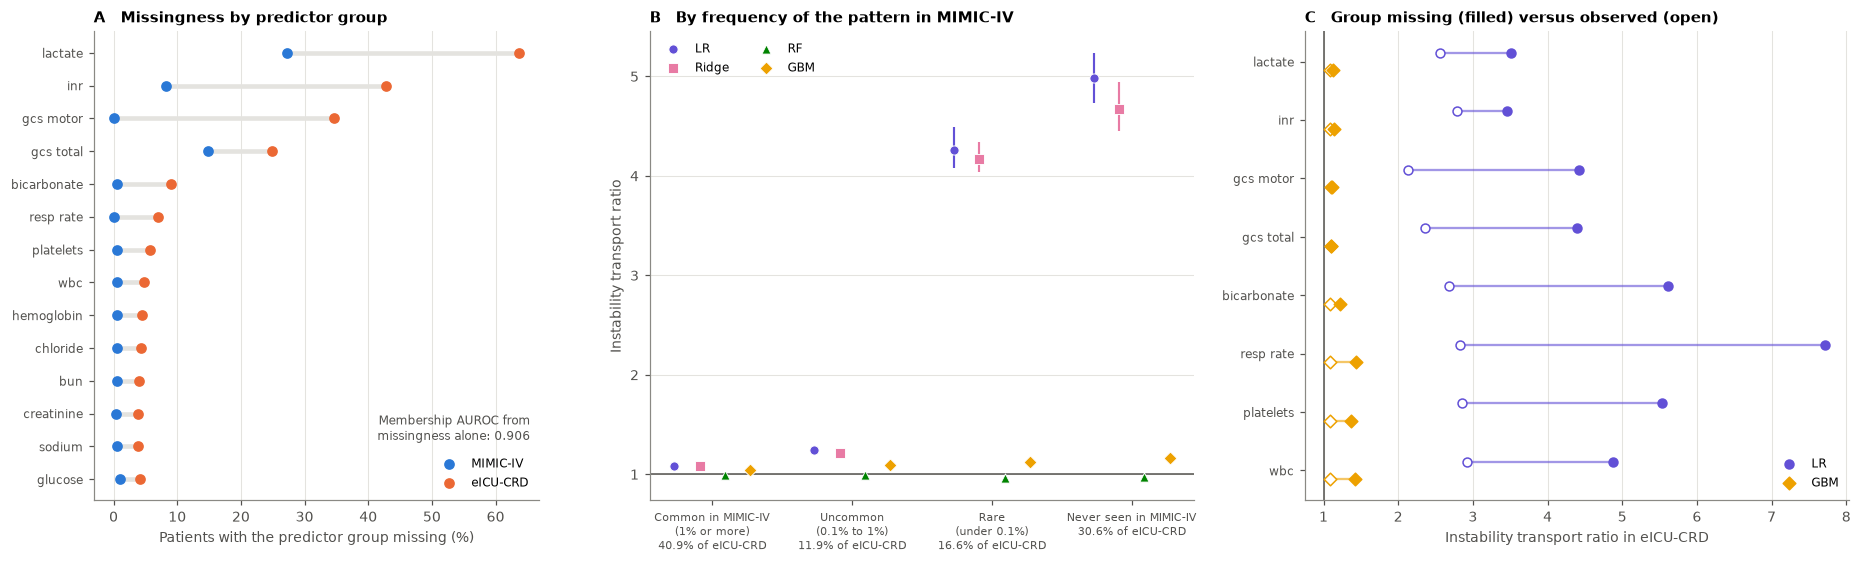

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw={"width_ratios": [0.9, 1.1, 1.1]})
ax = axes[0]
t = TABLE12B.sort_values("missing_difference", ascending=True).tail(14)
yy = np.arange(len(t))
ax.hlines(yy, 100 * t["missing_mimic"], 100 * t["missing_eicu"], color=GRID, lw=3)
ax.scatter(100 * t["missing_mimic"], yy, color=DB_COLORS["MIMIC-IV"], s=36, zorder=3, label="MIMIC-IV")
ax.scatter(100 * t["missing_eicu"], yy, color=DB_COLORS["eICU-CRD"], s=36, zorder=3, label="eICU-CRD")
ax.set_yticks(yy)
ax.set_yticklabels([g.replace("_", " ") for g in t["group"]], fontsize=8)
ax.set_xlabel("Patients with the predictor group missing (%)")
ax.set_title("Missingness by predictor group", fontsize=9.5)
ax.text(0.98, 0.12, f"Membership AUROC from\nmissingness alone: {DOMAIN_AUROC_MISS:.3f}", transform=ax.transAxes, ha="right",
        va="bottom", fontsize=8, color=INK2)
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
panel_label(ax, "A")

ax = axes[1]
off = np.linspace(-0.27, 0.27, len(MODELS_LIST))
for o, m in zip(off, MODELS_LIST):
    t = TABLE12C[TABLE12C["model_key"] == m]
    xs = np.array([PATTERN_LABELS.index(p) for p in t["pattern"]]) + o
    ax.vlines(xs, t["itr_lower"], t["itr_upper"], color=MODEL_COLORS[m], lw=1.4)
    ax.scatter(xs, t["itr"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], s=36, zorder=3, edgecolors="white", linewidths=0.6,
               label=MODEL_SHORT[m])
shares = TABLE12C[TABLE12C["model_key"] == MODELS_LIST[0]].set_index("pattern")["share_of_eicu"]
ax.set_xticks(range(len(PATTERN_LABELS)))
ax.set_xticklabels([f"{l.replace(' (', chr(10) + '(')}\n{100 * shares.get(l, 0):.1f}% of eICU-CRD" for l in PATTERN_LABELS], fontsize=7.5)
ax.axhline(1, color=INK2, lw=1)
ax.set_ylabel("Instability transport ratio")
ax.set_title("By frequency of the pattern in MIMIC-IV", fontsize=9.5)
ax.legend(fontsize=8, ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
panel_label(ax, "B")

ax = axes[2]
cmp_models = [m for m in ("lr", "hgb") if m in MODELS_LIST]
top = TABLE12B.dropna(subset=[f"itr_{m}_{k}" for m in cmp_models for k in ("missing", "observed")]).head(8).iloc[::-1]
yy = np.arange(len(top))
for m, dy in zip(cmp_models, (0.15, -0.15)):
    ax.hlines(yy + dy, top[f"itr_{m}_observed"], top[f"itr_{m}_missing"], color=MODEL_COLORS[m], lw=1.5, alpha=0.6)
    ax.scatter(top[f"itr_{m}_observed"], yy + dy, facecolors="white", edgecolors=MODEL_COLORS[m], s=34, zorder=3, marker=MODEL_MARKERS[m])
    ax.scatter(top[f"itr_{m}_missing"], yy + dy, color=MODEL_COLORS[m], s=34, zorder=3, marker=MODEL_MARKERS[m], label=MODEL_SHORT[m])
ax.axvline(1, color=INK2, lw=1)
ax.set_yticks(yy)
ax.set_yticklabels([g.replace("_", " ") for g in top["group"]], fontsize=8)
ax.set_xlabel("Instability transport ratio in eICU-CRD")
ax.set_title("Group missing (filled) versus observed (open)", fontsize=9.5)
ax.legend(fontsize=8, loc="lower right")
ax.grid(axis="y", visible=False)
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p3_fig5b_missingness_mechanism", "Missingness patterns rare in development and instability transport")

## 7. Who bears the instability in other hospitals? (Figure P3-6)

Instability transport ratio and decision instability by patient and hospital characteristics in eICU-CRD, each patient compared with development patients at the same predicted risk, so that differences are not explained by risk alone. 95% intervals: bootstrap of hospitals within each subgroup (patients from the same hospital resampled together).


>>> External subgroups
<<< External subgroups: 0.0 min


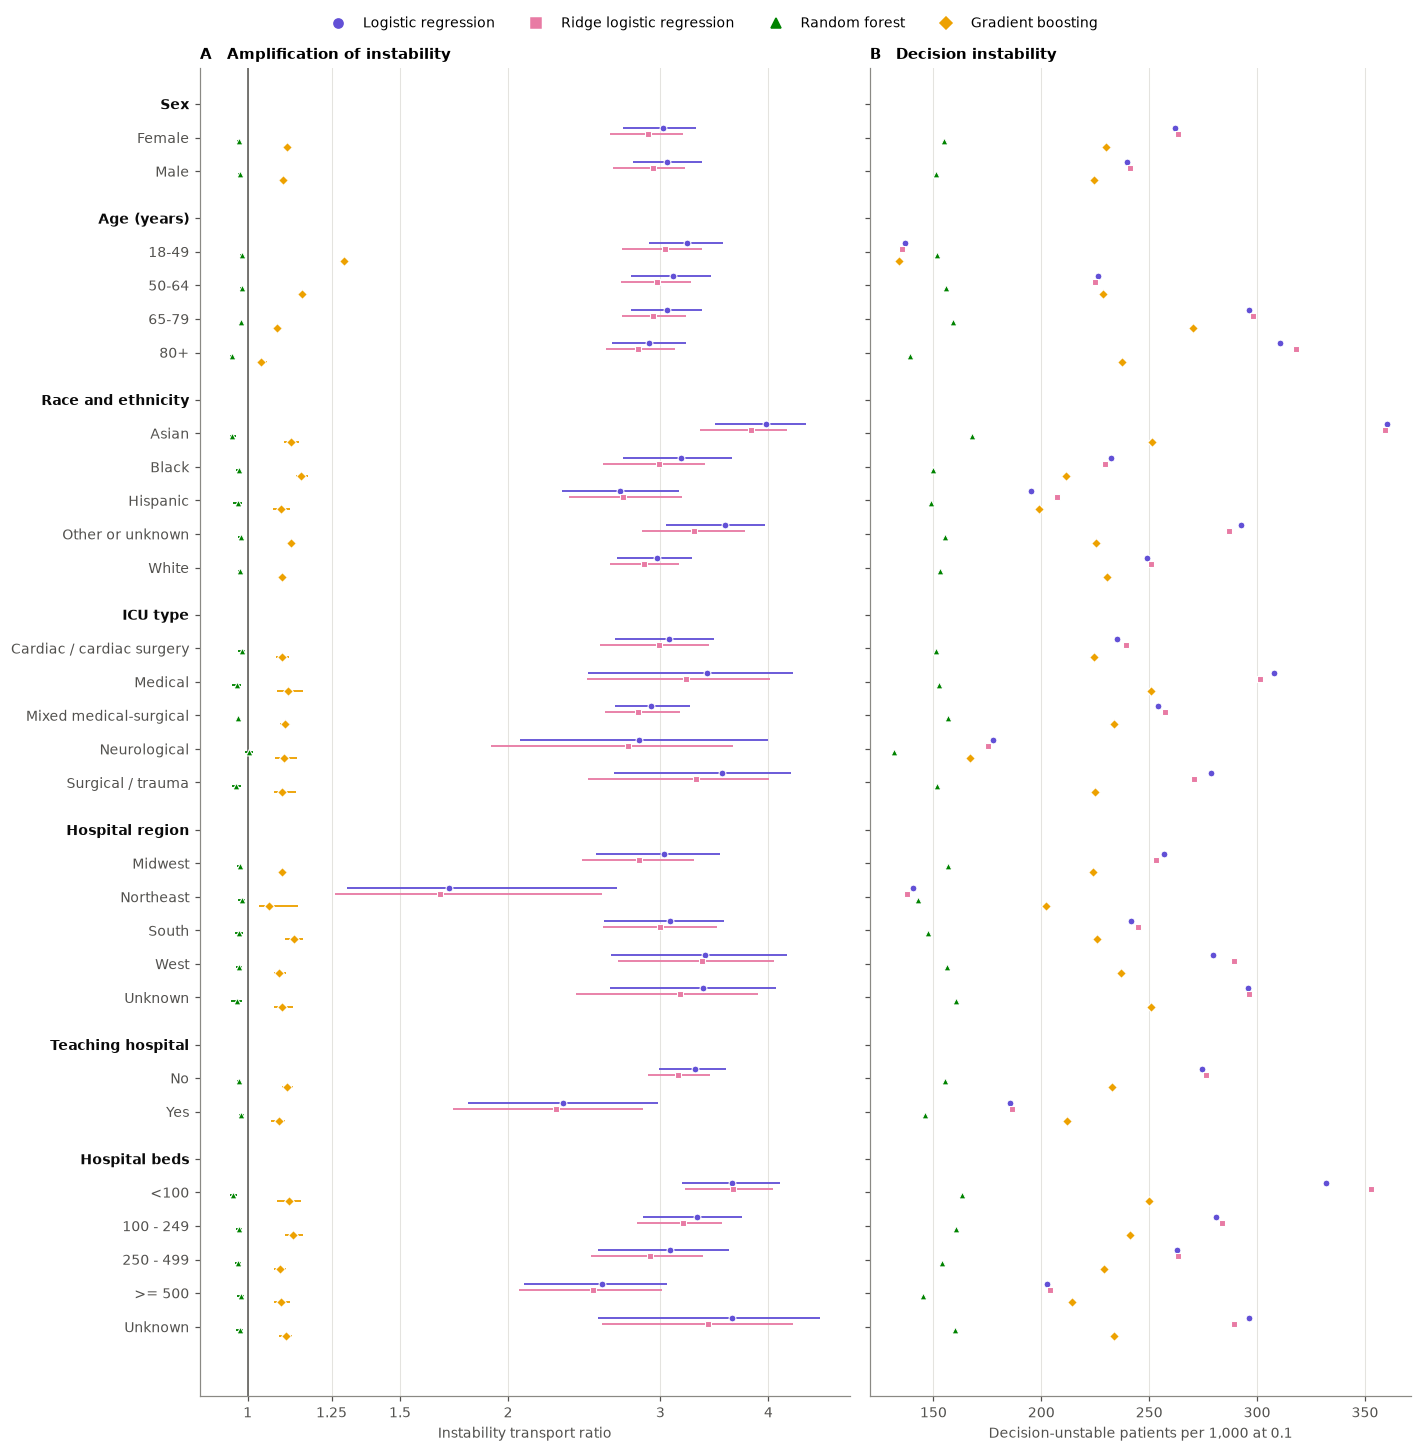

In [21]:
EXT_DIMS = {"sex": "Sex", "age_band": "Age (years)", "race_group": "Race and ethnicity", "care_unit_group": "ICU type",
            "hospital_region": "Hospital region", "hospital_teaching": "Teaching hospital", "hospital_beds": "Hospital beds"}


def subgroup_task(m, dim, level, idx, n_boot, seed, sd_i, ex_i, uns, hosp_idx):
    rng = np.random.default_rng(seed)
    groups = [idx[hosp_idx[idx] == g] for g in np.unique(hosp_idx[idx])]
    sn = np.array([sd_i[g].sum() for g in groups])
    se = np.array([ex_i[g].sum() for g in groups])
    boots = np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, len(groups), len(groups))
        boots[b] = sn[pick].sum() / se[pick].sum()
    return {"model_key": m, "dimension": dim, "level": level, "n": idx.size, "hospitals": len(groups),
            "ratio": sd_i[idx].sum() / ex_i[idx].sum(), "ratio_lower": np.quantile(boots, 0.025),
            "ratio_upper": np.quantile(boots, 0.975), "unstable_per_1000": 1000 * float(uns[idx].mean())}


tasks = []
for m in MODELS_LIST:
    uns = EXT_S[m][f"minority_emp@{T0:g}"] > UNSTABLE
    for dim, label in EXT_DIMS.items():
        vals = ext[dim].map(lambda v: clean_level(v, dim)).to_numpy()
        for level in ordered_levels(dim, vals):
            idx = np.flatnonzero(vals == level)
            if idx.size >= 50:
                tasks.append(delayed(subgroup_task)(m, label, level, idx, CONFIG["subgroup_boot"], seed_for(m, dim, level),
                                                    EXT_S[m]["sd"], ITR[m]["expected_sd"], uns, HOSP_INDEX))
with timed("External subgroups"):
    EXT_SUB = pd.DataFrame(run_parallel(tasks))
EXT_SUB["model"] = EXT_SUB["model_key"].map(MODEL_LABELS)
save_table(EXT_SUB.drop(columns="model_key").round(5), "tableS_p3_external_subgroups",
           "Instability transport ratio and decision instability by subgroup in eICU-CRD")

first = EXT_SUB[EXT_SUB["model_key"] == MODELS_LIST[0]]
ypos, labels, headers, y = {}, [], [], 0
for dim in first["dimension"].unique():
    headers.append((y, dim))
    y += 1
    for lv in first.loc[first["dimension"] == dim, "level"]:
        ypos[(dim, lv)] = y
        labels.append((y, lv))
        y += 1
    y += 0.4
fig, axes = plt.subplots(1, 2, figsize=(13, 0.3 * y + 1.6), sharey=True, gridspec_kw={"width_ratios": [1.2, 1]})
off = np.linspace(-0.27, 0.27, len(MODELS_LIST))
for o, m in zip(off, MODELS_LIST):
    s = EXT_SUB[EXT_SUB["model_key"] == m]
    yy = np.array([ypos.get((d, l), np.nan) for d, l in zip(s["dimension"], s["level"])]) + o
    axes[0].hlines(yy, s["ratio_lower"], s["ratio_upper"], color=MODEL_COLORS[m], lw=1.2)
    axes[0].scatter(s["ratio"], yy, s=20, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], zorder=3, edgecolors="white", linewidths=0.7)
    axes[1].scatter(s["unstable_per_1000"], yy, s=20, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], zorder=3, edgecolors="white", linewidths=0.7)
axes[0].axvline(1, color=INK2, lw=1)
ratio_axis(axes[0], "x", float(EXT_SUB["ratio_lower"].min()), float(EXT_SUB["ratio_upper"].max()))
axes[0].set_xlabel("Instability transport ratio")
axes[0].set_title("Amplification of instability")
axes[1].set_xlabel(f"Decision-unstable patients per 1,000 at {T0:g}")
axes[1].set_title("Decision instability")
axes[0].set_yticks([p for p, _ in labels] + [p for p, _ in headers])
axes[0].set_yticklabels([l for _, l in labels] + [h_ for _, h_ in headers])
for tick in axes[0].get_yticklabels()[len(labels):]:
    tick.set_fontweight("bold")
    tick.set_color(INK)
axes[0].invert_yaxis()
for ax, letter in zip(axes, "AB"):
    ax.grid(axis="y", visible=False)
    panel_label(ax, letter)
fig.legend(handles=model_handles(MODELS_LIST, line=False), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.02))
fig.tight_layout()
save_figure(fig, "p3_fig6_external_subgroups", "Instability transport ratio and decision instability by subgroup in eICU-CRD")

## 8. External ground truth: sample size and audit accuracy in other hospitals (Figure P3-7, Table 13)

Notebook 2 drew K independent development samples from MIMIC-IV at each size and applied every model to the MIMIC-IV audit panel **and to a fixed panel of eICU-CRD patients**. The spread of the K predictions is the true instability for each patient. Here the same experiment is read out in the external panel:

* **True transport.** Does true instability in eICU-CRD patients exceed that of MIMIC-IV audit patients at the same risk, at every development size? (True ITR, from independent samples, no bootstrap involved.)
* **Does more data help externally as much as internally?** Decay exponent of true instability with n in each population, and the development size needed to meet the stability targets of notebook 2 for eICU-CRD patients.
* **Does the bootstrap audit, run in the development data, correctly estimate instability in the other hospitals?** Ratio of the bootstrap estimate (refits of one development sample applied to the eICU-CRD panel) to the truth, and the sensitivity and positive predictive value of its flags.

The truth is itself estimated from a finite number of development samples. Shaded bands in Figure P3-7 (A and D) are Monte Carlo 95% intervals from resampling those samples (added after the first full run). Where the mean-based instability index is heavy-tailed (a few development samples with very large coefficients), the decision-unstable share in panel D is the more robust summary. Required sizes more than 10 times beyond the largest evaluated size are reported as not reached.

In [22]:
stay_pos_ext = pd.Series(np.arange(N_EXT), index=ext["stay_id"].astype(np.int64).to_numpy())
stay_pos_dev = pd.Series(np.arange(N_DEV), index=dev["stay_id"].astype(np.int64).to_numpy())
PANEL = stay_pos_ext.loc[MV_DESIGN["panel_stay_ids"]].to_numpy()
AUDIT = stay_pos_dev.loc[MV_DESIGN["audit_stay_ids"]].to_numpy()
POOL = np.setdiff1d(np.arange(N_DEV), AUDIT)
assert POOL.size == MV_DESIGN["pool_size"], "the development pool does not match notebook 2"
y_pan, y_aud = y_ext[PANEL], y_dev[AUDIT]
K_TRUTH, R_BOOT = MV_DESIGN["k_truth"], MV_DESIGN["r_boot"]
N_FOCUS = N_RILEY if N_RILEY in SIZES else SIZES[len(SIZES) // 2]


def unflat(npz, prefix):
    return {k.split("__", 1)[1]: npz[k] for k in npz.files if k.startswith(prefix + "__")}


def est_itr(ref_s, target_s):
    curve = risk_curve(ref_s["mean"], ref_s["sd"])
    return target_s["sd"].sum() / curve(target_s["mean"]).sum()


def truth_mc(T, f, n_boot, seed):
    """Monte Carlo 95% interval of the true instability index and decision-unstable share (resampling development samples)."""
    rng = np.random.default_rng(seed)
    T = np.asarray(T, dtype=np.float64)
    K = T.shape[0]
    c = 1.0 / math.sqrt(1.0 - f)
    L = logit(T)
    t0 = math.log(T0 / (1 - T0))
    ii, us = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, K, K)
        Tb, Lb = T[pick], L[pick]
        ii[b] = np.mean(np.abs(Tb - Tb.mean(axis=0)).mean(axis=0)) * math.sqrt(K / (K - 1)) * c
        q = norm.cdf((Lb.mean(axis=0) - t0) / np.maximum(Lb.std(axis=0, ddof=1) * c, 1e-9))
        us[b] = np.mean(np.minimum(q, 1 - q) > UNSTABLE)
    return np.quantile(ii, [0.025, 0.975]), np.quantile(us, [0.025, 0.975])


MC_BOOT = 200 if FULL else 30
TRUTH_X, BOOT_X, mv_rows = {}, {}, []
with timed("Multiverse read-out in the external panel"):
    for m in MODELS_LIST:
        for n in SIZES:
            tz = np.load(MV_CACHE / f"truth_{m}_{n}.npz")
            f = float(tz["f"])
            ta, tp = truth_summary(tz["T_aud"], f), truth_summary(tz["T_pan"], f)
            TRUTH_X[(m, n)] = {"aud": ta, "pan": tp, "T_aud": tz["T_aud"], "T_pan": tz["T_pan"]}
            row = {"model": m, "n": n, "f": f, "true_itr": est_itr(ta, tp)}
            for pop, s, key in (("audit", ta, "T_aud"), ("eicu", tp, "T_pan")):
                ps = population_summary(s)
                row.update({f"truth_{pop}_{k}": v for k, v in ps.items()})
                (ii_lo, ii_hi), (us_lo, us_hi) = truth_mc(tz[key], f, MC_BOOT, seed_for("truth-mc", m, n, pop))
                row.update({f"truth_{pop}_ii_mc_lower": ii_lo, f"truth_{pop}_ii_mc_upper": ii_hi,
                            f"truth_{pop}_unstable_mc_lower": us_lo, f"truth_{pop}_unstable_mc_upper": us_hi})
            for r in range(R_BOOT):
                bz = np.load(MV_CACHE / f"boot_{m}_{n}_{r}.npz")
                BOOT_X[(m, n, r)] = {"new": unflat(bz, "new"), "pan": unflat(bz, "pan")}
            est = {pop: [population_summary(BOOT_X[(m, n, r)][key]) for r in range(R_BOOT)] for pop, key in (("audit", "new"), ("eicu", "pan"))}
            itrs = [est_itr(BOOT_X[(m, n, r)]["new"], BOOT_X[(m, n, r)]["pan"]) for r in range(R_BOOT)]
            row.update({"boot_itr": float(np.mean(itrs)), "boot_itr_min": float(np.min(itrs)), "boot_itr_max": float(np.max(itrs))})
            for pop in ("audit", "eicu"):
                truth_pop = TRUTH_X[(m, n)]["aud" if pop == "audit" else "pan"]
                ratios = [e["instability_index"] / row[f"truth_{pop}_instability_index"] for e in est[pop]]
                diffs = [100 * (e[f"share_unstable_emp@{T0:g}"] - row[f"truth_{pop}_share_unstable@{T0:g}"]) for e in est[pop]]
                truly = truth_pop[f"minority@{T0:g}"] > UNSTABLE
                sens, ppv, rho = [], [], []
                for r in range(R_BOOT):
                    e = BOOT_X[(m, n, r)]["new" if pop == "audit" else "pan"]
                    flag = e[f"minority_emp@{T0:g}"] > UNSTABLE
                    sens.append((flag & truly).sum() / max(truly.sum(), 1))
                    ppv.append((flag & truly).sum() / max(flag.sum(), 1))
                    rho.append(spearmanr(truth_pop["sd"], e["sd"]).correlation)
                row.update({f"ratio_{pop}": float(np.mean(ratios)), f"ratio_{pop}_min": float(np.min(ratios)),
                            f"ratio_{pop}_max": float(np.max(ratios)), f"diff_unstable_pp_{pop}": float(np.mean(diffs)),
                            f"sensitivity_{pop}": float(np.mean(sens)), f"ppv_{pop}": float(np.mean(ppv)),
                            f"spearman_sd_{pop}": float(np.mean(rho))})
            mv_rows.append(row)
MVX = pd.DataFrame(mv_rows)
TABLE13 = MVX.assign(model=MVX["model"].map(MODEL_LABELS))
save_table(TABLE13.round(5), "table13_external_ground_truth",
           "True instability in MIMIC-IV audit and eICU-CRD panels by development size, true and estimated ITR, bootstrap accuracy in each population")
display(TABLE13[["model", "n", "truth_audit_instability_index", "truth_eicu_instability_index", "true_itr", "boot_itr",
                 "ratio_audit", "ratio_eicu", "sensitivity_eicu", "ppv_eicu"]].round(3))


>>> Multiverse read-out in the external panel
<<< Multiverse read-out in the external panel: 3.3 min


,model,n,truth_audit_instability_index,truth_eicu_instability_index,true_itr,boot_itr,ratio_audit,ratio_eicu,sensitivity_eicu,ppv_eicu
0,Logistic regression,500,0.095,0.136,1.131,1.013,1.290,1.118,0.606,0.860
1,Logistic regression,1000,0.060,0.100,1.405,1.183,0.985,0.858,0.598,0.830
2,Logistic regression,2000,0.038,0.096,2.212,1.668,0.992,0.801,0.638,0.851
3,Logistic regression,3906,0.027,0.114,3.035,2.484,1.001,0.825,0.671,0.882
4,Logistic regression,4000,0.026,0.096,2.878,2.049,1.008,0.475,0.506,0.867
5,Logistic regression,8000,0.019,0.082,3.319,2.890,1.000,0.939,0.733,0.907
6,Logistic regression,16000,0.013,0.053,3.202,3.010,0.985,0.849,0.729,0.928
7,Ridge logistic regression,500,0.032,0.045,1.277,1.089,1.661,1.507,0.601,0.792
8,Ridge logistic regression,1000,0.034,0.054,1.396,1.228,1.138,1.066,0.596,0.819
9,Ridge logistic regression,2000,0.026,0.063,2.113,1.606,1.133,0.959,0.656,0.858


In [23]:
TARGETS = {"T1": ("instability_index", 0.01), "T2": ("width95_p90", 0.10), "T3": (f"share_unstable@{T0:g}", 0.05)}
EXTRAPOLATION_CAP = 1_000_000


def required_n(ns, vals, target):
    ns, vals = np.asarray(ns, float), np.asarray(vals, float)
    ok = vals <= target
    if ok.any():
        i = int(np.argmax(ok))
        if i == 0:
            return ns[0], "met at smallest size"
        v1, v2 = max(vals[i - 1], 1e-12), max(vals[i], 1e-12)
        if v1 == v2:
            return ns[i], "interpolated"
        x = math.log(ns[i - 1]) + (math.log(target) - math.log(v1)) * (math.log(ns[i]) - math.log(ns[i - 1])) / (math.log(v2) - math.log(v1))
        return math.exp(x), "interpolated"
    k = min(3, len(ns))
    slope, intercept = np.polyfit(np.log(ns[-k:]), np.log(np.maximum(vals[-k:], 1e-12)), 1)
    if slope >= 0:
        return np.nan, "not reached (no decrease over the largest sizes)"
    n_req = math.exp((math.log(target) - intercept) / slope)
    if n_req > EXTRAPOLATION_CAP:
        return np.nan, f"beyond {EXTRAPOLATION_CAP:,} (extrapolation not reliable)"
    return n_req, "extrapolated"


def decay(ns, vals):
    x, yv = np.log(np.asarray(ns, float)), np.log(np.asarray(vals, float))
    slope, intercept = np.polyfit(x, yv, 1)
    if len(x) > 2:
        resid = yv - (intercept + slope * x)
        se = math.sqrt(resid.var(ddof=2) / ((x - x.mean()) ** 2).sum())
        q = student_t.ppf(0.975, len(x) - 2)
        return -slope, -slope - q * se, -slope + q * se
    return -slope, np.nan, np.nan


ss_rows = []
for m in MODELS_LIST:
    t = MVX[MVX["model"] == m].sort_values("n")
    for pop, label in (("audit", "MIMIC-IV audit panel"), ("eicu", "eICU-CRD panel")):
        d, lo, hi = decay(t["n"], t[f"truth_{pop}_rms_sd"])
        row = {"model": MODEL_LABELS[m], "population": label, "decay_exponent": d, "decay_lower": lo, "decay_upper": hi}
        for key, (col, target) in TARGETS.items():
            n_req, how = required_n(t["n"], t[f"truth_{pop}_{col}"], target)
            factor = n_req / max(SIZES) if np.isfinite(n_req) else np.nan
            if np.isfinite(factor) and factor > 10:
                how = f"not reached by {max(SIZES):,}; extrapolation {factor:.0f}-fold beyond the evaluated range (not reliable)"
            elif how == "extrapolated" and np.isfinite(lo) and lo <= 0:
                how = "extrapolated, but no reliable decrease with n (decay exponent interval includes 0)"
            row.update({f"{key}_n": n_req, f"{key}_method": how, f"{key}_times_minimum": n_req / N_RILEY if np.isfinite(n_req) else np.nan,
                        f"{key}_extrapolation_factor": factor})
        ss_rows.append(row)
TABLE13B = pd.DataFrame(ss_rows)
TABLE13B.insert(2, "analytic_minimum_n", N_RILEY)
save_table(TABLE13B.round(3), "table13b_sample_size_external",
           "Decay of true instability with development size and sample size needed for stability, development versus external patients")
display(TABLE13B.round(2))

,model,population,analytic_minimum_n,decay_exponent,decay_lower,decay_upper,T1_n,T1_method,T1_times_minimum,T1_extrapolation_factor,T2_n,T2_method,T2_times_minimum,T2_extrapolation_factor,T3_n,T3_method,T3_times_minimum,T3_extrapolation_factor
0,Logistic regression,MIMIC-IV audit panel,3906,0.52,0.48,0.57,30240.58,extrapolated,7.74,1.89,48864.97,extrapolated,12.51,3.05,121130.66,extrapolated,31.01,7.57
1,Logistic regression,eICU-CRD panel,3906,0.12,-0.01,0.24,905095.97,"not reached by 16,000; extrapolation 57-fold b...",231.72,56.57,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN
2,Ridge logistic regression,MIMIC-IV audit panel,3906,0.28,0.20,0.35,27100.23,extrapolated,6.94,1.69,54270.50,extrapolated,13.89,3.39,137556.20,extrapolated,35.22,8.60
3,Ridge logistic regression,eICU-CRD panel,3906,-0.08,-0.31,0.16,965984.60,"not reached by 16,000; extrapolation 60-fold b...",247.31,60.37,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN
4,Random forest,MIMIC-IV audit panel,3906,0.11,0.08,0.14,111862.80,extrapolated,28.64,6.99,127589.42,extrapolated,32.66,7.97,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN
5,Random forest,eICU-CRD panel,3906,0.10,0.07,0.12,708713.64,"not reached by 16,000; extrapolation 44-fold b...",181.44,44.29,183296.60,"not reached by 16,000; extrapolation 11-fold b...",46.93,11.46,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN
6,Gradient boosting,MIMIC-IV audit panel,3906,0.14,0.11,0.17,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN
7,Gradient boosting,eICU-CRD panel,3906,0.12,0.10,0.13,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN,NaN,"beyond 1,000,000 (extrapolation not reliable)",NaN,NaN


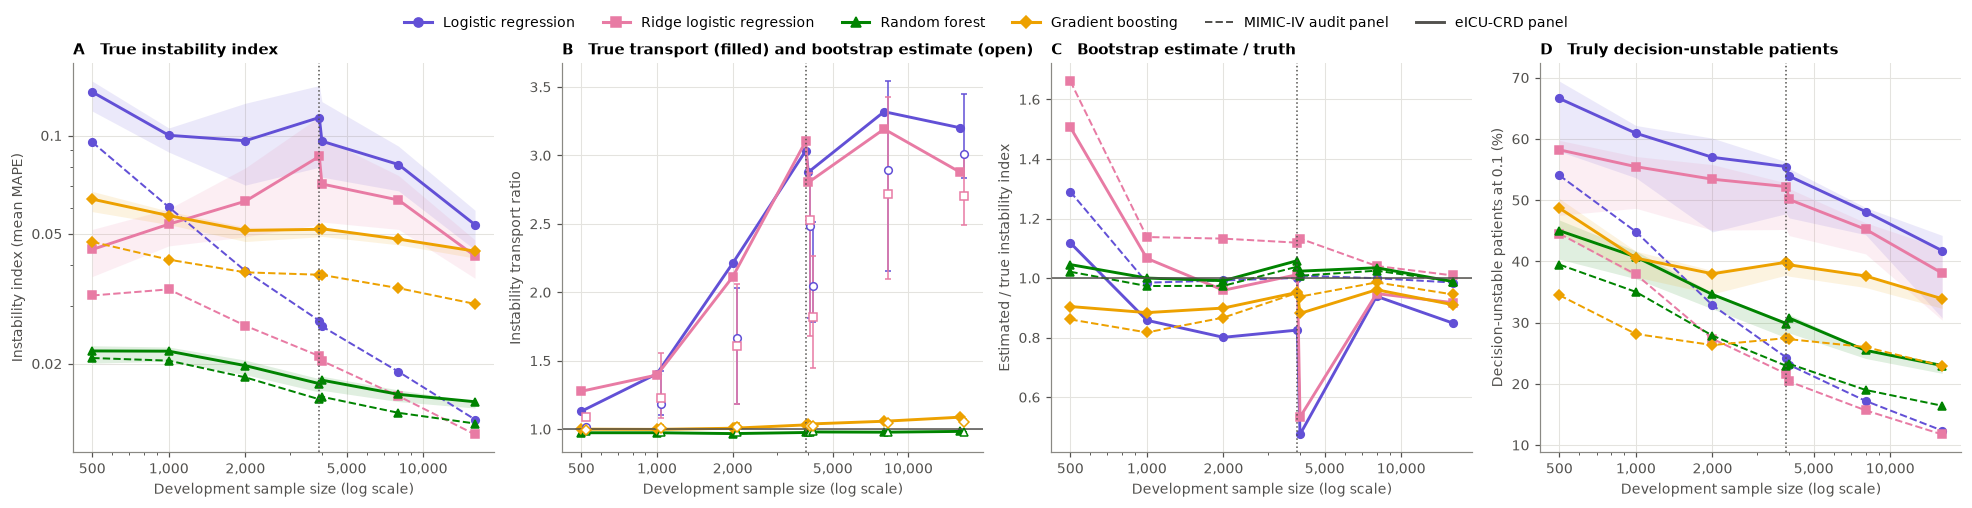

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for m in MODELS_LIST:
    t = MVX[MVX["model"] == m].sort_values("n")
    kw = dict(color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=5)
    axes[0].plot(t["n"], t["truth_audit_instability_index"], ls="--", lw=1.3, **kw)
    axes[0].plot(t["n"], t["truth_eicu_instability_index"], ls="-", lw=1.9, **kw)
    axes[0].fill_between(t["n"], t["truth_eicu_ii_mc_lower"], t["truth_eicu_ii_mc_upper"], color=MODEL_COLORS[m], alpha=0.12, lw=0)
    axes[3].fill_between(t["n"], 100 * t["truth_eicu_unstable_mc_lower"], 100 * t["truth_eicu_unstable_mc_upper"],
                         color=MODEL_COLORS[m], alpha=0.12, lw=0)
    axes[1].plot(t["n"], t["true_itr"], ls="-", lw=1.9, **kw)
    axes[1].errorbar(t["n"] * 1.04, t["boot_itr"], yerr=[t["boot_itr"] - t["boot_itr_min"], t["boot_itr_max"] - t["boot_itr"]],
                     fmt=MODEL_MARKERS[m], mfc="white", color=MODEL_COLORS[m], markersize=5, lw=1, capsize=2)
    axes[2].plot(t["n"], t["ratio_audit"], ls="--", lw=1.3, **kw)
    axes[2].plot(t["n"], t["ratio_eicu"], ls="-", lw=1.9, **kw)
    axes[3].plot(t["n"], 100 * t[f"truth_audit_share_unstable@{T0:g}"], ls="--", lw=1.3, **kw)
    axes[3].plot(t["n"], 100 * t[f"truth_eicu_share_unstable@{T0:g}"], ls="-", lw=1.9, **kw)
axes[1].axhline(1, color=INK2, lw=1)
axes[2].axhline(1, color=INK2, lw=1)
titles = [("True instability index", "Instability index (mean MAPE)"),
          ("True transport (filled) and bootstrap estimate (open)", "Instability transport ratio"),
          ("Bootstrap estimate / truth", "Estimated / true instability index"),
          ("Truly decision-unstable patients", f"Decision-unstable patients at {T0:g} (%)")]
for ax, (title, ylabel), letter in zip(axes, titles, "ABCD"):
    ax.set_xscale("log")
    plain_log_axis(ax.xaxis)
    if N_FOCUS == N_RILEY:
        ax.axvline(N_RILEY, color=INK2, lw=1, ls=":")
    ax.set_xlabel("Development sample size (log scale)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    panel_label(ax, letter)
axes[0].set_yscale("log")
plain_log_axis(axes[0].yaxis, subs=(1.0, 2.0, 5.0), fmt="{:g}")
handles = model_handles(MODELS_LIST) + [Line2D([0], [0], color=INK2, ls="--", lw=1.3, label="MIMIC-IV audit panel"),
                                         Line2D([0], [0], color=INK2, ls="-", lw=1.9, label="eICU-CRD panel")]
fig.legend(handles=handles, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.05))
fig.tight_layout()
save_figure(fig, "p3_fig7_external_ground_truth", "True instability by development size in development and external patients, and accuracy of the bootstrap audit externally")

## 9. What to do about it: deferring unstable decisions (Figure P3-8, Table 14)

A model deployed with an instability audit can return "defer to clinical review" for patients whose decision is unstable instead of a yes/no flag. The question is whether this removes **truly** unstable decisions (truth from the independent development samples), and whether the bootstrap audit is better than the obvious alternative of deferring patients whose risk is simply close to the threshold.

For each deployed model (each of the R development samples that received a bootstrap audit) and each deferral fraction q, the q x 100% patients with the highest score are deferred:

| Strategy | Score | Needs |
|---|---|---|
| Bootstrap audit | Share of refits that disagree with the majority (ties broken by the logit-normal estimate) | The audit refits |
| Distance to threshold | Closeness of the deployed model's risk to the threshold on the logit scale | Only the deployed model |
| Random | Random order | Nothing (reference) |
| Oracle | True decision instability | Not available in practice (upper bound) |

Outcomes: share of truly decision-unstable patients that are deferred (capture), and truly decision-unstable patients per 1,000 among those not deferred (residual). Primary analysis: eICU-CRD panel at the analytic minimum size; the MIMIC-IV audit panel and every other size are in Table 14.

In [25]:
DEFER_GRID = np.array(CONFIG["deferral_grid"])
STRATEGIES = {"bootstrap": "Bootstrap audit", "distance": "Distance to threshold", "random": "Random", "oracle": "Oracle (truth)"}
STRAT_STYLE = {"bootstrap": dict(color=INK, ls="-", lw=2.2), "distance": dict(color="#2a78d6", ls="--", lw=1.8),
               "random": dict(color=NEUTRAL, ls=":", lw=1.5), "oracle": dict(color="#c7c6c1", ls="-", lw=4, alpha=0.8)}


def defer_curves(truly, scores, grid):
    n = truly.size
    out = {}
    for key, s in scores.items():
        order = np.argsort(-s, kind="stable")
        cum = np.r_[0, np.cumsum(truly[order])]
        k = np.round(grid * n).astype(int)
        captured = cum[k]
        out[key] = {"capture": captured / max(truly.sum(), 1), "residual_per_1000": 1000 * (truly.sum() - captured) / np.maximum(n - k, 1)}
    return out


def operating_point(truly, scores, q):
    k = int(round(q * truly.size))
    res = {}
    for key, s in scores.items():
        order = np.argsort(-s, kind="stable")[:k]
        cap = truly[order].sum()
        res[key] = {"capture": cap / max(truly.sum(), 1), "residual_per_1000": 1000 * (truly.sum() - cap) / max(truly.size - k, 1)}
    return res


CURVES, op_rows = {}, []
t0_logit = math.log(T0 / (1 - T0))
for m in MODELS_LIST:
    for n in SIZES:
        for pop, tkey, bkey, Tkey in (("eICU-CRD panel", "pan", "pan", "T_pan"), ("MIMIC-IV audit panel", "aud", "new", "T_aud")):
            truth = TRUTH_X[(m, n)][tkey]
            truly = truth[f"minority@{T0:g}"] > UNSTABLE
            acc = {}
            for r in range(R_BOOT):
                e = BOOT_X[(m, n, r)][bkey]
                deployed = TRUTH_X[(m, n)][Tkey][r].astype(np.float64)
                rng = np.random.default_rng(seed_for("defer", m, n, pop, r))
                scores = {"bootstrap": e[f"minority_emp@{T0:g}"] + 1e-3 * e[f"minority@{T0:g}"],
                          "distance": -np.abs(logit(deployed) - t0_logit), "random": rng.random(truly.size),
                          "oracle": truth[f"minority@{T0:g}"]}
                q_star = float(np.mean(e[f"minority_emp@{T0:g}"] > UNSTABLE))
                for key, v in operating_point(truly, scores, q_star).items():
                    op_rows.append({"model": m, "n": n, "population": pop, "replicate": r, "operating_point": "bootstrap flag rate",
                                    "deferred_share": q_star, "strategy": key, **v})
                for q in (0.05, 0.10, 0.20):
                    for key, v in operating_point(truly, scores, q).items():
                        op_rows.append({"model": m, "n": n, "population": pop, "replicate": r, "operating_point": f"{q:.0%} deferred",
                                        "deferred_share": q, "strategy": key, **v})
                if n == N_FOCUS:
                    for key, v in defer_curves(truly, scores, DEFER_GRID).items():
                        acc.setdefault(key, []).append(v)
            if n == N_FOCUS:
                CURVES[(m, pop)] = {k: {"capture": np.mean([v["capture"] for v in vs], axis=0),
                                         "residual_per_1000": np.mean([v["residual_per_1000"] for v in vs], axis=0)} for k, vs in acc.items()}
                CURVES[(m, pop)]["truly_per_1000"] = 1000 * truly.mean()
DEFER = pd.DataFrame(op_rows)
TABLE14 = (DEFER.groupby(["model", "n", "population", "operating_point", "strategy"])[["deferred_share", "capture", "residual_per_1000"]]
           .mean().reset_index())
TABLE14["model"] = TABLE14["model"].map(MODEL_LABELS)
save_table(TABLE14.round(4), "table14_deferral", "Capture of truly decision-unstable patients and residual instability under deferral strategies")
focus = TABLE14[(TABLE14["n"] == N_FOCUS) & (TABLE14["operating_point"] == "bootstrap flag rate")]
display(focus.pivot_table(index=["population", "model"], columns="strategy", values="capture").round(3))

strategy                                        bootstrap  distance  oracle  random
population           model                                                         
MIMIC-IV audit panel Gradient boosting              0.594     0.536   0.696   0.186
                     Logistic regression            0.698     0.676   0.957   0.234
                     Random forest                  0.688     0.664   0.900   0.203
                     Ridge logistic regression      0.696     0.683   0.968   0.211
eICU-CRD panel       Gradient boosting              0.616     0.561   0.707   0.282
                     Logistic regression            0.671     0.468   0.752   0.418
                     Random forest                  0.681     0.659   0.871   0.257
                     Ridge logistic regression      0.728     0.510   0.811   0.426

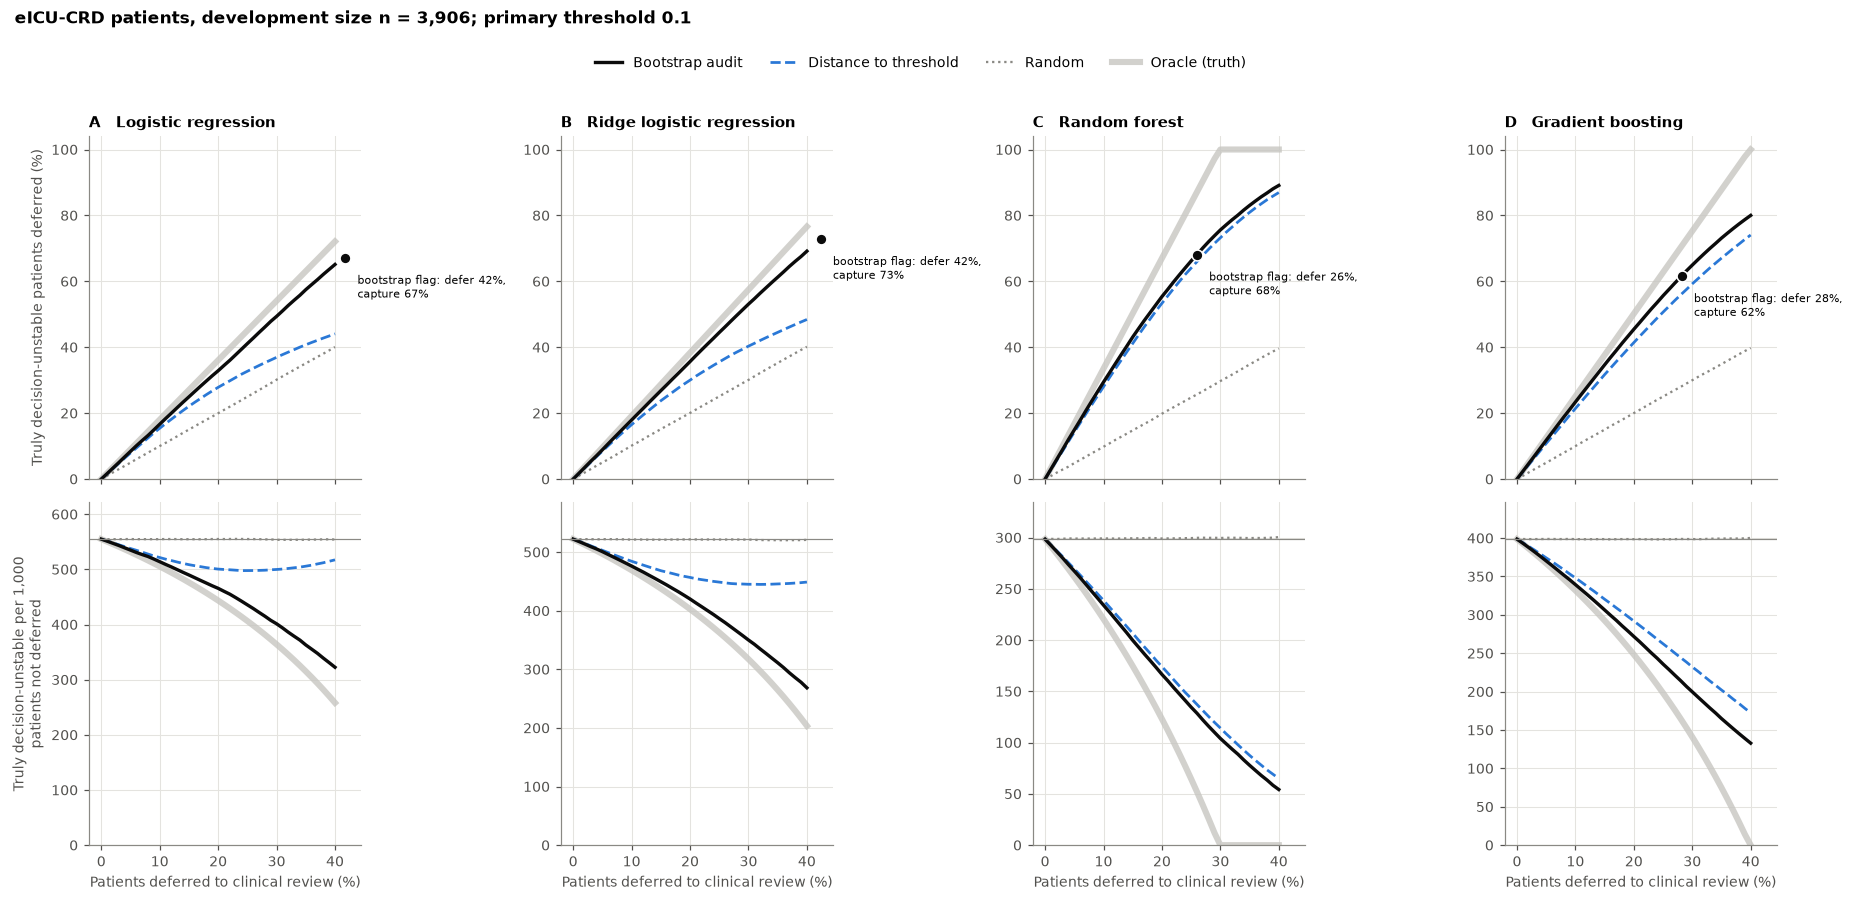

In [26]:
fig, axes = plt.subplots(2, len(MODELS_LIST), figsize=(4.2 * len(MODELS_LIST), 7.6), sharex=True)
axes = np.atleast_2d(axes)
pop = "eICU-CRD panel"
for j, m in enumerate(MODELS_LIST):
    cur = CURVES[(m, pop)]
    for key in ("oracle", "random", "distance", "bootstrap"):
        axes[0, j].plot(100 * DEFER_GRID, 100 * cur[key]["capture"], label=STRATEGIES[key], **STRAT_STYLE[key])
        axes[1, j].plot(100 * DEFER_GRID, cur[key]["residual_per_1000"], **STRAT_STYLE[key])
    op = focus[(focus["model"] == MODEL_LABELS[m]) & (focus["population"] == pop) & (focus["strategy"] == "bootstrap")]
    if len(op):
        q, c = float(op["deferred_share"].iloc[0]), float(op["capture"].iloc[0])
        axes[0, j].scatter([100 * q], [100 * c], s=50, color=INK, zorder=5, edgecolors="white")
        axes[0, j].annotate(f"bootstrap flag: defer {100 * q:.0f}%,\ncapture {100 * c:.0f}%", (100 * q, 100 * c), xytext=(8, -26),
                            textcoords="offset points", fontsize=7.5)
    axes[1, j].axhline(cur["truly_per_1000"], color=NEUTRAL, lw=0.8)
    axes[0, j].set_ylim(0, 104)
    axes[1, j].set_ylim(0, cur["truly_per_1000"] * 1.12)
    axes[0, j].set_title(MODEL_LABELS[m])
    axes[1, j].set_xlabel("Patients deferred to clinical review (%)")
    panel_label(axes[0, j], "ABCD"[j])
axes[0, 0].set_ylabel("Truly decision-unstable patients deferred (%)")
axes[1, 0].set_ylabel("Truly decision-unstable per 1,000\npatients not deferred")
fig.legend(handles=[Line2D([0], [0], label=STRATEGIES[k], **STRAT_STYLE[k]) for k in ("bootstrap", "distance", "random", "oracle")],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03))
fig.suptitle(f"eICU-CRD patients, development size n = {N_FOCUS:,}; primary threshold {T0:g}", x=0.01, ha="left", y=1.07, fontweight="bold")
fig.tight_layout()
save_figure(fig, "p3_fig8_deferral", "Deferral of decision-unstable patients: capture and residual instability by strategy")

## 10. Two sources of arbitrariness: model choice versus development sample (Figure P3-9, Table 15)

**Predictive multiplicity** (the Rashomon effect): many models fit the data almost equally well yet give different predictions to the same patient. **Instability**: the same specification refitted on another sample from the same population gives different predictions. Both make an individual's decision partly arbitrary, but they are usually studied separately.

Twelve specifications, fixed in advance, are fitted once on the notebook 2 development pool (the MIMIC-IV audit panel is held out) and ranked by AUROC on the audit panel. The Rashomon set holds those within 0.01 of the best (sensitivity: 0.02). In eICU-CRD: viable prediction range (largest minus smallest risk across the set), ambiguity (share of patients whose decision differs from the best model's for at least one model in the set) and discrepancy (largest share of decisions any one set member changes). Model-choice ambiguity is compared with **sample ambiguity measured the same way**: the original model plus bootstrap refits of the best model's class, as many models as in the Rashomon set, with the original model as reference (20 random draws of refits; a patient counts as sample-ambiguous when ambiguous in at least half of them). A third scenario uses the four pre-specified classes of notebook 2, with the class with the highest out-of-bag AUROC as reference (no external outcomes are used to choose references).

In [27]:
class GroupedImputer(BaseEstimator, TransformerMixin):
    """Median imputation, one missingness indicator per group of columns, optional standardisation."""

    def __init__(self, groups=None, scale=True):
        self.groups = groups
        self.scale = scale

    def _build(self, X):
        miss = np.isnan(X)
        Xi = np.where(miss, self.medians_, X)
        if self.indicator_groups_:
            Xi = np.column_stack([Xi] + [miss[:, g].any(axis=1).astype(float) for g in self.indicator_groups_])
        return Xi

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X, axis=0)
        self.medians_ = np.where(np.isnan(med), 0.0, med)
        self.indicator_groups_ = [list(g) for g in (self.groups or []) if np.isnan(X[:, g]).any()]
        if self.scale:
            Z = self._build(X)
            self.mean_ = Z.mean(axis=0)
            sd = Z.std(axis=0)
            self.sd_ = np.where(sd > 0, sd, 1.0)
        return self

    def transform(self, X):
        Z = self._build(np.asarray(X, dtype=float))
        return (Z - self.mean_) / self.sd_ if self.scale else Z


class SplineFirst(BaseEstimator, TransformerMixin):
    """Cubic B-spline basis for the first k columns; remaining columns passed through."""

    def __init__(self, k=1, n_knots=4):
        self.k = k
        self.n_knots = n_knots

    def fit(self, X, y=None):
        self.spline_ = SplineTransformer(n_knots=self.n_knots, degree=3, knots="uniform", extrapolation="linear").fit(X[:, :self.k])
        return self

    def transform(self, X):
        return np.column_stack([self.spline_.transform(X[:, :self.k]), X[:, self.k:]])


_lrcv = inspect.signature(LogisticRegressionCV).parameters
SK_VERSION = tuple(int(v) for v in sklearn.__version__.split(".")[:2])
RIDGE_KW = {}
if "l1_ratios" in _lrcv and SK_VERSION >= (1, 8):
    RIDGE_KW["l1_ratios"] = (0.0,)
if "use_legacy_attributes" in _lrcv:
    RIDGE_KW["use_legacy_attributes"] = False


def group_index(predictors):
    return [[predictors.index(c) for c in cols if c in predictors] for cols in GROUPS.values() if any(c in predictors for c in cols)]


def make_estimator(name, groups):
    if name == "lr":
        return Pipeline([("prep", GroupedImputer(groups)), ("model", LogisticRegression(C=np.inf, max_iter=10000))])
    if name == "ridge":
        return Pipeline([("prep", GroupedImputer(groups)),
                         ("model", LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=StratifiedKFold(5, shuffle=True, random_state=0),
                                                        scoring="neg_log_loss", max_iter=10000, **RIDGE_KW))])
    if name == "rf":
        return Pipeline([("prep", GroupedImputer(groups, scale=False)),
                         ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=1))])
    if name == "hgb":
        return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=50,
                                              l2_regularization=1.0, early_stopping=False)
    raise ValueError(name)


def l1_logistic(C):
    if SK_VERSION >= (1, 8):
        return LogisticRegression(l1_ratio=1.0, C=C, solver="liblinear", max_iter=5000)
    return LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=5000)


GROUP_INDEX = group_index(PRED)
SPECS = {
    "lr_main": ("lr", "LR, as notebook 2", lambda: make_estimator("lr", GROUP_INDEX)),
    "lr_noind": ("lr", "LR, no missingness indicators", lambda: Pipeline([("prep", GroupedImputer(None)), ("model", LogisticRegression(C=np.inf, max_iter=10000))])),
    "lr_l1": ("lr", "LR, lasso (C = 0.05)", lambda: Pipeline([("prep", GroupedImputer(GROUP_INDEX)), ("model", l1_logistic(0.05))])),
    "lr_spline": ("lr", "LR, cubic splines, ridge (C = 0.1)", lambda: Pipeline([("prep", GroupedImputer(GROUP_INDEX)), ("spline", SplineFirst(k=len(PRED))),
                                                                               ("model", LogisticRegression(C=0.1, max_iter=10000))])),
    "ridge_main": ("ridge", "Ridge LR, as notebook 2", lambda: make_estimator("ridge", GROUP_INDEX)),
    "rf_main": ("rf", "RF, as notebook 2", lambda: make_estimator("rf", GROUP_INDEX)),
    "rf_seed": ("rf", "RF, as notebook 2, other seed", lambda: make_estimator("rf", GROUP_INDEX)),
    "rf_deep": ("rf", "RF, leaf 5, 33% features", lambda: Pipeline([("prep", GroupedImputer(GROUP_INDEX, scale=False)),
                                                                    ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features=0.33, n_jobs=1))])),
    "rf_shallow": ("rf", "RF, 500 trees, leaf 50", lambda: Pipeline([("prep", GroupedImputer(GROUP_INDEX, scale=False)),
                                                                    ("model", RandomForestClassifier(n_estimators=500, min_samples_leaf=50, max_features="sqrt", n_jobs=1))])),
    "hgb_main": ("hgb", "GBM, as notebook 2", lambda: make_estimator("hgb", GROUP_INDEX)),
    "hgb_fast": ("hgb", "GBM, rate 0.1, 150 iterations, 31 leaves", lambda: HistGradientBoostingClassifier(
        learning_rate=0.1, max_iter=150, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0, early_stopping=False)),
    "hgb_slow": ("hgb", "GBM, rate 0.03, 500 iterations, 7 leaves", lambda: HistGradientBoostingClassifier(
        learning_rate=0.03, max_iter=500, max_leaf_nodes=7, min_samples_leaf=100, l2_regularization=1.0, early_stopping=False)),
}
SPECS = {k: v for k, v in SPECS.items() if v[0] in MODELS_LIST}


def spec_task(key, seed, Xtr, ytr, Xa, Xe):
    builder = ModelBuilder(SPECS[key][2]())
    model, n_conv = fit_quietly(builder, Xtr, ytr, random_state=seed % (2**31 - 1))
    return key, builder.predict_risk(model, Xa).astype(np.float32), builder.predict_risk(model, Xe).astype(np.float32), n_conv


mpath = CACHE / "multiplicity_specs.npz"
with timed("Multiplicity: fitting the candidate specifications"):
    if CONFIG["force"] or not mpath.exists():
        outs = run_parallel([delayed(spec_task)(k, seed_for("spec", k), X_dev[POOL], y_dev[POOL], X_dev[AUDIT], X_ext) for k in SPECS])
        np.savez_compressed(mpath, keys=np.array([o[0] for o in outs]), P_aud=np.vstack([o[1] for o in outs]),
                            P_ext=np.vstack([o[2] for o in outs]), n_conv=np.array([o[3] for o in outs]))
    mz = np.load(mpath)
SPEC_KEYS = [str(k) for k in mz["keys"]]
P_SPEC_AUD, P_SPEC_EXT = mz["P_aud"].astype(np.float64), mz["P_ext"].astype(np.float64)
spec_rows = []
for i, k in enumerate(SPEC_KEYS):
    p = np.clip(P_SPEC_AUD[i], EPS, 1 - EPS)
    spec_rows.append({"key": k, "class": SPECS[k][0], "specification": SPECS[k][1], "auroc_audit": auc_fast(y_aud, p),
                      "log_loss_audit": float(-np.mean(y_aud * np.log(p) + (1 - y_aud) * np.log(1 - p))),
                      "calibration_slope_audit": logistic_fit(y_aud, logit(p))[0], "auroc_external": auc_fast(y_ext, P_SPEC_EXT[i]),
                      "oe_external": y_ext.sum() / P_SPEC_EXT[i].sum(), "convergence_warnings": int(mz["n_conv"][i])})
SPEC_TABLE = pd.DataFrame(spec_rows)
for eps in (CONFIG["rashomon_epsilon"], CONFIG["rashomon_epsilon_sensitivity"]):
    SPEC_TABLE[f"rashomon_{eps:g}"] = rashomon_set(SPEC_TABLE["auroc_audit"], eps)
BEST = int(SPEC_TABLE["auroc_audit"].idxmax())
display(SPEC_TABLE.round(4))


>>> Multiplicity: fitting the candidate specifications
<<< Multiplicity: fitting the candidate specifications: 0.0 min


,key,class,specification,auroc_audit,log_loss_audit,calibration_slope_audit,auroc_external,oe_external,convergence_warnings,rashomon_0.01,rashomon_0.02
0,lr_main,lr,"LR, as notebook 2",0.8522,0.2394,0.9719,0.7806,0.7789,0,False,False
1,lr_noind,lr,"LR, no missingness indicators",0.8218,0.2531,0.9558,0.8205,0.9816,0,False,False
2,lr_l1,lr,"LR, lasso (C = 0.05)",0.8536,0.2389,1.0241,0.8062,0.7223,0,False,False
3,lr_spline,lr,"LR, cubic splines, ridge (C = 0.1)",0.8618,0.2339,1.0637,0.7892,0.7553,0,False,True
4,ridge_main,ridge,"Ridge LR, as notebook 2",0.8527,0.2390,0.9910,0.7907,0.7720,0,False,False
5,rf_main,rf,"RF, as notebook 2",0.8706,0.2335,1.4610,0.8340,0.7768,0,False,True
6,rf_seed,rf,"RF, as notebook 2, other seed",0.8711,0.2332,1.4670,0.8345,0.7846,0,True,True
7,rf_deep,rf,"RF, leaf 5, 33% features",0.8715,0.2275,1.1656,0.8281,0.6678,0,True,True
8,rf_shallow,rf,"RF, 500 trees, leaf 50",0.8651,0.2392,1.5751,0.8283,0.8072,0,False,True
9,hgb_main,hgb,"GBM, as notebook 2",0.8807,0.2212,0.9904,0.8363,0.7316,0,True,True


In [28]:
def ambiguity(P, ref_row):
    D = P >= T0
    return (D != D[ref_row][None, :]).any(axis=0)


def sample_matched(cls, m_models, n_draws=20):
    """Ambiguity and range across m_models bootstrap refits of a class (original model as reference)."""
    res = FULL_RES[cls]
    rng = np.random.default_rng(seed_for("matched", cls, m_models))
    amb = np.zeros(N_EXT)
    rng_range = np.zeros(N_EXT)
    if m_models < 2:
        return amb, rng_range
    k = min(m_models - 1, res.n_replicates)
    for _ in range(n_draws):
        pick = rng.choice(res.n_replicates, size=k, replace=False)
        P = np.vstack([res.p_original_external[None, :], res.P_external[pick].astype(np.float64)])
        amb += ambiguity(P, 0)
        rng_range += P.max(axis=0) - P.min(axis=0)
    return amb / n_draws, rng_range / n_draws


oob_auc = {m: float(FULL_RES[m].optimism().set_index("metric").loc["auroc", "oob_mean"]) for m in MODELS_LIST}
best_class = SPEC_TABLE.loc[BEST, "class"]
SCEN = {}
for eps in (CONFIG["rashomon_epsilon"], CONFIG["rashomon_epsilon_sensitivity"]):
    mask = SPEC_TABLE[f"rashomon_{eps:g}"].to_numpy()
    members = np.flatnonzero(mask)
    SCEN[f"Rashomon set, AUROC within {eps:g}"] = {"P": P_SPEC_EXT[members], "ref": int(np.flatnonzero(members == BEST)[0]),
                                                  "cls": best_class, "members": [SPEC_KEYS[i] for i in members]}
four_ref = max(MODELS_LIST, key=lambda m: oob_auc[m])
SCEN["Four pre-specified model classes"] = {"P": np.vstack([FULL_RES[m].p_original_external for m in MODELS_LIST]),
                                            "ref": MODELS_LIST.index(four_ref), "cls": four_ref, "members": MODELS_LIST}

mult_rows, AMB = [], {}
for name, sc in SCEN.items():
    P = sc["P"]
    k_models = P.shape[0]
    model_amb = ambiguity(P, sc["ref"]) if k_models > 1 else np.zeros(N_EXT, bool)
    vpr = P.max(axis=0) - P.min(axis=0)
    samp_amb_p, samp_range = sample_matched(sc["cls"], k_models)
    meas = multiplicity_measures(P, THRESHOLDS, reference=sc["ref"]) if k_models > 1 else {}
    AMB[name] = {"model": model_amb, "sample_p": samp_amb_p, "vpr": vpr, "sample_range": samp_range, "risk": P[sc["ref"]]}
    samp_amb = samp_amb_p >= 0.5
    mult_rows.append({"scenario": name, "models": k_models, "reference": sc["cls"], "members": ", ".join(sc["members"]),
                      "vpr_median": float(np.median(vpr)), "vpr_p90": float(np.quantile(vpr, 0.9)),
                      "sample_range_median": float(np.median(samp_range)), "sample_range_p90": float(np.quantile(samp_range, 0.9)),
                      "model_ambiguous_per_1000": 1000 * model_amb.mean(), "sample_ambiguous_per_1000": 1000 * samp_amb_p.mean(),
                      "both_per_1000": 1000 * np.mean(model_amb & samp_amb), "model_only_per_1000": 1000 * np.mean(model_amb & ~samp_amb),
                      "sample_only_per_1000": 1000 * np.mean(~model_amb & samp_amb),
                      "either_per_1000": 1000 * np.mean(model_amb | samp_amb),
                      **{f"discrepancy@{t:g}": meas.get(f"discrepancy@{t:g}", np.nan) for t in THRESHOLDS},
                      **{f"ambiguity@{t:g}": meas.get(f"ambiguity@{t:g}", np.nan) for t in THRESHOLDS}})
TABLE15 = pd.DataFrame(mult_rows)
save_table(SPEC_TABLE.round(4), "tableS_p3_candidate_specifications", "Candidate specifications, audit-panel performance and Rashomon membership")
save_table(TABLE15.round(4), "table15_multiplicity_vs_instability",
           "Decision ambiguity in eICU-CRD from model choice (Rashomon set) and from the development sample, measured the same way")
display(TABLE15.drop(columns="members").round(3))

,scenario,models,reference,vpr_median,vpr_p90,sample_range_median,sample_range_p90,model_ambiguous_per_1000,sample_ambiguous_per_1000,both_per_1000,model_only_per_1000,sample_only_per_1000,either_per_1000,discrepancy@0.1,discrepancy@0.2,discrepancy@0.3,ambiguity@0.1,ambiguity@0.2,ambiguity@0.3
0,"Rashomon set, AUROC within 0.01",5,hgb,0.066,0.208,0.047,0.194,266.878,191.251,134.273,132.605,53.701,320.579,0.176,0.116,0.080,0.267,0.193,0.130
1,"Rashomon set, AUROC within 0.02",8,hgb,0.081,0.265,0.061,0.249,333.893,244.879,191.279,142.614,54.572,388.465,0.176,0.116,0.090,0.334,0.238,0.162
2,Four pre-specified model classes,4,hgb,0.055,0.204,0.040,0.169,271.373,167.456,121.661,149.712,39.527,310.900,0.158,0.113,0.075,0.271,0.159,0.108


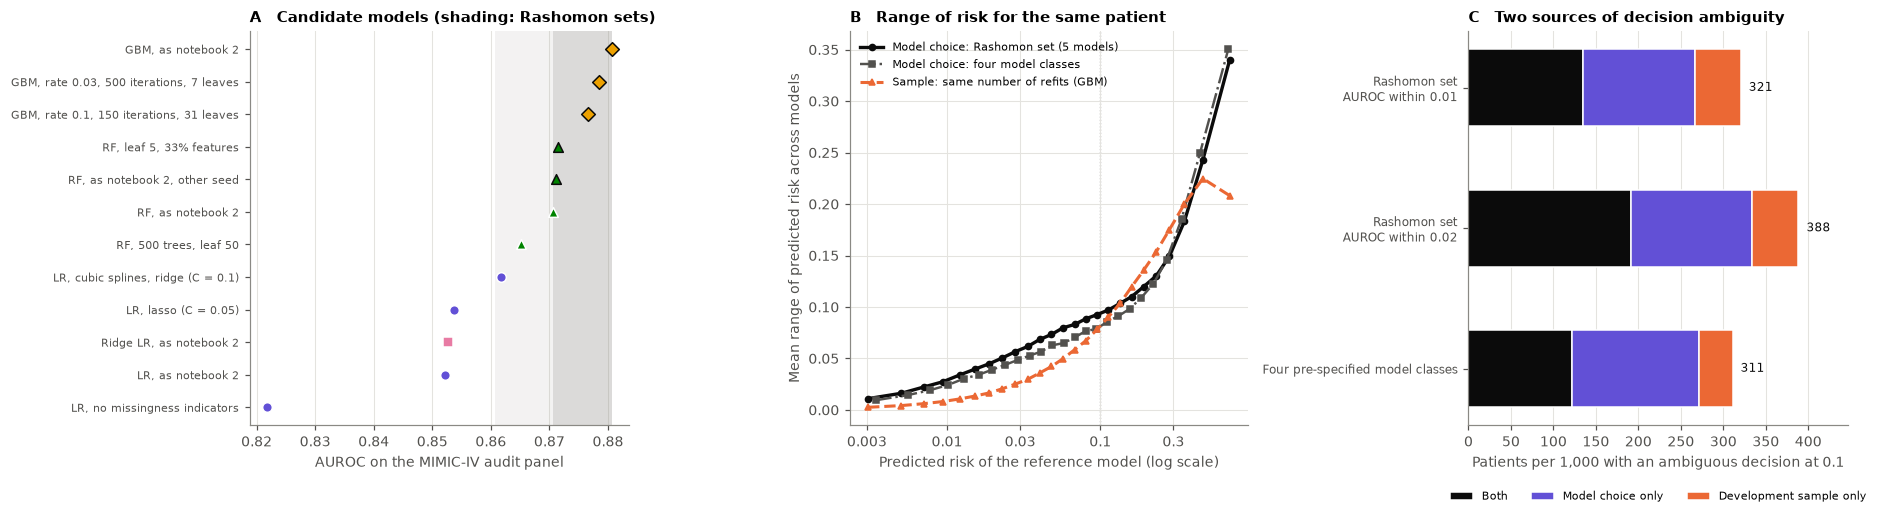

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.05, 1.1, 1.05]})
ax = axes[0]
order = SPEC_TABLE.sort_values("auroc_audit").reset_index(drop=True)
best = order["auroc_audit"].max()
ax.axvspan(best - CONFIG["rashomon_epsilon_sensitivity"], best, color=NEUTRAL, alpha=0.10, lw=0)
ax.axvspan(best - CONFIG["rashomon_epsilon"], best, color=NEUTRAL, alpha=0.22, lw=0)
for i, r in order.iterrows():
    ax.scatter(r["auroc_audit"], i, color=MODEL_COLORS[r["class"]], marker=MODEL_MARKERS[r["class"]], s=40, zorder=3,
               edgecolors=INK if r["rashomon_0.01"] else "white", linewidths=1.0)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["specification"], fontsize=7.5)
ax.set_xlabel("AUROC on the MIMIC-IV audit panel")
ax.set_title("Candidate models (shading: Rashomon sets)")
ax.grid(axis="y", visible=False)
panel_label(ax, "A")

ax = axes[1]
main = f"Rashomon set, AUROC within {CONFIG['rashomon_epsilon']:g}"
a = AMB[main]
xb, yb = binned_curve(np.clip(a["risk"], 1e-4, 1 - 1e-4), a["vpr"])
xs_, ys_ = binned_curve(np.clip(a["risk"], 1e-4, 1 - 1e-4), a["sample_range"])
a4 = AMB["Four pre-specified model classes"]
x4, y4 = binned_curve(np.clip(a4["risk"], 1e-4, 1 - 1e-4), a4["vpr"])
ax.plot(xb, yb, color=INK, lw=2.2, marker="o", markersize=4, label=f"Model choice: Rashomon set ({len(SCEN[main]['members'])} models)")
ax.plot(x4, y4, color=INK2, lw=1.6, ls="-.", marker="s", markersize=4, label="Model choice: four model classes")
ax.plot(xs_, ys_, color=DB_COLORS["eICU-CRD"], lw=2.0, ls="--", marker="^", markersize=4,
        label=f"Sample: same number of refits ({MODEL_SHORT[SCEN[main]['cls']]})")
ax.set_xscale("log")
risk_log_axis(ax.xaxis, float(min(xb.min(), xs_.min())), float(max(xb.max(), xs_.max())))
ax.axvline(T0, color=INK2, lw=0.8, ls=":", zorder=0)
ax.set_xlabel("Predicted risk of the reference model (log scale)")
ax.set_ylabel("Mean range of predicted risk across models")
ax.set_title("Range of risk for the same patient")
ax.legend(fontsize=7.5, loc="upper left")
panel_label(ax, "B")

ax = axes[2]
names = list(SCEN)
parts = [("both_per_1000", "Both", INK), ("model_only_per_1000", "Model choice only", "#6250d6"),
         ("sample_only_per_1000", "Development sample only", DB_COLORS["eICU-CRD"])]
left = np.zeros(len(names))
for col, label, color in parts:
    vals = TABLE15.set_index("scenario").loc[names, col].to_numpy()
    ax.barh(range(len(names)), vals, left=left, color=color, height=0.55, label=label, edgecolor="white", linewidth=1)
    left += vals
for i, v in enumerate(left):
    ax.text(v, i, f"  {v:.0f}", va="center", fontsize=8, color=INK)
ax.set_yticks(range(len(names)))
ax.set_yticklabels([n.replace(", AUROC", "\nAUROC") for n in names], fontsize=8)
ax.invert_yaxis()
ax.set_xlim(0, left.max() * 1.15)
ax.set_xlabel(f"Patients per 1,000 with an ambiguous decision at {T0:g}")
ax.set_title("Two sources of decision ambiguity")
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)
ax.grid(axis="y", visible=False)
panel_label(ax, "C")
fig.tight_layout()
save_figure(fig, "p3_fig9_multiplicity_vs_instability", "Predictive multiplicity versus development-sample instability in eICU-CRD")

## 11. Pre-specified sensitivity analyses (Figure P3-10, Table 16)

Each analysis changes one element and repeats the audit with B = 100 refits (the primary analysis is shown with its first 100 refits so that all rows have the same number of models). Refitted audits are cached, so this cell can be interrupted and resumed. `STUDY_P3_SENS_MODELS` can restrict the model classes if time is short.

| Analysis | Change | Question |
|---|---|---|
| S1 | All eligible ICU stays (not only the first per patient), bootstrap of patients (cluster bootstrap); external: all eICU-CRD stays | Is the result an artefact of the first-stay restriction? |
| S2 | Secondary outcome: ICU stay of 7 days or more | Does instability transport differently for a resource outcome? |
| S3 | Vital signs summarised from hourly means | Does the vital-sign extraction rule matter? |
| S4a | Model without the GCS motor score | Does the predictor with the most site-dependent charting drive transport? |
| S4b | External evaluation only in hospitals that chart the GCS motor score (at most 10% missing) | Same question, without refitting |
| S5 | Random forest recalibrated with out-of-bag predictions (logistic recalibration per refit) | Is the random forest result a calibration artefact? |
| S6 | Hospitals with at least 50 stays in the meta-analysis | Does the hospital threshold change heterogeneity? |
| S7 (post hoc) | Logistic, ridge and random forest refitted without missingness indicators (median imputation only; gradient boosting handles missing values natively and is not refitted) | Do missingness indicators learned in MIMIC-IV drive instability transport? |

In [30]:
B_SENS = CONFIG["b_sens"]
MIN_OOB = 5 if B_SENS >= 50 else 2
SENS_MODELS = [m for m in SENS_MODELS if m in MODELS_LIST]


def recal_fit(y, lp):
    X = np.column_stack([np.ones_like(lp), lp])
    beta = np.array([0.0, 1.0])
    for _ in range(100):
        mu = expit(X @ beta)
        H = X.T @ (X * (mu * (1 - mu))[:, None])
        step = np.linalg.solve(H + 1e-9 * np.eye(2), X.T @ (y - mu))
        beta += step
        if np.max(np.abs(step)) < 1e-9:
            break
    return beta


def sens_summary(scenario, m, y_d, P, inbag, y_e, p_e, P_e, n_dev, rows_e=None):
    P = np.asarray(P, dtype=np.float64)
    dev_s = spread_summary(P, use=~inbag)
    ok = dev_s["n_models"] >= MIN_OOB
    if rows_e is not None:
        y_e, p_e, P_e = y_e[rows_e], p_e[rows_e], P_e[:, rows_e]
    ext_s = spread_summary(P_e, ref=p_e)
    curve = risk_curve(dev_s["mean"][ok], dev_s["sd"][ok])
    met = ext_metrics(y_e, p_e)
    oob_auc = np.nanmean([auc_fast(y_d[~inbag[b]], P[b, ~inbag[b]]) for b in range(min(P.shape[0], 50))])
    return {"scenario": scenario, "model": m, "n_development": n_dev, "n_external": int(y_e.size),
            "events_external": int(y_e.sum()), "auroc_oob": oob_auc, "auroc_external": met["auroc"], "oe_external": met["oe_ratio"],
            "slope_external": met["calibration_slope"], "instability_index_external": float(np.mean(ext_s["mape"])),
            "mean_sd_external": float(np.mean(ext_s["sd"])), "itr": ext_s["sd"].sum() / curve(ext_s["mean"]).sum(),
            "unstable_per_1000_development": 1000 * float(np.mean(dev_s[f"minority_emp@{T0:g}"][ok] > UNSTABLE)),
            "unstable_per_1000_external": 1000 * float(np.mean(ext_s[f"minority_emp@{T0:g}"] > UNSTABLE))}


def sens_data(key):
    cluster = SPEC.get("cluster_column", "patient_id")
    if key == "S1":
        d = pd.read_parquet(PROJECT / SPEC["datasets"]["development_all_stays"])
        e = pd.read_parquet(PROJECT / SPEC["datasets"]["external_all_stays"])
        return dict(Xd=d[PRED].to_numpy(np.float64), yd=d[OUTCOME].to_numpy(np.int64), Xe=e[PRED].to_numpy(np.float64),
                    ye=e[OUTCOME].to_numpy(np.int64), groups=d[cluster].astype(str).to_numpy(), scheme="cluster", gi=GROUP_INDEX)
    if key == "S2":
        return dict(Xd=X_dev, yd=dev[OUTCOME2].to_numpy(np.int64), Xe=X_ext, ye=ext[OUTCOME2].to_numpy(np.int64),
                    groups=None, scheme="simple", gi=GROUP_INDEX)
    if key == "S3":
        hourly = [SPEC["sensitivity_vital_columns"].get(c, c) for c in PRED]
        return dict(Xd=dev[hourly].to_numpy(np.float64), yd=y_dev, Xe=ext[hourly].to_numpy(np.float64), ye=y_ext,
                    groups=None, scheme="simple", gi=GROUP_INDEX)
    if key == "S4a":
        keep = [c for c in PRED if c != "gcs_motor_min"]
        return dict(Xd=dev[keep].to_numpy(np.float64), yd=y_dev, Xe=ext[keep].to_numpy(np.float64), ye=y_ext,
                    groups=None, scheme="simple", gi=group_index(keep))
    if key == "S7":
        return dict(Xd=X_dev, yd=y_dev, Xe=X_ext, ye=y_ext, groups=None, scheme="simple", gi=None)
    raise ValueError(key)


def run_sens(key, m):
    base = CACHE / f"sens_{key}_{m}"
    files = {"npz": base.with_suffix(".npz"), "metrics": Path(str(base) + "_replicates.parquet")}
    data = sens_data(key)
    if CONFIG["force"] or not all(p.exists() for p in files.values()):
        audit = StabilityAudit(make_estimator(m, data["gi"]), n_bootstrap=B_SENS, bootstrap=data["scheme"], thresholds=THRESHOLDS,
                               optimism=True, n_jobs=N_JOBS, random_state=seed_for("sens", key, m), smooth_calibration=False)
        with parallel_config(backend="loky", inner_max_num_threads=1):
            res = audit.run(data["Xd"], data["yd"], groups=data["groups"], X_external=data["Xe"], y_external=data["ye"])
        np.savez_compressed(files["npz"], p=res.p_original, P=res.P.astype(np.float32), p_ext=res.p_original_external,
                            P_ext=res.P_external.astype(np.float32))
        res.replicate_metrics.to_parquet(files["metrics"], index=False)
        del res
    z = np.load(files["npz"])
    metrics = pd.read_parquet(files["metrics"])
    inbag = inbag_from(metrics, data["yd"], scheme=data["scheme"],
                       groups=data["groups"] if data["scheme"] == "cluster" else None)
    return sens_summary(key, m, data["yd"], z["P"], inbag, data["ye"], z["p_ext"].astype(np.float64), z["P_ext"], data["yd"].size)


SENS_LABELS = {"Primary": "Primary analysis", "S1": "S1 all stays, patient bootstrap", "S2": "S2 ICU stay of 7 days or more",
               "S3": "S3 hourly-mean vital signs", "S4a": "S4a without GCS motor score",
               "S4b": "S4b hospitals charting GCS motor", "S5": "S5 random forest recalibrated",
               "S7": "S7 no missingness indicators (post hoc)"}
sens_rows = []
with timed("Sensitivity analyses"):
    for m in MODELS_LIST:
        res = FULL_RES[m]
        b = min(B_SENS, res.n_replicates)
        sens_rows.append(sens_summary("Primary", m, y_dev, res.P[:b], INBAG[m][:b], y_ext, res.p_original_external,
                                      res.P_external[:b], N_DEV))
        charting = ext["site_id"].map(motor_missing).to_numpy() <= CONFIG["gcs_charting_max_missing"]
        if 200 <= charting.sum() < N_EXT:
            sens_rows.append(sens_summary("S4b", m, y_dev, res.P[:b], INBAG[m][:b], y_ext, res.p_original_external,
                                          res.P_external[:b], N_DEV, rows_e=np.flatnonzero(charting)))
    if "rf" in MODELS_LIST:
        res = FULL_RES["rf"]
        b = min(B_SENS, res.n_replicates)
        M, P, Pe = INBAG["rf"][:b], res.P[:b].astype(np.float64), res.P_external[:b].astype(np.float64)
        P_rec, Pe_rec = np.empty_like(P), np.empty_like(Pe)
        for j in range(b):
            a0, a1 = recal_fit(y_dev[~M[j]], logit(P[j, ~M[j]]))
            P_rec[j], Pe_rec[j] = expit(a0 + a1 * logit(P[j])), expit(a0 + a1 * logit(Pe[j]))
        ok = DEV_OOB["rf"]["n_models"] >= MIN_OOB
        c0, c1 = recal_fit(y_dev[ok], logit(DEV_OOB["rf"]["mean"][ok]))
        sens_rows.append(sens_summary("S5", "rf", y_dev, P_rec, M, y_ext, expit(c0 + c1 * logit(res.p_original_external)), Pe_rec, N_DEV))
    for key in ("S1", "S2", "S3", "S4a", "S7"):
        for m in SENS_MODELS:
            if key == "S7" and m == "hgb":
                continue
            t0 = time.perf_counter()
            sens_rows.append(run_sens(key, m))
            print(f"   {key:<4} {MODEL_LABELS[m]:<27} {(time.perf_counter() - t0) / 60:5.1f} min", flush=True)
TABLE16 = pd.DataFrame(sens_rows)
TABLE16.insert(1, "analysis", TABLE16["scenario"].map(SENS_LABELS))
save_table(TABLE16.assign(model=TABLE16["model"].map(MODEL_LABELS)).round(5), "table16_sensitivity_analyses",
           "Pre-specified sensitivity analyses: external performance, instability transport and decision instability")

META50 = pd.concat([meta_table(HOSP_T50[m], m) for m in MODELS_LIST], ignore_index=True)
META50["hospital_minimum"] = CONFIG["min_hospital_stays_sensitivity"]
save_table(META50.assign(model=META50["model"].map(MODEL_LABELS)).round(4), "tableS_p3_meta_analysis_min50",
           "S6: random-effects meta-analysis including hospitals with at least 50 stays")
display(TABLE16.drop(columns="scenario").round(3))


>>> Sensitivity analyses
   S1   Logistic regression           0.1 min
   S1   Ridge logistic regression     0.1 min
   S1   Random forest                 0.1 min
   S1   Gradient boosting             0.1 min
   S2   Logistic regression           0.0 min
   S2   Ridge logistic regression     0.0 min
   S2   Random forest                 0.0 min
   S2   Gradient boosting             0.0 min
   S3   Logistic regression           0.0 min
   S3   Ridge logistic regression     0.0 min
   S3   Random forest                 0.0 min
   S3   Gradient boosting             0.0 min
   S4a  Logistic regression           0.0 min
   S4a  Ridge logistic regression     0.0 min
   S4a  Random forest                 0.0 min
   S4a  Gradient boosting             0.0 min
   S7   Logistic regression           0.0 min
   S7   Ridge logistic regression     0.0 min
   S7   Random forest                 0.0 min
<<< Sensitivity analyses: 1.2 min


,analysis,model,n_development,n_external,events_external,auroc_oob,auroc_external,oe_external,slope_external,instability_index_external,mean_sd_external,itr,unstable_per_1000_development,unstable_per_1000_external
0,Primary analysis,lr,39966,94114,8753,0.851,0.807,0.800,0.758,0.029,0.037,3.165,76.490,247.901
1,S4b hospitals charting GCS motor,lr,39966,37590,3563,0.851,0.816,0.824,0.732,0.022,0.029,2.490,76.490,170.843
2,Primary analysis,ridge,39966,94114,8753,0.853,0.808,0.806,0.778,0.026,0.033,2.863,75.089,252.088
3,S4b hospitals charting GCS motor,ridge,39966,37590,3563,0.853,0.817,0.838,0.760,0.019,0.024,2.190,75.089,163.128
4,Primary analysis,rf,39966,94114,8753,0.872,0.835,0.783,1.560,0.013,0.014,0.981,111.795,150.817
5,S4b hospitals charting GCS motor,rf,39966,37590,3563,0.872,0.849,0.865,1.487,0.013,0.014,0.996,111.795,137.324
6,Primary analysis,hgb,39966,94114,8753,0.879,0.839,0.750,0.930,0.032,0.036,1.103,149.052,224.727
7,S4b hospitals charting GCS motor,hgb,39966,37590,3563,0.879,0.854,0.831,0.920,0.029,0.032,1.114,149.052,195.823
8,S5 random forest recalibrated,rf,39966,94114,8753,0.872,0.835,0.779,1.043,0.017,0.018,0.978,106.791,151.742
9,"S1 all stays, patient bootstrap",lr,57464,128886,11829,0.837,0.792,0.622,0.691,0.029,0.037,3.026,75.630,223.073


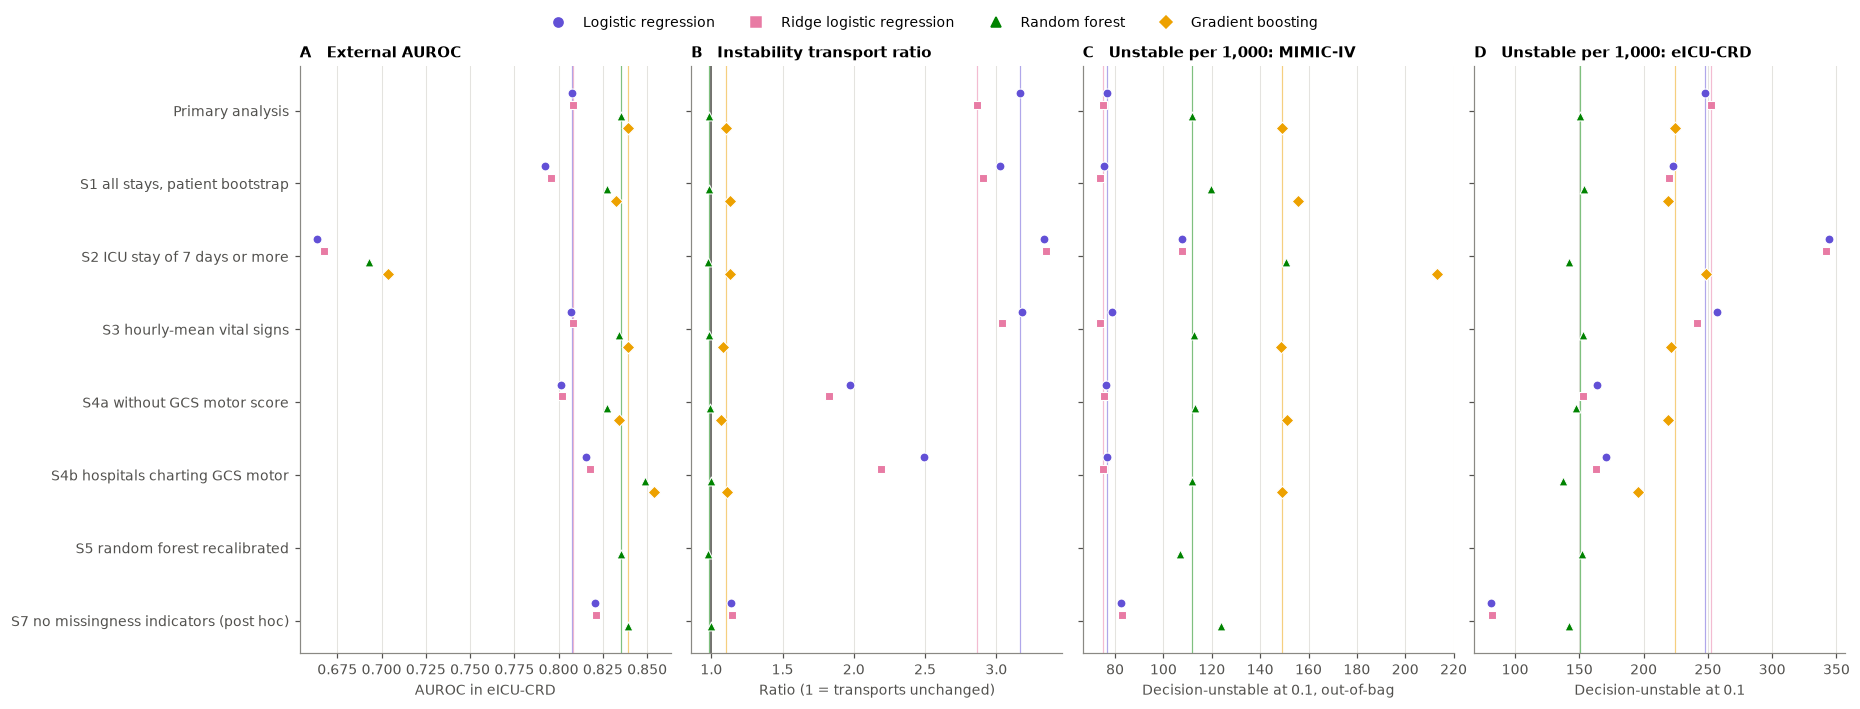

In [31]:
scen_order = [s for s in SENS_LABELS if s in set(TABLE16["scenario"])]
cols = [("auroc_external", "External AUROC", False), ("itr", "Instability transport ratio", True),
        ("unstable_per_1000_development", "Unstable per 1,000: MIMIC-IV", False),
        ("unstable_per_1000_external", "Unstable per 1,000: eICU-CRD", False)]
XLABELS = {"auroc_external": "AUROC in eICU-CRD", "itr": "Ratio (1 = transports unchanged)",
           "unstable_per_1000_development": f"Decision-unstable at {T0:g}, out-of-bag", "unstable_per_1000_external": f"Decision-unstable at {T0:g}"}
fig, axes = plt.subplots(1, 4, figsize=(17, 0.55 * len(scen_order) + 1.8), sharey=True)
off = np.linspace(-0.24, 0.24, len(MODELS_LIST))
for ax, (col, title, is_ratio), letter in zip(axes, cols, "ABCD"):
    for o, m in zip(off, MODELS_LIST):
        t = TABLE16[TABLE16["model"] == m].set_index("scenario")
        yy = [scen_order.index(s) + o for s in t.index]
        ax.scatter(t[col], yy, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], s=34, zorder=3, edgecolors="white", linewidths=0.7)
    prim = TABLE16[TABLE16["scenario"] == "Primary"]
    for m in MODELS_LIST:
        v = prim.loc[prim["model"] == m, col]
        if len(v):
            ax.axvline(float(v.iloc[0]), color=MODEL_COLORS[m], lw=0.8, alpha=0.5, zorder=1)
    if is_ratio:
        ax.axvline(1, color=INK2, lw=1)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(XLABELS[col])
    ax.grid(axis="y", visible=False)
    panel_label(ax, letter)
axes[0].set_yticks(range(len(scen_order)))
axes[0].set_yticklabels([SENS_LABELS[s] for s in scen_order])
axes[0].invert_yaxis()
fig.legend(handles=model_handles(MODELS_LIST, line=False), loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save_figure(fig, "p3_fig10_sensitivity_analyses", "Pre-specified sensitivity analyses")

## 12. Governance: pre-specified stability policy, report card and model facts (Figure P3-11, Table 17)

A model inventory or an AI governance committee needs a yes/no answer before deployment. The policy below was fixed before any external result was seen and is applied, unchanged, to the development and the external population (`cpmaudit.StabilityPolicy`, default limits):

| Check | Limit |
|---|---|
| Instability index (mean absolute prediction error) | at most 0.02 |
| 90th percentile of individual MAPE | at most 0.05 |
| Share of patients with a 95% instability interval wider than 0.10 | at most 10% |
| Share of flip-prone patients at each threshold (decision changes in more than 10% of refits) | at most 5% |
| Absolute optimism of the calibration slope | at most 0.10 |
| Successful refits | at least 200 |

The calibration-slope check uses Harrell's bootstrap optimism, which notebook 2 showed to be over-optimistic for random forests and boosting; for those classes a failure on this check is conservative. The policy's flip-prone measure compares each refit with the original model (classification instability index), a slightly stricter definition than the "decision-unstable" measure used elsewhere (minority share across refits). The model facts add the external results needed for a model card: pooled external performance with its hospital prediction interval, the instability transport ratio, and the expected deferral workload in other hospitals.

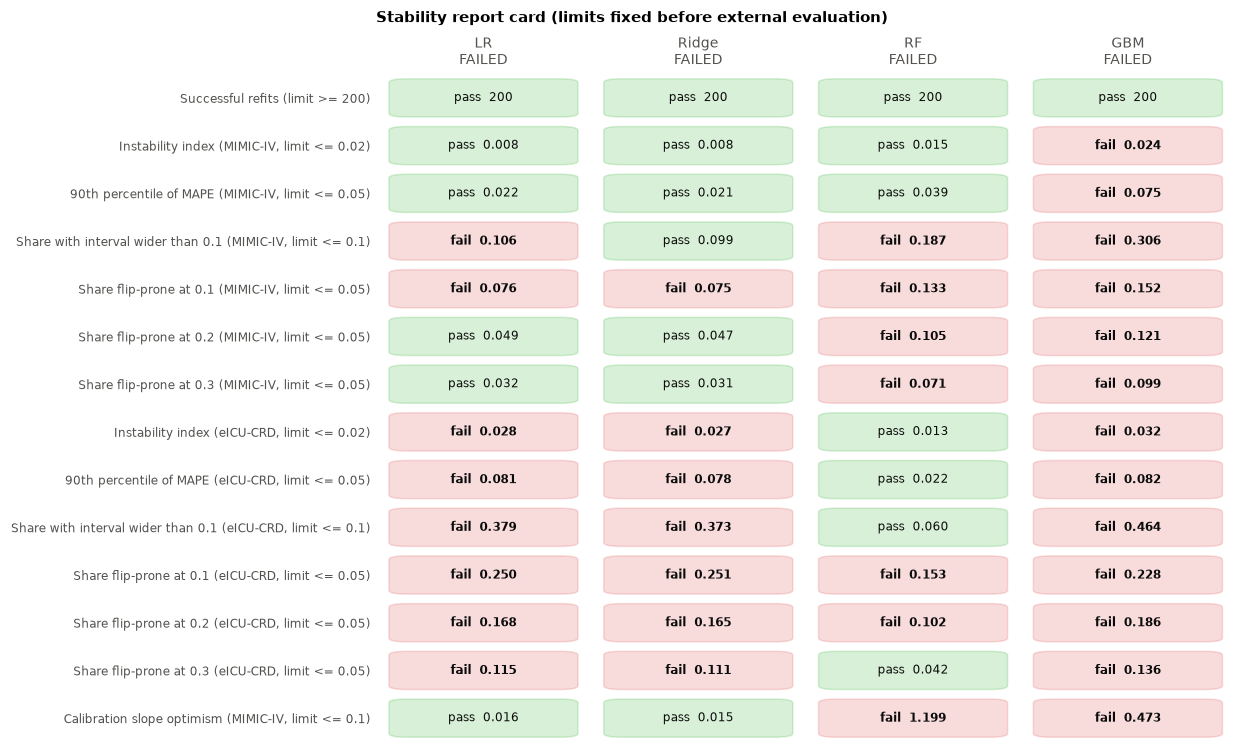

,policy,failed checks
Logistic regression,failed,"share_wide_interval, share_flip_prone@0.1, ins..."
Ridge logistic regression,failed,"share_flip_prone@0.1, instability_index, mape_..."
Random forest,failed,"share_wide_interval, share_flip_prone@0.1, sha..."
Gradient boosting,failed,"instability_index, mape_p90, share_wide_interv..."


In [32]:
POLICY = StabilityPolicy(populations=["development", "external"], flip_tolerance=UNSTABLE, wide_interval=WIDE)
REPORTS = {m: POLICY.evaluate(FULL_RES[m]) for m in MODELS_LIST}
TABLE17 = pd.concat([r.checks.assign(model=MODEL_LABELS[m]) for m, r in REPORTS.items()], ignore_index=True)
save_table(TABLE17.round(5), "table17_stability_policy", "Pre-specified stability policy applied to every model in both populations")
FACTS = {}
for m in MODELS_LIST:
    facts = model_facts(FULL_RES[m])
    meta = TABLE11[TABLE11["model"] == m].set_index("metric")
    t9 = TABLE9[TABLE9["model"] == m].set_index("metric")
    facts.update({
        "policy_passed": bool(REPORTS[m].passed), "policy_failed_checks": REPORTS[m].failed()["check"].tolist(),
        "external_population": f"eICU-CRD, {N_EXT} patients, {len(HOSP_CODES)} hospitals",
        "external_auroc": float(t9.loc["auroc", "external"]), "external_auroc_ci": [float(t9.loc["auroc", "lower"]), float(t9.loc["auroc", "upper"])],
        "external_oe": float(t9.loc["oe_ratio", "external"]),
        "hospital_auroc_prediction_interval": [float(meta.loc["AUROC", "pi_lower"]), float(meta.loc["AUROC", "pi_upper"])] if "AUROC" in meta.index else None,
        "hospital_oe_prediction_interval": [float(meta.loc["O/E", "pi_lower"]), float(meta.loc["O/E", "pi_upper"])] if "O/E" in meta.index else None,
        "instability_transport_ratio": [ITR[m]["itr"], ITR[m]["lower"], ITR[m]["upper"]],
        "external_deferral_workload_at_primary_threshold": float(np.mean(EXT_S[m][f"minority_emp@{T0:g}"] > UNSTABLE)),
        "decision_instability_ratio": [ITR[m]["dir"], ITR[m]["dir_lower"], ITR[m]["dir_upper"]],
    })
    FACTS[m] = facts
    save_json(facts, f"model_facts_{m}", f"Model facts for a model card, {MODEL_LABELS[m]}", folder="tables")

CHECK_LABELS = {"replicates": "Successful refits", "instability_index": "Instability index", "mape_p90": "90th percentile of MAPE",
                "share_wide_interval": f"Share with interval wider than {WIDE:g}", "abs_calibration_slope_optimism": "Calibration slope optimism"}
checks = TABLE17[["population", "check", "limit"]].drop_duplicates(subset=["population", "check"])


def check_label(r):
    base = CHECK_LABELS.get(r.check, r.check.replace("share_flip_prone@", "Share flip-prone at "))
    sign = ">=" if r.check == "replicates" else "<="
    pop = {"all": "", "development": "MIMIC-IV, ", "external": "eICU-CRD, "}[r.population]
    return f"{base} ({pop}limit {sign} {r.limit:g})"


labels = [check_label(r) for r in checks.itertuples()]
fig, ax = plt.subplots(figsize=(2.2 + 2.3 * len(MODELS_LIST), 0.38 * len(checks) + 1.6))
for j, m in enumerate(MODELS_LIST):
    t = TABLE17[TABLE17["model"] == MODEL_LABELS[m]]
    for i, r in enumerate(checks.itertuples()):
        row = t[(t["population"] == r.population) & (t["check"] == r.check)]
        if row.empty:
            continue
        row = row.iloc[0]
        color = STATUS["pass"] if row["passed"] else STATUS["fail"]
        ax.add_patch(FancyBboxPatch((j + 0.06, i + 0.1), 0.88, 0.8, boxstyle="round,pad=0,rounding_size=0.08",
                                    facecolor=color, alpha=0.16, edgecolor=color, lw=1.0))
        value = f"{row['value']:.0f}" if r.check == "replicates" else f"{row['value']:.3f}"
        ax.text(j + 0.5, i + 0.5, f"{'pass' if row['passed'] else 'fail'}  {value}", ha="center", va="center", fontsize=8,
                color=INK, fontweight="bold" if not row["passed"] else "normal")
ax.set_xlim(0, len(MODELS_LIST))
ax.set_ylim(len(checks), 0)
ax.set_xticks(np.arange(len(MODELS_LIST)) + 0.5)
ax.set_xticklabels([f"{MODEL_SHORT[m]}\n{'PASSED' if REPORTS[m].passed else 'FAILED'}" for m in MODELS_LIST], fontsize=9)
ax.xaxis.tick_top()
ax.set_yticks(np.arange(len(checks)) + 0.5)
ax.set_yticklabels(labels, fontsize=8)
ax.grid(False)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Stability report card (limits fixed before external evaluation)", pad=34)
fig.tight_layout()
save_figure(fig, "p3_fig11_stability_report_card", "Pre-specified stability policy: pass or fail for every check, model and population")
display(pd.DataFrame({MODEL_LABELS[m]: {"policy": "passed" if REPORTS[m].passed else "failed",
                                        "failed checks": ", ".join(FACTS[m]["policy_failed_checks"]) or "none"} for m in MODELS_LIST}).T)

## 13. Central illustration

One figure that carries the study's message for a broad clinical readership: population-level validation, the individual decisions that depend on the development sample in each population, why instability grows outside the development hospital, and what deferral achieves. All numbers are drawn from the analyses above.

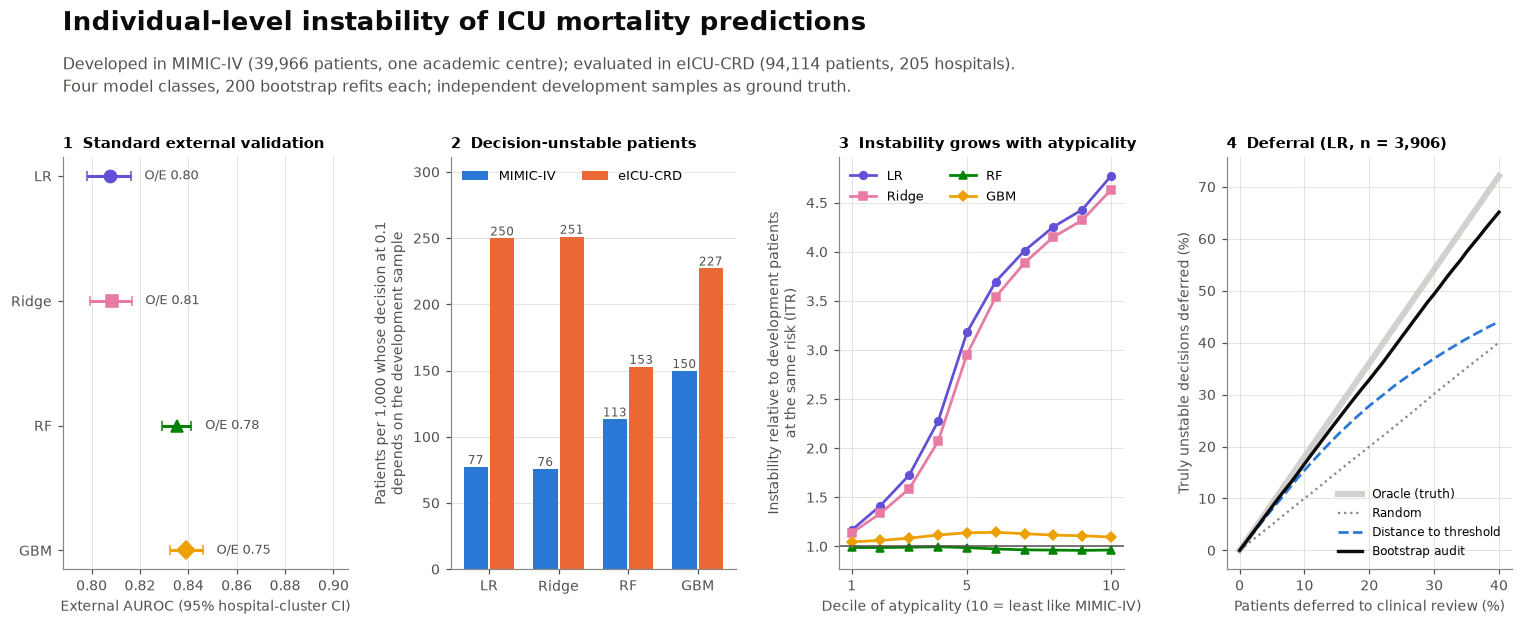

In [33]:
fig = plt.figure(figsize=(17, 6.6))
gs = fig.add_gridspec(2, 4, height_ratios=[0.17, 1], hspace=0.32, wspace=0.36)
head = fig.add_subplot(gs[0, :])
head.axis("off")
n_hosp = int(ext["site_id"].nunique())
head.text(0, 1.0, "Individual-level instability of ICU mortality predictions", fontsize=17, fontweight="bold", color=INK, va="top")
head.text(0, 0.38, f"Developed in MIMIC-IV ({N_DEV:,} patients, one academic centre); evaluated in eICU-CRD ({N_EXT:,} patients, "
                   f"{n_hosp} hospitals).\nFour model classes, {FULL_RES[MODELS_LIST[0]].n_replicates} bootstrap refits each; "
                   f"independent development samples as ground truth.", fontsize=10.5, color=INK2, va="top", linespacing=1.4)

ax = fig.add_subplot(gs[1, 0])
for i, m in enumerate(MODELS_LIST):
    t = TABLE9[(TABLE9["model"] == m) & (TABLE9["metric"] == "auroc")].iloc[0]
    ax.errorbar(t["external"], i, xerr=[[t["external"] - t["lower"]], [t["upper"] - t["external"]]], fmt=MODEL_MARKERS[m],
                color=MODEL_COLORS[m], markersize=8, capsize=3)
    oe = TABLE9[(TABLE9["model"] == m) & (TABLE9["metric"] == "oe_ratio")]["external"].iloc[0]
    ax.text(t["upper"] + 0.004, i, f" O/E {oe:.2f}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(len(MODELS_LIST)))
ax.set_yticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
ax.invert_yaxis()
lo_x = TABLE9.loc[TABLE9["metric"] == "auroc", "lower"].min()
hi_x = TABLE9.loc[TABLE9["metric"] == "auroc", "upper"].max()
ax.set_xlim(lo_x - 0.01, hi_x + 0.06)
ax.set_xlabel("External AUROC (95% hospital-cluster CI)")
ax.set_title("1  Standard external validation")
ax.grid(axis="y", visible=False)

ax = fig.add_subplot(gs[1, 1])
xs = np.arange(len(MODELS_LIST))
for j, (pop, color, lab) in enumerate((("development", DB_COLORS["MIMIC-IV"], "MIMIC-IV"), ("external", DB_COLORS["eICU-CRD"], "eICU-CRD"))):
    vals = [TABLE10.loc[TABLE10["model"] == MODEL_LABELS[m], f"unstable_per_1000_{pop}@{T0:g}"].iloc[0] for m in MODELS_LIST]
    ax.bar(xs + (j - 0.5) * 0.38, vals, width=0.35, color=color, label=lab)
    for x, v in zip(xs + (j - 0.5) * 0.38, vals):
        ax.text(x, v, f"{v:.0f}", ha="center", va="bottom", fontsize=8, color=INK2)
ax.set_xticks(xs)
ax.set_xticklabels([MODEL_SHORT[m] for m in MODELS_LIST])
ax.set_ylabel(f"Patients per 1,000 whose decision at {T0:g}\ndepends on the development sample")
ax.set_title("2  Decision-unstable patients")
ax.set_ylim(0, ax.get_ylim()[1] * 1.18)
ax.legend(fontsize=8.5, loc="upper left", ncol=2)
ax.grid(axis="x", visible=False)

ax = fig.add_subplot(gs[1, 2])
for m in MODELS_LIST:
    t = TABLE12[TABLE12["model"] == m]
    ax.plot(t["decile"], t["itr"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=5, lw=1.8, label=MODEL_SHORT[m])
ax.axhline(1, color=INK2, lw=1)
ax.set_xticks([1, 5, 10])
ax.set_xlabel("Decile of atypicality (10 = least like MIMIC-IV)")
ax.set_ylabel("Instability relative to development patients\nat the same risk (ITR)")
grows = np.mean([TABLE12[TABLE12["model"] == m].sort_values("decile")["itr"].iloc[-1]
                 > TABLE12[TABLE12["model"] == m].sort_values("decile")["itr"].iloc[0] for m in MODELS_LIST]) > 0.5
ax.set_title("3  Instability grows with atypicality" if grows else "3  Instability by atypicality")
ax.legend(fontsize=8.5, ncol=2)

ax = fig.add_subplot(gs[1, 3])
cur = CURVES[(REF, "eICU-CRD panel")]
for key in ("oracle", "random", "distance", "bootstrap"):
    ax.plot(100 * DEFER_GRID, 100 * cur[key]["capture"], label=STRATEGIES[key], **STRAT_STYLE[key])
ax.set_xlabel("Patients deferred to clinical review (%)")
ax.set_ylabel("Truly unstable decisions deferred (%)")
ax.set_title(f"4  Deferral ({MODEL_SHORT[REF]}, n = {N_FOCUS:,})")
ax.legend(fontsize=8, loc="lower right")
save_figure(fig, "p3_central_illustration", "Central illustration of the study")

## 14. Results digest

Every number quoted in the manuscript should come from this digest (or the tables it points to), not be retyped. The paragraph below is generated from the results.

In [34]:
def fmt_ci(v, lo, hi, d=3):
    return f"{v:.{d}f} (95% CI {lo:.{d}f} to {hi:.{d}f})"


DIGEST = {"preset": PRESET, "notebook2_preset": P2_SUMMARY["preset"], "n_development": N_DEV, "n_external": N_EXT,
          "events_external": int(y_ext.sum()), "hospitals_external": int(ext["site_id"].nunique()),
          "hospitals_meta": int(len(HOSP_T[MODELS_LIST[0]])), "membership_auroc": DOMAIN_AUROC,
          "membership_auroc_missingness_only": DOMAIN_AUROC_MISS, "primary_threshold": T0,
          "analytic_minimum_n": N_RILEY, "focus_n": N_FOCUS, "models": {}}
for m in MODELS_LIST:
    t9 = TABLE9[TABLE9["model"] == m].set_index("metric")
    t10 = TABLE10[TABLE10["model"] == MODEL_LABELS[m]].iloc[0]
    meta = TABLE11[TABLE11["model"] == m].set_index("metric")
    op = focus[(focus["model"] == MODEL_LABELS[m]) & (focus["population"] == "eICU-CRD panel")].set_index("strategy")
    fm = FAILURE_MODES[FAILURE_MODES["model"] == MODEL_LABELS[m]].iloc[0]
    mv = MVX[(MVX["model"] == m) & (MVX["n"] == N_FOCUS)].iloc[0]
    DIGEST["models"][m] = {
        "external_auroc": [t9.loc["auroc", k] for k in ("external", "lower", "upper")],
        "external_oe": [t9.loc["oe_ratio", k] for k in ("external", "lower", "upper")],
        "external_slope": [t9.loc["calibration_slope", k] for k in ("external", "lower", "upper")],
        "development_auroc_oob": t9.loc["auroc", "development_oob"],
        "itr": [ITR[m]["itr"], ITR[m]["lower"], ITR[m]["upper"]],
        "unstable_per_1000_development": t10[f"unstable_per_1000_development@{T0:g}"],
        "unstable_per_1000_external": t10[f"unstable_per_1000_external@{T0:g}"],
        "hospital_auroc_pi": [meta.loc["AUROC", k] for k in ("pooled", "pi_lower", "pi_upper")] if "AUROC" in meta.index else None,
        "hospital_oe_pi": [meta.loc["O/E", k] for k in ("pooled", "pi_lower", "pi_upper")] if "O/E" in meta.index else None,
        "hospital_itr_pi": [meta.loc["Instability transport ratio", k] for k in ("pooled", "pi_lower", "pi_upper")]
        if "Instability transport ratio" in meta.index else None,
        "decision_instability_ratio": [ITR[m]["dir"], ITR[m]["dir_lower"], ITR[m]["dir_upper"]],
        "calibrated_hospitals_with_excess_instability": [int(fm["calibrated, excess instability"]),
                                                         int(fm["calibrated, excess instability"] + fm["calibrated, no excess"])],
        "hospitals_with_excess_instability": [int(round(fm["share_of_all_with_excess"] * fm["hospitals"])), int(fm["hospitals"])],
        "spearman_calibration_vs_instability": fm["spearman_abs_log_oe_vs_log_dir"],
        "itr_by_missingness_pattern": {r.pattern: [r.itr, r.itr_lower, r.itr_upper, r.share_of_eicu]
                                       for r in TABLE12C[TABLE12C["model_key"] == m].itertuples()},
        "s7_itr_without_indicators": (float(TABLE16[(TABLE16["scenario"] == "S7") & (TABLE16["model"] == m)]["itr"].iloc[0])
                                      if ((TABLE16["scenario"] == "S7") & (TABLE16["model"] == m)).any() else None),
        "deferral_at_20_percent": {k: float(v) for k, v in TABLE14[(TABLE14["model"] == MODEL_LABELS[m]) & (TABLE14["n"] == N_FOCUS)
                                   & (TABLE14["population"] == "eICU-CRD panel") & (TABLE14["operating_point"] == "20% deferred")]
                                   .set_index("strategy")["capture"].items()},
        "atypicality_spearman_patient": float(TABLE12.loc[TABLE12["model"] == m, "spearman_patient"].iloc[0]),
        "atypicality_spearman_hospital": float(TABLE12.loc[TABLE12["model"] == m, "spearman_hospital"].iloc[0]),
        "true_itr_at_focus_n": mv["true_itr"], "bootstrap_itr_at_focus_n": mv["boot_itr"],
        "bootstrap_ratio_external_at_focus_n": mv["ratio_eicu"], "bootstrap_ratio_development_at_focus_n": mv["ratio_audit"],
        "flag_sensitivity_external_at_focus_n": mv["sensitivity_eicu"], "flag_ppv_external_at_focus_n": mv["ppv_eicu"],
        "deferral_at_bootstrap_flag_rate": {k: {"deferred": float(op.loc[k, "deferred_share"]), "capture": float(op.loc[k, "capture"]),
                                                 "residual_per_1000": float(op.loc[k, "residual_per_1000"])} for k in op.index},
        "decay_exponent_development": float(TABLE13B[(TABLE13B["model"] == MODEL_LABELS[m]) & (TABLE13B["population"] == "MIMIC-IV audit panel")]["decay_exponent"].iloc[0]),
        "decay_exponent_external": float(TABLE13B[(TABLE13B["model"] == MODEL_LABELS[m]) & (TABLE13B["population"] == "eICU-CRD panel")]["decay_exponent"].iloc[0]),
        "policy_passed": FACTS[m]["policy_passed"],
    }
DIGEST["multiplicity"] = TABLE15.drop(columns="members").to_dict(orient="records")
save_json(DIGEST, "results_digest", "Key numbers of notebook 3 for the manuscript", folder="tables")

lines = []
for m in MODELS_LIST:
    d = DIGEST["models"][m]
    a, o, r = d["external_auroc"], d["external_oe"], d["itr"]
    dv = d["deferral_at_bootstrap_flag_rate"]
    lines.append(
        f"- **{MODEL_LABELS[m]}.** External AUROC {fmt_ci(*a)}; O/E {fmt_ci(*o, d=2)}. Decision-unstable patients at {T0:g}: "
        f"{d['unstable_per_1000_development']:.0f} per 1,000 in MIMIC-IV versus {d['unstable_per_1000_external']:.0f} per 1,000 in eICU-CRD; "
        f"instability transport ratio {fmt_ci(*r, d=2)}"
        + (f"; hospital prediction interval for the ITR {d['hospital_itr_pi'][1]:.2f} to {d['hospital_itr_pi'][2]:.2f}" if d["hospital_itr_pi"] else "")
        + f"; decision instability ratio {fmt_ci(*d['decision_instability_ratio'], d=2)}. "
        f"{d['hospitals_with_excess_instability'][0]} of {d['hospitals_with_excess_instability'][1]} hospitals had excess decision instability, "
        f"including {d['calibrated_hospitals_with_excess_instability'][0]} of the {d['calibrated_hospitals_with_excess_instability'][1]} "
        f"well-calibrated hospitals (O/E 0.8 to 1.25)"
        + (f"; without missingness indicators (S7) the ITR was {d['s7_itr_without_indicators']:.2f}" if d["s7_itr_without_indicators"] else "")
        + f". At n = {N_FOCUS:,}, deferring the patients flagged by the bootstrap audit ({100 * dv['bootstrap']['deferred']:.1f}% of "
        f"eICU-CRD patients) captured {100 * dv['bootstrap']['capture']:.0f}% of truly unstable decisions, versus "
        f"{100 * dv['distance']['capture']:.0f}% for deferral by distance to the threshold and {100 * dv['random']['capture']:.0f}% at random"
        + (f"; with 20% deferred: {100 * d['deferral_at_20_percent'].get('bootstrap', np.nan):.0f}% versus "
           f"{100 * d['deferral_at_20_percent'].get('distance', np.nan):.0f}%" if d["deferral_at_20_percent"] else "")
        + f". Policy: {'passed' if d['policy_passed'] else 'failed'}.")
mult = TABLE15.iloc[0]
text = (f"**Results digest (preset: {PRESET}).** Development: {N_DEV:,} MIMIC-IV patients; external evaluation: {N_EXT:,} eICU-CRD patients "
        f"({int(y_ext.sum()):,} deaths) in {DIGEST['hospitals_external']} hospitals ({DIGEST['hospitals_meta']} with at least "
        f"{CONFIG['min_hospital_stays']} stays in the meta-analysis). Membership model AUROC {DOMAIN_AUROC:.3f} "
        f"({DOMAIN_AUROC_MISS:.3f} from missingness patterns alone).\n\n" + "\n".join(lines)
        + f"\n\n- **Model choice versus sample.** {mult['scenario']}: {int(mult['models'])} models; ambiguous decisions per 1,000 eICU-CRD "
        f"patients {mult['model_ambiguous_per_1000']:.0f} from model choice and {mult['sample_ambiguous_per_1000']:.0f} from the development "
        f"sample with the same number of models ({mult['both_per_1000']:.0f} both).")
display(Markdown(text))
(DIRS["tables"] / "results_digest.md").write_text(text, encoding="utf-8")
PROV.register(DIRS["tables"] / "results_digest.md", "markdown", "Generated results paragraph")

**Results digest (preset: full).** Development: 39,966 MIMIC-IV patients; external evaluation: 94,114 eICU-CRD patients (8,753 deaths) in 205 hospitals (153 with at least 100 stays in the meta-analysis). Membership model AUROC 0.998 (0.906 from missingness patterns alone).

- **Logistic regression.** External AUROC 0.807 (95% CI 0.798 to 0.816); O/E 0.80 (95% CI 0.74 to 0.86). Decision-unstable patients at 0.1: 77 per 1,000 in MIMIC-IV versus 250 per 1,000 in eICU-CRD; instability transport ratio 3.04 (95% CI 2.75 to 3.34); hospital prediction interval for the ITR 1.01 to 7.02; decision instability ratio 2.81 (95% CI 2.57 to 3.08). 140 of 152 hospitals had excess decision instability, including 40 of the 45 well-calibrated hospitals (O/E 0.8 to 1.25); without missingness indicators (S7) the ITR was 1.13. At n = 3,906, deferring the patients flagged by the bootstrap audit (41.7% of eICU-CRD patients) captured 67% of truly unstable decisions, versus 47% for deferral by distance to the threshold and 42% at random; with 20% deferred: 33% versus 28%. Policy: failed.
- **Ridge logistic regression.** External AUROC 0.808 (95% CI 0.799 to 0.817); O/E 0.81 (95% CI 0.75 to 0.86). Decision-unstable patients at 0.1: 76 per 1,000 in MIMIC-IV versus 251 per 1,000 in eICU-CRD; instability transport ratio 2.93 (95% CI 2.68 to 3.18); hospital prediction interval for the ITR 0.99 to 6.86; decision instability ratio 2.86 (95% CI 2.60 to 3.13). 138 of 152 hospitals had excess decision instability, including 39 of the 45 well-calibrated hospitals (O/E 0.8 to 1.25); without missingness indicators (S7) the ITR was 1.15. At n = 3,906, deferring the patients flagged by the bootstrap audit (42.4% of eICU-CRD patients) captured 73% of truly unstable decisions, versus 51% for deferral by distance to the threshold and 43% at random; with 20% deferred: 36% versus 30%. Policy: failed.
- **Random forest.** External AUROC 0.835 (95% CI 0.829 to 0.841); O/E 0.78 (95% CI 0.74 to 0.83). Decision-unstable patients at 0.1: 113 per 1,000 in MIMIC-IV versus 153 per 1,000 in eICU-CRD; instability transport ratio 0.98 (95% CI 0.97 to 0.98); hospital prediction interval for the ITR 0.93 to 1.02; decision instability ratio 0.98 (95% CI 0.97 to 0.98). 0 of 152 hospitals had excess decision instability, including 0 of the 54 well-calibrated hospitals (O/E 0.8 to 1.25); without missingness indicators (S7) the ITR was 1.00. At n = 3,906, deferring the patients flagged by the bootstrap audit (26.0% of eICU-CRD patients) captured 68% of truly unstable decisions, versus 66% for deferral by distance to the threshold and 26% at random; with 20% deferred: 55% versus 53%. Policy: failed.
- **Gradient boosting.** External AUROC 0.839 (95% CI 0.832 to 0.846); O/E 0.75 (95% CI 0.71 to 0.79). Decision-unstable patients at 0.1: 150 per 1,000 in MIMIC-IV versus 227 per 1,000 in eICU-CRD; instability transport ratio 1.10 (95% CI 1.09 to 1.12); hospital prediction interval for the ITR 0.98 to 1.24; decision instability ratio 1.09 (95% CI 1.08 to 1.11). 28 of 152 hospitals had excess decision instability, including 9 of the 47 well-calibrated hospitals (O/E 0.8 to 1.25). At n = 3,906, deferring the patients flagged by the bootstrap audit (28.2% of eICU-CRD patients) captured 62% of truly unstable decisions, versus 56% for deferral by distance to the threshold and 28% at random; with 20% deferred: 45% versus 41%. Policy: failed.

- **Model choice versus sample.** Rashomon set, AUROC within 0.01: 5 models; ambiguous decisions per 1,000 eICU-CRD patients 267 from model choice and 191 from the development sample with the same number of models (134 both).

## 15. Reporting checklist for the whole study (TRIPOD+AI and TRIPOD-Cluster)

TRIPOD+AI (Collins et al., BMJ 2024) has 27 items; TRIPOD-Cluster (Debray et al., BMJ 2023) adds items for clustered data. The table maps every item to where it is addressed across the three notebooks; items marked "manuscript" are written in the paper.

In [35]:
TRIPOD = [
    ("TRIPOD+AI 1", "Title", "manuscript: development and external evaluation, ICU mortality, individual-level instability"),
    ("TRIPOD+AI 2", "Abstract", "manuscript (TRIPOD+AI for Abstracts); numbers from results_digest.json"),
    ("TRIPOD+AI 3", "Background, health inequalities", "manuscript; notebook 2 subgroup and equity analyses"),
    ("TRIPOD+AI 4", "Objectives", "notebook 1 introduction; notebook 2 and 3 aims"),
    ("TRIPOD+AI 5", "Data sources, dates, representativeness", "notebook 1 sections on data sources, calendar period, case-mix (Figures 3, S1)"),
    ("TRIPOD+AI 6", "Participants, setting, eligibility, treatments", "notebook 1 study flow (Figure 1), eligibility rules, landmark design"),
    ("TRIPOD+AI 7", "Data preparation and quality checks", "notebook 1 harmonisation, plausibility limits, unit conversion"),
    ("TRIPOD+AI 8", "Outcome definition and blinding", "notebook 1 outcome definitions (hospital mortality; ICU stay 7 days or more)"),
    ("TRIPOD+AI 9", "Predictors: choice, definition, measurement", "notebook 1 predictor dictionary; analysis_spec.json"),
    ("TRIPOD+AI 10", "Study size", "notebook 2 analytic minimum sample size and multiverse sizes; notebook 3 Table 13b"),
    ("TRIPOD+AI 11", "Missing data", "notebook 1 missingness (Figure 2); grouped missingness indicators; GCS sensitivity S4a/S4b"),
    ("TRIPOD+AI 12", "Analytical methods, internal validation, heterogeneity, updating, how predictions were computed",
     "notebook 2 model specification, bootstrap/OOB/.632+; notebook 3 sections 3 to 7 (cluster bootstrap, REML meta-analysis), S5 recalibration"),
    ("TRIPOD+AI 13", "Class imbalance", "no rebalancing; risks used as estimated (stated in notebook 2)"),
    ("TRIPOD+AI 14", "Fairness", "notebook 2 subgroup instability and RSIR; notebook 3 external subgroups (Figure P3-6)"),
    ("TRIPOD+AI 15", "Model output and thresholds", "risk probabilities; thresholds 0.10, 0.20, 0.30 pre-specified (notebook 2)"),
    ("TRIPOD+AI 16", "Training versus evaluation differences", "notebook 1 case-mix comparison; notebook 3 membership model (Figure P3-5)"),
    ("TRIPOD+AI 17", "Ethical approval", "manuscript: PhysioNet credentialed access, de-identified data, waiver"),
    ("TRIPOD+AI 18", "Open science: funding, conflicts, protocol, registration, data and code sharing",
     "manuscript; code on GitHub (Krutarth007); cpmaudit on PyPI; data on PhysioNet under its data use agreements"),
    ("TRIPOD+AI 19", "Patient and public involvement", "manuscript"),
    ("TRIPOD+AI 20", "Participants: flow, characteristics, development versus evaluation", "notebook 1 Figure 1 and Table 1"),
    ("TRIPOD+AI 21", "Numbers of participants and events in each analysis", "notebook 2 and 3 tables (n, events per analysis)"),
    ("TRIPOD+AI 22", "Full model specification", "notebook 2 model specification and logistic equation (Table S, equation)"),
    ("TRIPOD+AI 23", "Model performance with CIs, subgroups, clusters", "notebook 2 Table 2; notebook 3 Tables 9, 11 and Figures P3-1, P3-3, P3-S1"),
    ("TRIPOD+AI 24", "Model updating", "notebook 3 S5 (recalibrated random forest)"),
    ("TRIPOD+AI 25", "Interpretation", "manuscript; results digest"),
    ("TRIPOD+AI 26", "Limitations", "notebook 3 section 17; manuscript"),
    ("TRIPOD+AI 27", "Usability in current care, input data quality, user expertise", "notebook 3 deferral analysis and governance (sections 9 and 12)"),
    ("TRIPOD-Cluster", "Clusters: definition and number, participants per cluster", "notebook 1 hospital funnel plot (Figure 5); notebook 3 Table 11"),
    ("TRIPOD-Cluster", "Clustering in uncertainty estimates", "hospital-cluster bootstrap (notebook 3), patient-cluster bootstrap (S1)"),
    ("TRIPOD-Cluster", "Cluster-specific performance and heterogeneity (tau, I-squared, prediction intervals)", "notebook 3 Table 11, Figures P3-3, P3-S1, P3-S3"),
    ("TRIPOD-Cluster", "Exploring sources of heterogeneity", "notebook 3 atypicality and hospital characteristics (Figures P3-5, P3-6)"),
    ("TRIPOD-Cluster", "Sensitivity to cluster inclusion", "S6 (hospitals with at least 50 stays)"),
]
CHECKLIST = pd.DataFrame(TRIPOD, columns=["item", "topic", "where addressed"])
save_table(CHECKLIST, "table_reporting_checklist", "TRIPOD+AI and TRIPOD-Cluster checklist mapped to the three notebooks")
display(CHECKLIST)

,item,topic,where addressed
0,TRIPOD+AI 1,Title,manuscript: development and external evaluatio...
1,TRIPOD+AI 2,Abstract,manuscript (TRIPOD+AI for Abstracts); numbers ...
2,TRIPOD+AI 3,"Background, health inequalities",manuscript; notebook 2 subgroup and equity ana...
3,TRIPOD+AI 4,Objectives,notebook 1 introduction; notebook 2 and 3 aims
4,TRIPOD+AI 5,"Data sources, dates, representativeness","notebook 1 sections on data sources, calendar ..."
5,TRIPOD+AI 6,"Participants, setting, eligibility, treatments","notebook 1 study flow (Figure 1), eligibility ..."
6,TRIPOD+AI 7,Data preparation and quality checks,"notebook 1 harmonisation, plausibility limits,..."
7,TRIPOD+AI 8,Outcome definition and blinding,notebook 1 outcome definitions (hospital morta...
8,TRIPOD+AI 9,"Predictors: choice, definition, measurement",notebook 1 predictor dictionary; analysis_spec...
9,TRIPOD+AI 10,Study size,notebook 2 analytic minimum sample size and mu...


## 16. Study-wide provenance

Each notebook keeps a SHA-256 hash chain of every file it wrote. The study manifest below links the three chains, re-checks the analysis datasets of notebook 1 against their registered hashes, and fixes a single study hash that changes if any registered output of any notebook changes.

In [36]:
def load_manifest(path):
    return json.loads(path.read_text(encoding="utf-8")) if path.exists() else None


p3_manifest_path = PROV.save({"config": {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()},
                              "sensitivity_models": SENS_MODELS})
manifests = {"notebook 1": load_manifest(P1 / "logs" / "provenance_manifest.json"), "notebook 2": p2_manifest,
             "notebook 3": load_manifest(p3_manifest_path)}
recheck = []
if manifests["notebook 1"]:
    reg = {e["file"].replace("\\", "/"): e["sha256"] for e in manifests["notebook 1"]["files"]}
    for key in ("development_main", "external_main", "development_all_stays", "external_all_stays"):
        rel = SPEC["datasets"][key]
        if (PROJECT / rel).exists():
            recheck.append({"file": rel, "registered": rel in reg, "matches": reg.get(rel) == sha256_file(PROJECT / rel)})
RECHECK = pd.DataFrame(recheck)
chain = "".join((mf or {}).get("final_chain_sha256", "missing") for mf in manifests.values())
STUDY = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "preset": PRESET,
         "notebooks": {k: ({"final_chain_sha256": v.get("final_chain_sha256"), "files": len(v.get("files", [])),
                            "finished_utc": v.get("finished_utc")} if v else "manifest not found") for k, v in manifests.items()},
         "notebook1_dataset_recheck": recheck, "study_sha256": hashlib.sha256(chain.encode()).hexdigest(), "environment": ENVIRONMENT}
(PROJECT / "outputs" / "study_manifest.json").write_text(json.dumps(STUDY, indent=2, default=str), encoding="utf-8")
display(pd.DataFrame(STUDY["notebooks"]).T)
if len(RECHECK):
    display(RECHECK)
    assert RECHECK["matches"].all(), "A notebook 1 dataset differs from its registered hash."
print("Study hash:", STUDY["study_sha256"])

,final_chain_sha256,files,finished_utc
notebook 1,badcfe0bb3e5915d9a0594ba2d55b63af121e980df457a...,36,2026-11-20T05:45:23+00:00
notebook 2,37bb5cee362d8a6b6c21ed3ba31f3aaec31d3919661dc5...,40,2026-11-20T15:10:28+00:00
notebook 3,c17322b59f8e4f51c1806aa2c5352b6051449d1d25bd3c...,71,2026-11-20T23:29:04+00:00


,file,registered,matches
0,outputs/part1/data/mimic_main.parquet,True,True
1,outputs/part1/data/eicu_main.parquet,True,True
2,outputs/part1/data/mimic_all_stays.parquet,True,True
3,outputs/part1/data/eicu_all_stays.parquet,True,True


Study hash: 97eaf645ec2fa4a7da56ce25ad95c4ad1755de4b2b355411db80cfcb918fea44


## 17. Final checks, limitations, and data and code availability

The checks confirm that every figure exists in both formats, that no table contains patient identifiers or one row per patient, and that the folders holding patient-level data are excluded from version control.

**Limitations to state in the manuscript**

1. MIMIC-IV comes from one academic centre; the transport results describe movement from one centre to a multi-hospital US network, not to other countries or to newer data.
2. Ground truth for instability is defined by independent samples from the MIMIC-IV development pool; sizes above about half of the pool are not evaluated, and sample sizes beyond them are extrapolated (flagged in Table 13b).
3. eICU-CRD predictors are harmonised to MIMIC-IV definitions; some differences in charting (for example the GCS motor score) remain and are examined in S4a and S4b.
4. Hospital-level estimates for smaller hospitals are imprecise; prediction intervals and the 50-stay sensitivity analysis address this, but individual hospitals should not be ranked.
5. The membership model measures difference in recorded predictors, not in unmeasured case-mix or treatment practice.
6. The deferral analysis evaluates which patients are deferred, not the clinical outcome of review; whether review changes care requires a prospective study.
7. The Rashomon set is limited to 12 pre-specified specifications; more candidates can only enlarge model-choice ambiguity.
8. Several analyses were added after the first full run (listed in section 0) and should be reported as post hoc. The mechanism analysis shows association with missingness patterns; S7 tests it by intervention on the model, not on the data-generating process.
9. For the regression models, true external instability is heavy-tailed across development samples (a few samples produce very large coefficients), so mean-based indices have wide Monte Carlo intervals; decision-level summaries are more robust and are preferred in the abstract.

**Data availability.** MIMIC-IV v2.2 and eICU-CRD v2.0 are available to credentialed users on PhysioNet under their data use agreements. Patient-level data and derived patient-level files are not shared; only aggregate tables and figures are.

**Code availability.** The three notebooks and the `cpmaudit` package (PyPI) are openly available on GitHub (Krutarth007), with the provenance manifests needed to verify a re-run.

In [37]:
fig_names = sorted({p.stem for p in DIRS["figures"].glob("p3_*.png")})
missing_pdf = [n for n in fig_names if not (DIRS["figures"] / f"{n}.pdf").exists()]
assert not missing_pdf, f"Figures without a PDF version: {missing_pdf}"
problems = []
for path in DIRS["tables"].glob("*.csv"):
    t = pd.read_csv(path)
    bad_cols = [c for c in t.columns if c.lower() in {"stay_id", "patient_id", "subject_id", "hadm_id", "patientunitstayid", "site_id"}]
    if bad_cols or len(t) > 0.2 * min(N_DEV, N_EXT):
        problems.append({"table": path.name, "identifier_columns": bad_cols, "rows": len(t)})
assert not problems, f"Tables that may contain patient-level data: {problems}"
for private in (DIRS["data"], CACHE.parent):
    assert (private / ".gitignore").read_text().strip() == "*", f"{private} is not excluded from version control"

summary = pd.DataFrame([
    {"output": "Figures (PNG 300 dpi + PDF)", "count": len(fig_names)},
    {"output": "Tables (CSV)", "count": len(list(DIRS["tables"].glob("*.csv")))},
    {"output": "Model facts and digest (JSON/Markdown)", "count": len(list(DIRS["tables"].glob("*.json"))) + len(list(DIRS["tables"].glob("*.md")))},
    {"output": "Registered files in the notebook 3 manifest", "count": len(PROV.entries)},
])
display(summary)
print("Figures:", ", ".join(fig_names))
total = sum(s["seconds"] for s in PROV.steps)
print(f"Timed steps: {total / 60:.1f} min. Preset: {PRESET}.")
if PRESET == "quick":
    print("QUICK preset: set-up check only. Re-run with STUDY_P3_PRESET=full for the reported analysis.")

,output,count
0,Figures (PNG 300 dpi + PDF),16
1,Tables (CSV),21
2,Model facts and digest (JSON/Markdown),6
3,Registered files in the notebook 3 manifest,71


Figures: p3_central_illustration, p3_fig10_sensitivity_analyses, p3_fig11_stability_report_card, p3_fig1_external_performance, p3_fig2_instability_transport, p3_fig3_hospital_heterogeneity, p3_fig4_two_failure_modes, p3_fig5_atypicality, p3_fig5b_missingness_mechanism, p3_fig6_external_subgroups, p3_fig7_external_ground_truth, p3_fig8_deferral, p3_fig9_multiplicity_vs_instability, p3_figS1_meta_analysis_summary, p3_figS2_flag_rate_instability, p3_figS3_hospital_calibration
Timed steps: 4.7 min. Preset: full.


# Addendum (sections 18 to 27): responses to methodological review

Everything below was specified **after** the first two full runs, in response to external methodological review, and is reported as post hoc. Nothing above this point is changed; all earlier numbers stay as they are. Each section answers one concern, reuses the cached results above, caches its own refits in `cache/part3_<preset>/addendum` (patient-level, excluded from version control), and can be switched off with an environment variable (`STUDY_ADD_<NAME>=0`) if time is short.

| Concern raised | Answer | Section |
|---|---|---|
| Are 200 refits enough? Riley and Collins illustrate their method with 1,000 | Monte Carlo error of every headline estimate as a function of the number of refits, projected to 1,000, and which estimates drift with the number of refits | 19 |
| How does the audit relate to the effective sample size of Thomassen et al.? | Effective sample size of every development and external patient, by missingness pattern | 20 |
| The 0.10 threshold and 10% disagreement tolerance are arbitrary | Every threshold from 0.05 to 0.50, tolerances of 5%, 10% and 20% | 21 |
| Is the missingness mechanism really about indicators, or about model class? | Factorial experiment: model class x missing-data representation x GCS motor score | 22 |
| Transport was only shown from one centre to one network | Transport in three directions (MIMIC-IV to eICU-CRD, eICU-CRD to MIMIC-IV, earlier to later MIMIC-IV years), with hypotheses written down before running | 23 |
| Ground truth from 30 samples, bootstrap accuracy from 5 | Ground truth from 200 independent samples and bootstrap accuracy from 20 audited samples at the analytic minimum size | 24 |
| Model-choice and sample ambiguity were not measured symmetrically | Two-way multiverse: every specification refitted on the same 20 development resamples; pairwise disagreement with bootstrap intervals; variance decomposition | 25 |
| Do the new measures measure what they claim? | Simulation study with known data-generating mechanisms (no shift, case-mix, missingness, outcome-rate and predictor-effect shift), bootstrap estimates checked against independent-sample truth | 26 |
| Reproducibility | Environment lock file, map from every output file to its description, updated provenance | 27 |

In [38]:
ADD = {
    "b": 100 if FULL else 10,                       # refits per new audit (as the sensitivity analyses)
    "mc_reps": 50 if FULL else 5,                   # Monte Carlo resamples of refits per size
    "b_grid": [25, 50, 100, 150, 200] if FULL else [5, 10, 15, 20],
    "tolerances": (0.05, 0.10, 0.20),
    "threshold_grid": np.round(np.arange(0.05, 0.5001, 0.01), 3),
    "gt_k": 200 if FULL else 12,                    # independent samples for the extended ground truth
    "gt_r": 20 if FULL else 3,                      # of which audited by bootstrap
    "gt_b": 100 if FULL else 10,                    # refits per audited sample (as notebook 2)
    "gt_chunk": 10 if FULL else 5,
    "twoway_r": 20 if FULL else 3,                  # development resamples in the two-way multiverse
    "sim_reps": 50 if FULL else 2,
    "sim_b": 100 if FULL else 10,
    "sim_k": 100 if FULL else 10,
    "sim_n": 4000 if FULL else 800,
    "ci_boot": CONFIG["cluster_boot"],
}
ADD.update(json.loads(os.environ.get("STUDY_ADD_CONFIG", "{}")))   # optional overrides, e.g. '{"b": 50, "gt_k": 100}'
ADD_RUN = {k: os.environ.get(f"STUDY_ADD_{k.upper()}", "1") == "1"
           for k in ("mc", "ess", "thresholds", "factorial", "transport", "ground_truth", "twoway", "simulation")}
ADD_TRANSPORT_MODELS = [m.strip() for m in os.environ.get("STUDY_ADD_TRANSPORT_MODELS", ",".join(MODELS_LIST)).split(",")
                        if m.strip() in MODELS_LIST]
ADD_CACHE = CACHE / "addendum"
ADD_CACHE.mkdir(parents=True, exist_ok=True)
MIN_OOB_ADD = 5 if ADD["b"] >= 50 else 2
ADDENDUM = {"preset": PRESET, "sections_run": {k: v for k, v in ADD_RUN.items()}}
REP_LABELS = {"ind": "Imputation + indicators", "imp": "Imputation only", "native": "Native missing values"}
print("Addendum sections:", ", ".join(k for k, v in ADD_RUN.items() if v), "| transport models:", ADD_TRANSPORT_MODELS)


def hgb_estimator():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, min_samples_leaf=50,
                                          l2_regularization=1.0, early_stopping=False)


def ess_from(mean, sd):
    """Effective sample size: patients with the same predictors whose mean outcome has the same variance as the prediction."""
    return np.minimum(mean * (1 - mean) / np.maximum(sd ** 2, 1e-12), 1e6)


def miss_groups(X, predictors):
    cols = [[predictors.index(c) for c in g if c in predictors] for g in GROUPS.values()]
    return np.column_stack([np.isnan(X[:, idx]).any(axis=1) if idx else np.zeros(X.shape[0], bool) for idx in cols])


def pattern_classes(miss_ref, miss_target):
    w = np.int64(1) << np.arange(miss_ref.shape[1], dtype=np.int64)
    freq = pd.Series(miss_ref.astype(np.int64) @ w).value_counts(normalize=True)
    f = pd.Series(miss_target.astype(np.int64) @ w).map(freq).fillna(0.0).to_numpy()
    return np.select([f >= 0.01, f >= 0.001, f > 0], [0, 1, 2], 3)


def ratio_ci_patients(num, den, n_boot, seed):
    rng = np.random.default_rng(seed)
    n = num.size
    boots = np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        boots[b] = num[idx].sum() / max(den[idx].sum(), 1e-12)
    return num.sum() / max(den.sum(), 1e-12), float(np.quantile(boots, 0.025)), float(np.quantile(boots, 0.975))


def transport_summary(label, m, yd, P, inbag, ye, pe, Pe, miss_d=None, miss_e=None, ci="patients", seed_key=None):
    """ITR, DIR, decision instability, effective sample size and external performance for one audit."""
    P = np.asarray(P, dtype=np.float64)
    Pe = np.asarray(Pe, dtype=np.float64)
    dev_s = spread_summary(P, use=~inbag)
    ext_s = spread_summary(Pe, ref=pe)
    ok = dev_s["n_models"] >= MIN_OOB_ADD
    uns_d = (dev_s[f"minority_emp@{T0:g}"] > UNSTABLE).astype(np.float64)
    exp_sd = risk_curve(dev_s["mean"][ok], dev_s["sd"][ok])(ext_s["mean"])
    exp_u = np.clip(risk_curve(dev_s["mean"][ok], uns_d[ok])(ext_s["mean"]), 0, 1)
    uns_e = (ext_s[f"minority_emp@{T0:g}"] > UNSTABLE).astype(np.float64)
    key = seed_key or (label, m)
    if ci == "hospitals":
        itr = ratio_ci(ext_s["sd"], exp_sd, ADD["ci_boot"], seed_for("add-itr", *key))
        dirr = ratio_ci(uns_e, exp_u, ADD["ci_boot"], seed_for("add-dir", *key))
    else:
        itr = ratio_ci_patients(ext_s["sd"], exp_sd, ADD["ci_boot"], seed_for("add-itr", *key))
        dirr = ratio_ci_patients(uns_e, exp_u, ADD["ci_boot"], seed_for("add-dir", *key))
    met = ext_metrics(ye, pe)
    ess_d = ess_from(dev_s["mean"][ok], dev_s["sd"][ok])
    ess_e = ess_from(ext_s["mean"], ext_s["sd"])
    oob_auc = np.nanmean([auc_fast(yd[~inbag[b]], P[b, ~inbag[b]]) for b in range(min(P.shape[0], 50))])
    row = {"analysis": label, "model": m, "n_development": int(yd.size), "n_external": int(ye.size),
           "auroc_oob": oob_auc, "auroc_external": met["auroc"], "oe_external": met["oe_ratio"],
           "slope_external": met["calibration_slope"], "itr": itr[0], "itr_lower": itr[1], "itr_upper": itr[2],
           "dir": dirr[0], "dir_lower": dirr[1], "dir_upper": dirr[2],
           "unstable_per_1000_development": 1000 * float(uns_d[ok].mean()), "unstable_per_1000_external": 1000 * float(uns_e.mean()),
           "ess_median_development": float(np.median(ess_d)), "ess_median_external": float(np.median(ess_e)),
           "share_ess_below_100_external": float(np.mean(ess_e < 100))}
    pat_rows = []
    if miss_d is not None and miss_e is not None:
        cls = pattern_classes(miss_d, miss_e)
        for c, lab in enumerate(PATTERN_LABELS):
            sel = cls == c
            if sel.sum() >= 50:
                pat_rows.append({"analysis": label, "model": m, "pattern": lab, "patients": int(sel.sum()),
                                 "share": float(sel.mean()), "itr": ext_s["sd"][sel].sum() / exp_sd[sel].sum(),
                                 "dir": uns_e[sel].sum() / max(exp_u[sel].sum(), 1e-12),
                                 "unstable_per_1000": 1000 * float(uns_e[sel].mean())})
    return row, pat_rows


def primary_subset(m, b=None):
    res = FULL_RES[m]
    b = min(b or ADD["b"], res.n_replicates)
    return dict(yd=y_dev, P=res.P[:b], inbag=INBAG[m][:b], ye=y_ext, pe=res.p_original_external, Pe=res.P_external[:b])


def sens_arrays(key, m):
    base = CACHE / f"sens_{key}_{m}"
    npz, met = base.with_suffix(".npz"), Path(str(base) + "_replicates.parquet")
    if not (npz.exists() and met.exists()):
        return None
    data = sens_data(key)
    z = np.load(npz)
    inbag = inbag_from(pd.read_parquet(met), data["yd"], scheme=data["scheme"],
                       groups=data["groups"] if data["scheme"] == "cluster" else None)
    return dict(yd=data["yd"], P=z["P"], inbag=inbag, ye=data["ye"], pe=z["p_ext"].astype(np.float64), Pe=z["P_ext"])


def addon_audit(key, m, estimator, Xd, yd, Xe, ye):
    """Bootstrap audit with external predictions, cached; returns the arrays needed by transport_summary."""
    base = ADD_CACHE / f"audit_{key}_{m}_b{ADD['b']}"
    npz, met = base.with_suffix(".npz"), Path(str(base) + "_replicates.parquet")
    if CONFIG["force"] or not (npz.exists() and met.exists()):
        t0 = time.perf_counter()
        audit = StabilityAudit(estimator, n_bootstrap=ADD["b"], bootstrap="simple", thresholds=THRESHOLDS, optimism=True,
                               n_jobs=N_JOBS, random_state=seed_for("addendum", key, m), smooth_calibration=False)
        with parallel_config(backend="loky", inner_max_num_threads=1):
            res = audit.run(Xd, yd, X_external=Xe, y_external=ye)
        np.savez_compressed(npz, p=res.p_original, P=res.P.astype(np.float32), p_ext=res.p_original_external,
                            P_ext=res.P_external.astype(np.float32))
        res.replicate_metrics.to_parquet(met, index=False)
        del res
        print(f"   audit {key:<14} {MODEL_SHORT.get(m, m):<6} {(time.perf_counter() - t0) / 60:5.1f} min", flush=True)
    z = np.load(npz)
    return dict(yd=yd, P=z["P"], inbag=inbag_from(pd.read_parquet(met), yd), ye=ye, pe=z["p_ext"].astype(np.float64), Pe=z["P_ext"])

Addendum sections: mc, ess, thresholds, factorial, transport, ground_truth, twoway, simulation | transport models: ['lr', 'ridge', 'rf', 'hgb']


## 19. Is the audit itself precise? Monte Carlo error by number of refits (Figure A1, Table A1)

Riley and Collins illustrate their bootstrap audit with 1,000 refits; this study used 200. Because refits are independent and identically distributed, an audit with B refits can be reproduced exactly by drawing B of the 200 stored refits **without** replacement. For B = 25, 50, 100 and 150, 50 such subsets were drawn and every headline estimate recomputed. The spread across subsets understates the Monte Carlo error of a fresh audit with B refits, because subsets share refits, so it is inflated by the finite-population factor ((200 - 1) / (200 - B))^1/2. Monte Carlo error falls with the square root of B, so the error of the 200-refit estimate, and of a hypothetical 1,000-refit audit, is projected from the 100-refit subsets.

Two kinds of estimate behave differently. Sums of standard deviations (the instability transport ratio) are essentially unbiased at any B and only become more precise. The **empirical** decision-unstable count is a proportion of refits compared with 10%, so with B refits it needs at least floor(0.1B) + 1 disagreeing refits; its effective cut-off moves from 12% at 25 refits to 10.5% at 200, and noisy minority shares near the cut-off are pushed across it. That count therefore drifts with B, more for development patients (about 37% of refits are out-of-bag) than for external patients. The **logit-normal** count (minority probability from the mean and SD of the predicted log-odds) is continuous and should not drift. Both are shown, so readers can see which conclusions depend on the number of refits.


>>> Addendum 19: Monte Carlo precision of the audit
<<< Addendum 19: Monte Carlo precision of the audit: 1.3 min


,model,refits,itr,itr_mc_sd,itr_mc_sd_at_1000,itr_change_from_100_refits_percent,dir,dir_mc_sd,dir_mc_sd_at_1000,dir_change_from_100_refits_percent,dir_logitnormal,dir_logitnormal_mc_sd,dir_logitnormal_mc_sd_at_1000,dir_logitnormal_change_from_100_refits_percent,unstable_per_1000_external,unstable_per_1000_external_mc_sd,unstable_per_1000_external_mc_sd_at_1000,unstable_per_1000_external_change_from_100_refits_percent,unstable_per_1000_development,unstable_per_1000_development_mc_sd,unstable_per_1000_development_mc_sd_at_1000,unstable_per_1000_development_change_from_100_refits_percent,unstable_logitnormal_per_1000_development,unstable_logitnormal_per_1000_development_mc_sd,unstable_logitnormal_per_1000_development_mc_sd_at_1000,unstable_logitnormal_per_1000_development_change_from_100_refits_percent
0,Logistic regression,200,3.040,0.087,0.039,-0.119,2.806,0.067,0.030,0.185,3.322,0.259,0.116,0.260,249.772,6.938,3.103,1.311,77.141,0.770,0.344,1.058,78.141,0.731,0.327,0.680
1,Ridge logistic regression,200,2.926,0.075,0.034,-0.423,2.856,0.079,0.035,0.143,3.098,0.138,0.062,-0.802,251.110,6.629,2.965,1.138,75.639,0.701,0.313,0.861,76.015,0.692,0.309,0.546
2,Random forest,200,0.978,0.001,0.001,-0.282,0.977,0.004,0.002,0.212,0.985,0.004,0.002,-0.405,152.825,0.617,0.276,1.390,113.096,0.546,0.244,1.147,113.722,0.486,0.218,0.529
3,Gradient boosting,200,1.103,0.004,0.002,-0.285,1.094,0.006,0.003,0.711,1.099,0.006,0.003,-0.697,227.108,1.058,0.473,1.260,149.652,0.631,0.282,0.545,150.953,0.529,0.237,0.856


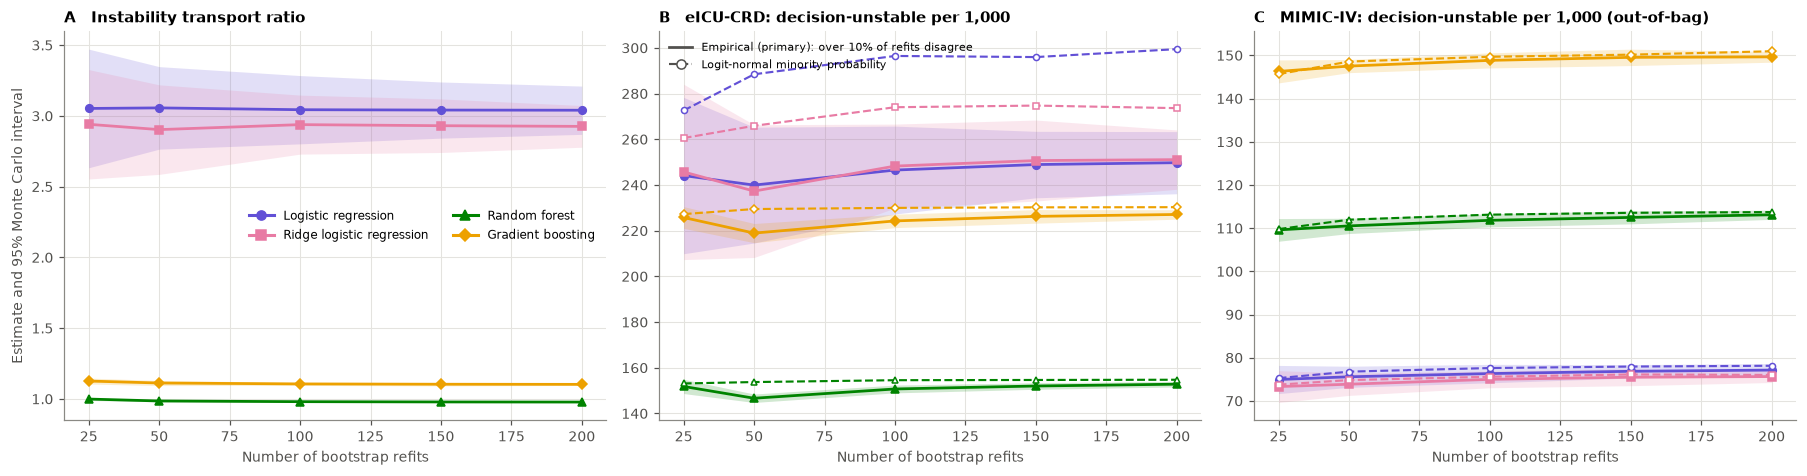

In [39]:
def mc_task(m, B, reps, seed, P, inbag, Pe):
    total = P.shape[0]
    rng = np.random.default_rng(seed)
    min_oob = 5 if (B >= 50 or B >= total) else 2   # all refits: same rule as the primary analysis
    out = []
    for j in range(1 if B >= total else reps):
        pick = np.arange(total) if B >= total else np.sort(rng.choice(total, B, replace=False))
        Pb = P[pick].astype(np.float64)
        w = (~inbag[pick]).astype(np.float64)
        n = w.sum(axis=0)
        ok = n >= min_oob
        mean = (w * Pb).sum(axis=0) / np.maximum(n, 1)
        sd = np.sqrt((w * (Pb - mean) ** 2).sum(axis=0) / np.maximum(n - 1, 1))
        above = (w * (Pb >= T0)).sum(axis=0) / np.maximum(n, 1)
        uns_d = np.minimum(above, 1 - above) > UNSTABLE
        Ld = logit(Pb)
        lm = (w * Ld).sum(axis=0) / np.maximum(n, 1)
        lsd = np.sqrt((w * (Ld - lm) ** 2).sum(axis=0) / np.maximum(n - 1, 1))
        qd = norm.cdf((lm - t0_logit) / np.maximum(lsd, 1e-9))
        smooth_d = np.minimum(qd, 1 - qd) > UNSTABLE
        del Pb, Ld, w
        Pe_b = Pe[pick].astype(np.float32)
        me = Pe_b.mean(axis=0, dtype=np.float64)
        sde = Pe_b.std(axis=0, ddof=1, dtype=np.float64)
        ae = (Pe_b >= T0).mean(axis=0)
        uns_e = np.minimum(ae, 1 - ae) > UNSTABLE
        Le = np.log(np.clip(Pe_b, 1e-4, 1 - 1e-4) / (1 - np.clip(Pe_b, 1e-4, 1 - 1e-4)))
        qe = norm.cdf((Le.mean(axis=0, dtype=np.float64) - t0_logit) / np.maximum(Le.std(axis=0, ddof=1, dtype=np.float64), 1e-9))
        smooth_e = np.minimum(qe, 1 - qe) > UNSTABLE
        del Pe_b, Le
        exp_sd = risk_curve(mean[ok], sd[ok])(me)
        exp_u = np.clip(risk_curve(mean[ok], uns_d[ok].astype(np.float64))(me), 0, 1)
        exp_s = np.clip(risk_curve(mean[ok], smooth_d[ok].astype(np.float64))(me), 0, 1)
        out.append({"model": m, "B": B, "draw": j, "itr": sde.sum() / exp_sd.sum(), "dir": uns_e.sum() / max(exp_u.sum(), 1e-12),
                    "dir_logitnormal": smooth_e.sum() / max(exp_s.sum(), 1e-12),
                    "unstable_per_1000_external": 1000 * float(uns_e.mean()),
                    "unstable_per_1000_development": 1000 * float(uns_d[ok].mean()),
                    "unstable_logitnormal_per_1000_external": 1000 * float(smooth_e.mean()),
                    "unstable_logitnormal_per_1000_development": 1000 * float(smooth_d[ok].mean())})
    return out


MC_METRICS = {"itr": "Instability transport ratio", "dir": "Decision instability ratio",
              "dir_logitnormal": "Decision instability ratio (logit-normal counts)",
              "unstable_per_1000_external": "eICU-CRD decision-unstable per 1,000 (empirical)",
              "unstable_per_1000_development": "MIMIC-IV decision-unstable per 1,000 (empirical, out-of-bag)",
              "unstable_logitnormal_per_1000_external": "eICU-CRD decision-unstable per 1,000 (logit-normal)",
              "unstable_logitnormal_per_1000_development": "MIMIC-IV decision-unstable per 1,000 (logit-normal, out-of-bag)"}

if ADD_RUN["mc"]:
    with timed("Addendum 19: Monte Carlo precision of the audit"):
        tasks = []
        for m in MODELS_LIST:
            res = FULL_RES[m]
            for B in sorted({b for b in ADD["b_grid"] if b < res.n_replicates} | {res.n_replicates}):
                tasks.append(delayed(mc_task)(m, B, ADD["mc_reps"], seed_for("mc", m, B), res.P, INBAG[m], res.P_external))
        MC = pd.DataFrame([r for out in run_parallel(tasks) for r in out])
    a1_rows, a1b_rows = [], []
    for m in MODELS_LIST:
        total = FULL_RES[m].n_replicates
        g = MC[MC["model"] == m]
        b_ref = max(b for b in g["B"].unique() if b <= total / 2) if (g["B"] <= total / 2).any() else None
        for B, gb in g.groupby("B"):
            row = {"model": m, "B": int(B)}
            for k in MC_METRICS:
                if B < total:
                    sd_mc = gb[k].std(ddof=1) * math.sqrt((total - 1) / (total - B))
                else:
                    ref = g[g["B"] == b_ref][k]
                    sd_mc = ref.std(ddof=1) * math.sqrt((total - 1) / (total - b_ref)) * math.sqrt(b_ref / total) if b_ref else np.nan
                row[f"{k}_mean"], row[f"{k}_mc_sd"] = float(gb[k].mean()), float(sd_mc)
                row[f"{k}_lower"], row[f"{k}_upper"] = row[f"{k}_mean"] - 1.96 * sd_mc, row[f"{k}_mean"] + 1.96 * sd_mc
            a1_rows.append(row)
        full_row = [r for r in a1_rows if r["model"] == m and r["B"] == total][0]
        half_row = [r for r in a1_rows if r["model"] == m and r["B"] == b_ref][0] if b_ref else None
        out = {"model": MODEL_LABELS[m], "refits": total}
        for k in MC_METRICS:
            out[f"{k}"] = full_row[f"{k}_mean"]
            out[f"{k}_mc_sd"] = full_row[f"{k}_mc_sd"]
            out[f"{k}_mc_sd_at_1000"] = full_row[f"{k}_mc_sd"] * math.sqrt(total / 1000)
            out[f"{k}_mc_cv_percent"] = 100 * full_row[f"{k}_mc_sd"] / abs(full_row[f"{k}_mean"]) if full_row[f"{k}_mean"] else np.nan
            out[f"{k}_change_from_{b_ref}_refits_percent"] = (100 * (full_row[f"{k}_mean"] - half_row[f"{k}_mean"]) / half_row[f"{k}_mean"]
                                                              if half_row and half_row[f"{k}_mean"] else np.nan)
        a1b_rows.append(out)
    TABLEA1 = pd.DataFrame(a1_rows)
    TABLEA1B = pd.DataFrame(a1b_rows)
    save_table(TABLEA1.assign(model=TABLEA1["model"].map(MODEL_LABELS)).round(5), "tableA1_monte_carlo_by_refits",
               "Addendum: headline estimates and Monte Carlo SD by number of refits (subsets without replacement, finite-population corrected)")
    save_table(TABLEA1B.round(5), "tableA1b_monte_carlo_precision",
               "Addendum: Monte Carlo SD of the reported estimates, projected to 1,000 refits, and drift with the number of refits")
    ADDENDUM["monte_carlo"] = TABLEA1B.to_dict(orient="records")
    show = ["model", "refits"] + [c for k in ("itr", "dir", "dir_logitnormal", "unstable_per_1000_external", "unstable_per_1000_development",
                                              "unstable_logitnormal_per_1000_development")
                                  for c in (k, f"{k}_mc_sd", f"{k}_mc_sd_at_1000") + tuple(c2 for c2 in TABLEA1B.columns
                                                                                          if c2.startswith(f"{k}_change"))]
    display(TABLEA1B[show].round(3))

    fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.4))
    panels = [("itr", None, "Instability transport ratio"),
              ("unstable_per_1000_external", "unstable_logitnormal_per_1000_external", "eICU-CRD: decision-unstable per 1,000"),
              ("unstable_per_1000_development", "unstable_logitnormal_per_1000_development", "MIMIC-IV: decision-unstable per 1,000 (out-of-bag)")]
    for ax, (k, k2, title), letter in zip(axes, panels, "ABC"):
        for m in MODELS_LIST:
            t = TABLEA1[TABLEA1["model"] == m].sort_values("B")
            ax.fill_between(t["B"], t[f"{k}_lower"], t[f"{k}_upper"], color=MODEL_COLORS[m], alpha=0.18, lw=0)
            ax.plot(t["B"], t[f"{k}_mean"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=5, lw=1.8)
            if k2:
                ax.plot(t["B"], t[f"{k2}_mean"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], markersize=4, lw=1.4, ls="--",
                        mfc="white")
        ax.set_xlabel("Number of bootstrap refits")
        ax.set_title(title, fontsize=9.5)
        panel_label(ax, letter)
    axes[0].set_ylabel("Estimate and 95% Monte Carlo interval")
    axes[0].legend(handles=model_handles(MODELS_LIST), fontsize=8, ncol=2)
    axes[1].legend(handles=[Line2D([0], [0], color=INK2, lw=1.8, label="Empirical (primary): over 10% of refits disagree"),
                            Line2D([0], [0], color=INK2, lw=1.4, ls="--", marker="o", mfc="white", label="Logit-normal minority probability")],
                   fontsize=7.5, loc="best")
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA1_monte_carlo", "Addendum: Monte Carlo precision of the audit by number of refits")

## 20. Effective sample size of individual predictions (Figure A2, Table A2)

Thomassen et al. proposed the effective sample size as an interpretable measure of individual sampling uncertainty: the number of hypothetical patients with the same predictor values whose average outcome would vary as much as the patient's predicted risk, n_eff = p(1 - p) / Var(p), computed here from the variance across refits (out-of-bag refits for development patients). It answers a reviewer's question in the language of the most closely related work: **how many comparable development patients effectively stand behind an external patient's prediction?** Low values flag patients whose risk rests on very few comparable development patients.

,model,median_development,median_external,iqr_development,iqr_external,share_below_100_development,share_below_100_external,share_below_30_external,spearman_atypicality_external,median_external_Common in MIMIC-IV (1% or more),median_external_Uncommon (0.1% to 1%),median_external_Rare (under 0.1%),median_external_Never seen in MIMIC-IV
0,Logistic regression,1459.143,201.760,532 to 3909,34 to 1108,0.025,0.405,0.229,-0.455,1116.896,676.910,33.198,30.515
1,Ridge logistic regression,1574.457,225.425,577 to 4117,39 to 1214,0.020,0.391,0.207,-0.467,1211.880,772.820,36.536,35.521
2,Random forest,500.084,443.124,362 to 756,357 to 576,0.000,0.000,0.000,0.100,454.031,437.386,434.464,440.503
3,Gradient boosting,287.875,104.428,73 to 1128,40 to 379,0.307,0.490,0.164,0.002,165.539,170.234,66.081,73.521


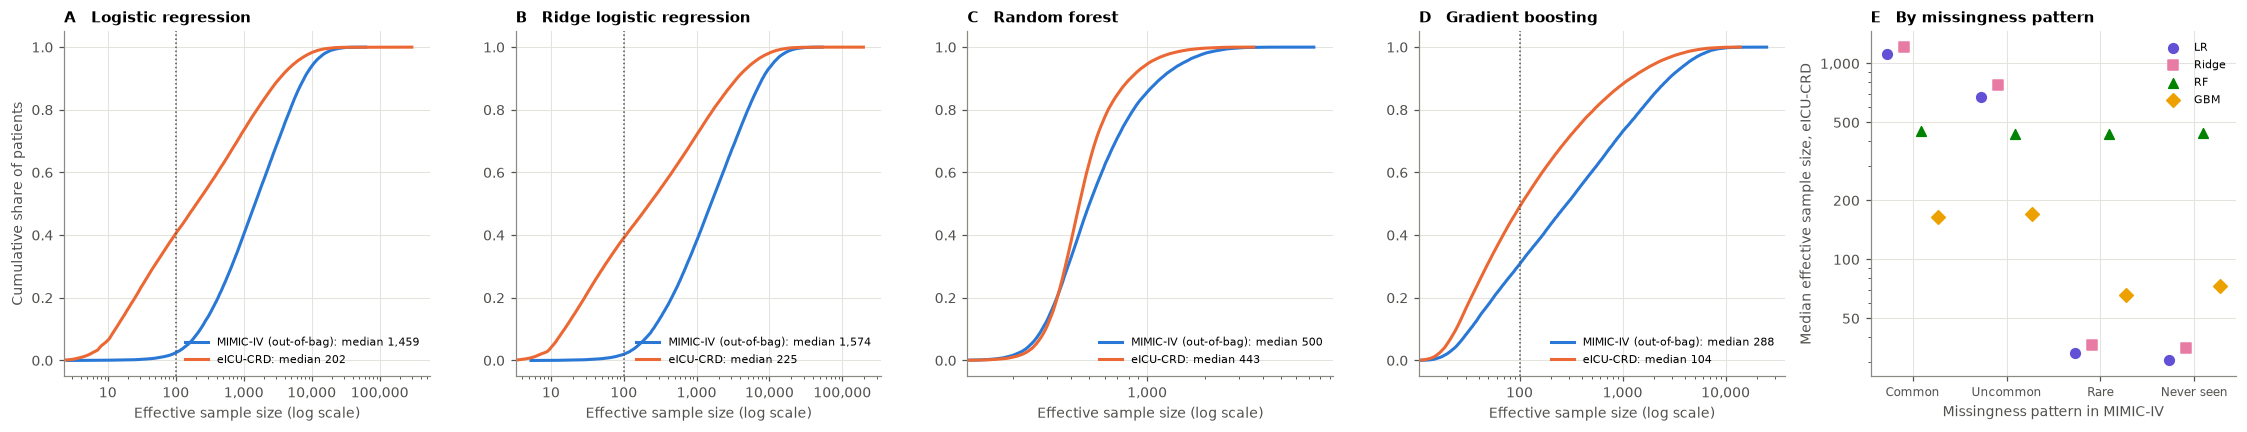

In [40]:
if ADD_RUN["ess"]:
    ess_rows, ESS = [], {}
    for m in MODELS_LIST:
        ok = ITR[m]["dev_ok"]
        e_d = ess_from(DEV_OOB[m]["mean"][ok], DEV_OOB[m]["sd"][ok])
        e_e = ess_from(EXT_S[m]["mean"], EXT_S[m]["sd"])
        ESS[m] = (e_d, e_e)
        row = {"model": MODEL_LABELS[m], "median_development": float(np.median(e_d)), "median_external": float(np.median(e_e)),
               "iqr_development": f"{np.quantile(e_d, 0.25):.0f} to {np.quantile(e_d, 0.75):.0f}",
               "iqr_external": f"{np.quantile(e_e, 0.25):.0f} to {np.quantile(e_e, 0.75):.0f}",
               "share_below_100_development": float(np.mean(e_d < 100)), "share_below_100_external": float(np.mean(e_e < 100)),
               "share_below_30_external": float(np.mean(e_e < 30)),
               "spearman_atypicality_external": spearmanr(ATYP, e_e).correlation}
        for c, lab in enumerate(PATTERN_LABELS):
            sel = PATTERN_CLASS == c
            row[f"median_external_{lab}"] = float(np.median(e_e[sel])) if sel.sum() >= 50 else np.nan
        ess_rows.append(row)
    TABLEA2 = pd.DataFrame(ess_rows)
    save_table(TABLEA2.round(4), "tableA2_effective_sample_size", "Addendum: effective sample size of individual predictions in both populations")
    ADDENDUM["effective_sample_size"] = TABLEA2.to_dict(orient="records")
    display(TABLEA2.round(3))

    fig, axes = plt.subplots(1, len(MODELS_LIST) + 1, figsize=(4 * len(MODELS_LIST) + 4.5, 4))
    for ax, m, letter in zip(axes, MODELS_LIST, "ABCD"):
        for arr, lab, col in ((ESS[m][0], "MIMIC-IV (out-of-bag)", DB_COLORS["MIMIC-IV"]), (ESS[m][1], "eICU-CRD", DB_COLORS["eICU-CRD"])):
            xs = np.sort(arr)
            ax.plot(xs, np.arange(1, xs.size + 1) / xs.size, color=col, lw=2, label=f"{lab}: median {np.median(arr):,.0f}")
        ax.set_xscale("log")
        plain_log_axis(ax.xaxis, subs=(1.0,))
        ax.axvline(100, color=INK2, ls=":", lw=1)
        ax.set_xlim(left=max(1, float(min(np.quantile(ESS[m][0], 0.001), np.quantile(ESS[m][1], 0.001)))))
        ax.set_xlabel("Effective sample size (log scale)")
        ax.set_title(MODEL_LABELS[m])
        ax.legend(fontsize=7.5, loc="lower right")
        panel_label(ax, letter)
    axes[0].set_ylabel("Cumulative share of patients")
    ax = axes[-1]
    off = np.linspace(-0.27, 0.27, len(MODELS_LIST))
    for o, m in zip(off, MODELS_LIST):
        vals = [TABLEA2.loc[TABLEA2["model"] == MODEL_LABELS[m], f"median_external_{lab}"].iloc[0] for lab in PATTERN_LABELS]
        ax.scatter(np.arange(len(PATTERN_LABELS)) + o, vals, color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], s=40, label=MODEL_SHORT[m])
    ax.set_yscale("log")
    plain_log_axis(ax.yaxis)
    ax.set_xticks(range(len(PATTERN_LABELS)))
    ax.set_xticklabels(["Common", "Uncommon", "Rare", "Never seen"], fontsize=8)
    ax.set_xlabel("Missingness pattern in MIMIC-IV")
    ax.set_ylabel("Median effective sample size, eICU-CRD")
    ax.set_title("By missingness pattern")
    ax.legend(fontsize=7.5)
    panel_label(ax, "ABCDE"[len(MODELS_LIST)])
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA2_effective_sample_size", "Addendum: effective sample size of individual predictions")

## 21. Do conclusions depend on the threshold or the disagreement tolerance? (Figure A3, Table A3)

The primary analysis used a threshold of 0.10 and called a decision unstable when more than 10% of refits disagreed with the majority. Here every threshold from 0.05 to 0.50 (steps of 0.01) is combined with tolerances of 5%, 10% and 20%. The external decision-unstable share is also the deferral workload a hospital would face if every unstable decision were sent for review. The decision instability ratio (DIR) is risk-standardised at every threshold, so differences in how many patients sit near a given threshold are removed.


>>> Addendum 21: threshold and tolerance sweep
<<< Addendum 21: threshold and tolerance sweep: 0.1 min


,model,tolerance,min,median,max,share_thresholds_dir_above_1
0,GBM,0.05,1.027,1.065,1.124,1.000
1,GBM,0.10,1.020,1.065,1.114,1.000
2,GBM,0.20,0.972,1.059,1.119,0.783
3,LR,0.05,2.537,2.762,2.840,1.000
4,LR,0.10,2.393,2.793,2.898,1.000
5,LR,0.20,2.185,2.772,3.094,1.000
6,RF,0.05,0.899,0.968,1.240,0.283
7,RF,0.10,0.869,0.966,1.263,0.261
8,RF,0.20,0.858,0.971,1.312,0.283
9,Ridge,0.05,2.383,2.684,2.921,1.000


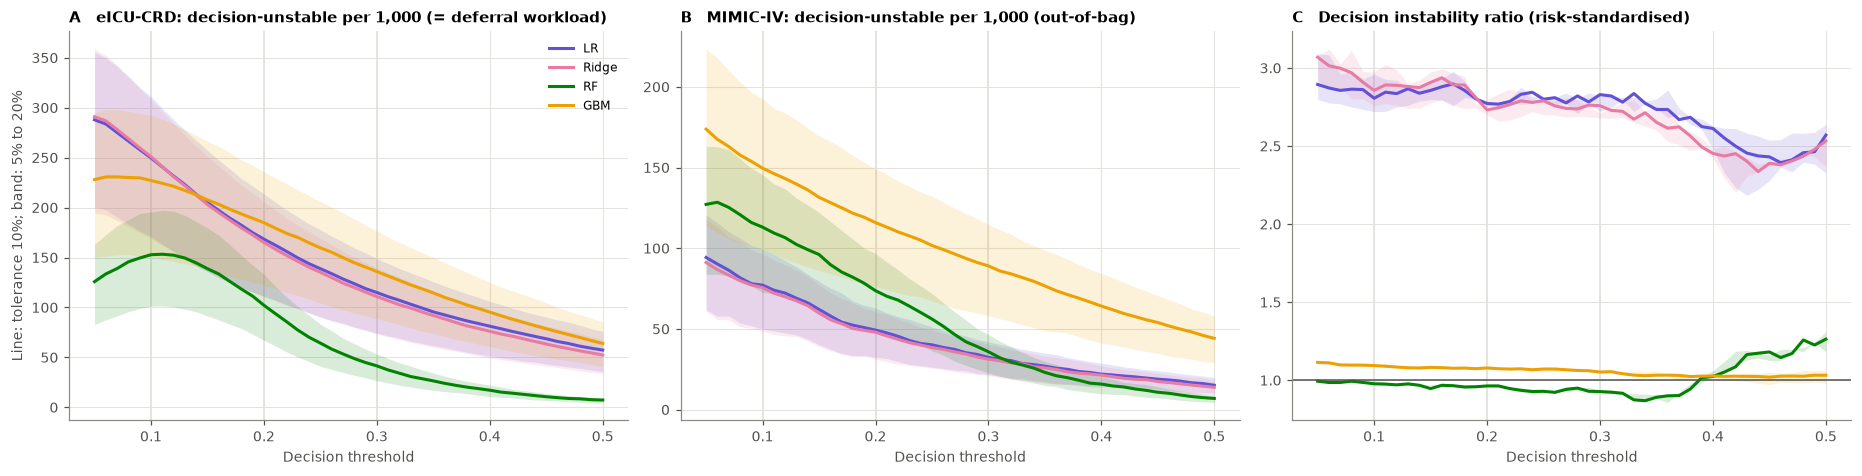

In [41]:
def sweep_task(m, P, inbag, Pe, thresholds, tolerances):
    P = P.astype(np.float64)
    Pe = Pe.astype(np.float64)
    w = (~inbag).astype(np.float64)
    n = w.sum(axis=0)
    ok = n >= 5
    mean = (w * P).sum(axis=0) / np.maximum(n, 1)
    me = Pe.mean(axis=0)
    rows = []
    for t in thresholds:
        a_d = (w * (P >= t)).sum(axis=0) / np.maximum(n, 1)
        a_e = (Pe >= t).mean(axis=0)
        mi_d, mi_e = np.minimum(a_d, 1 - a_d), np.minimum(a_e, 1 - a_e)
        for tol in tolerances:
            u_d, u_e = (mi_d > tol).astype(np.float64), (mi_e > tol).astype(np.float64)
            exp_u = np.clip(risk_curve(mean[ok], u_d[ok])(me), 0, 1)
            rows.append({"model": m, "threshold": float(t), "tolerance": tol, "unstable_per_1000_development": 1000 * float(u_d[ok].mean()),
                         "unstable_per_1000_external": 1000 * float(u_e.mean()), "dir": u_e.sum() / max(exp_u.sum(), 1e-12)})
    return rows


if ADD_RUN["thresholds"]:
    with timed("Addendum 21: threshold and tolerance sweep"):
        outs = run_parallel([delayed(sweep_task)(m, FULL_RES[m].P, INBAG[m], FULL_RES[m].P_external, ADD["threshold_grid"],
                                                 ADD["tolerances"]) for m in MODELS_LIST])
    TABLEA3 = pd.DataFrame([r for o in outs for r in o])
    save_table(TABLEA3.assign(model=TABLEA3["model"].map(MODEL_LABELS)).round(5), "tableA3_threshold_tolerance_sweep",
               "Addendum: decision instability and DIR for every threshold from 0.05 to 0.50 and three tolerances")
    summ = (TABLEA3.groupby(["model", "tolerance"])["dir"].agg(["min", "median", "max"]).reset_index())
    summ["share_thresholds_dir_above_1"] = TABLEA3.groupby(["model", "tolerance"])["dir"].apply(lambda s: float(np.mean(s > 1))).to_numpy()
    ADDENDUM["threshold_sweep"] = summ.assign(model=summ["model"].map(MODEL_LABELS)).to_dict(orient="records")
    display(summ.assign(model=summ["model"].map(MODEL_SHORT)).round(3))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    for ax, col, title, letter in zip(axes, ["unstable_per_1000_external", "unstable_per_1000_development", "dir"],
                                      ["eICU-CRD: decision-unstable per 1,000 (= deferral workload)",
                                       "MIMIC-IV: decision-unstable per 1,000 (out-of-bag)", "Decision instability ratio (risk-standardised)"], "ABC"):
        for m in MODELS_LIST:
            t = TABLEA3[TABLEA3["model"] == m]
            mid = t[t["tolerance"] == 0.10].sort_values("threshold")
            lo = t[t["tolerance"] == max(ADD["tolerances"])].sort_values("threshold")[col].to_numpy()
            hi = t[t["tolerance"] == min(ADD["tolerances"])].sort_values("threshold")[col].to_numpy()
            ax.fill_between(mid["threshold"], np.minimum(lo, hi), np.maximum(lo, hi), color=MODEL_COLORS[m], alpha=0.15, lw=0)
            ax.plot(mid["threshold"], mid[col], color=MODEL_COLORS[m], lw=2, label=MODEL_SHORT[m])
        for t_ in THRESHOLDS:
            ax.axvline(t_, color=GRID, lw=1.2, zorder=0)
        if col == "dir":
            ax.axhline(1, color=INK2, lw=1)
        ax.set_xlabel("Decision threshold")
        ax.set_title(title, fontsize=9.5)
        panel_label(ax, letter)
    axes[0].set_ylabel("Line: tolerance 10%; band: 5% to 20%")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA3_thresholds_tolerances", "Addendum: decision instability across thresholds and tolerances")

## 22. Factorial experiment: model class x missing-data representation x GCS motor score (Figure A4, Table A4)

Section 6 and S7 suggested that missingness indicators learned where a predictor is almost always measured drive instability transport. A reviewer asked whether this is about the representation of missing data or about the model class, since the gradient boosting model handled missing values natively and the others did not. The factorial design separates the two:

| Model class | Native missing values | Imputation only | Imputation + indicators | Without GCS motor |
|---|---|---|---|---|
| Logistic regression | not available | S7 | primary | S4a (indicators); **new** (imputation only) |
| Ridge | not available | S7 | primary | S4a (indicators); **new** (imputation only) |
| Random forest | **new** | S7 | primary | S4a |
| Gradient boosting | primary | **new** | **new** | S4a |

All cells use 100 refits (the primary analysis enters with its first 100), the same development and external data, and are summarised identically. If indicators are the mechanism, adding them should raise instability transport in every model class that can use them, and transport should follow how common a patient's missingness pattern is in MIMIC-IV.


>>> Addendum 22: factorial experiment
   audit rf_native      RF      14.8 min
   audit hgb_imp        GBM      2.1 min
   audit hgb_ind        GBM      2.5 min
   audit lr_imp_nogcs   LR       0.2 min
   audit ridge_imp_nogcs Ridge    1.0 min
<<< Addendum 22: factorial experiment: 21.0 min


,model,representation,gcs_motor,auroc_oob,auroc_external,oe_external,itr,itr_lower,itr_upper,dir,unstable_per_1000_development,unstable_per_1000_external,ess_median_external
0,LR,Imputation + indicators,included,0.851,0.807,0.800,3.165,2.870,3.497,2.834,76.490,247.901,196.404
1,LR,Imputation + indicators,excluded,0.850,0.802,0.660,1.975,1.736,2.247,1.847,76.090,163.376,468.697
2,LR,Imputation only,included,0.820,0.820,0.989,1.135,1.122,1.149,1.176,82.495,81.306,1367.899
3,Ridge,Imputation + indicators,included,0.853,0.808,0.806,2.863,2.589,3.137,2.895,75.089,252.088,232.581
4,Ridge,Imputation + indicators,excluded,0.850,0.802,0.662,1.823,1.642,2.042,1.741,75.239,153.080,494.398
5,Ridge,Imputation only,included,0.822,0.821,0.978,1.147,1.133,1.162,1.169,82.920,81.763,1402.236
6,RF,Imputation + indicators,included,0.872,0.835,0.783,0.981,0.977,0.985,0.977,111.795,150.817,445.172
7,RF,Imputation + indicators,excluded,0.869,0.827,0.720,0.991,0.988,0.994,1.005,112.921,147.491,412.735
8,RF,Imputation only,included,0.865,0.839,0.863,0.995,0.993,0.998,0.982,123.730,142.062,419.994
9,GBM,Native missing values,included,0.879,0.839,0.750,1.103,1.091,1.116,1.087,149.052,224.727,106.264


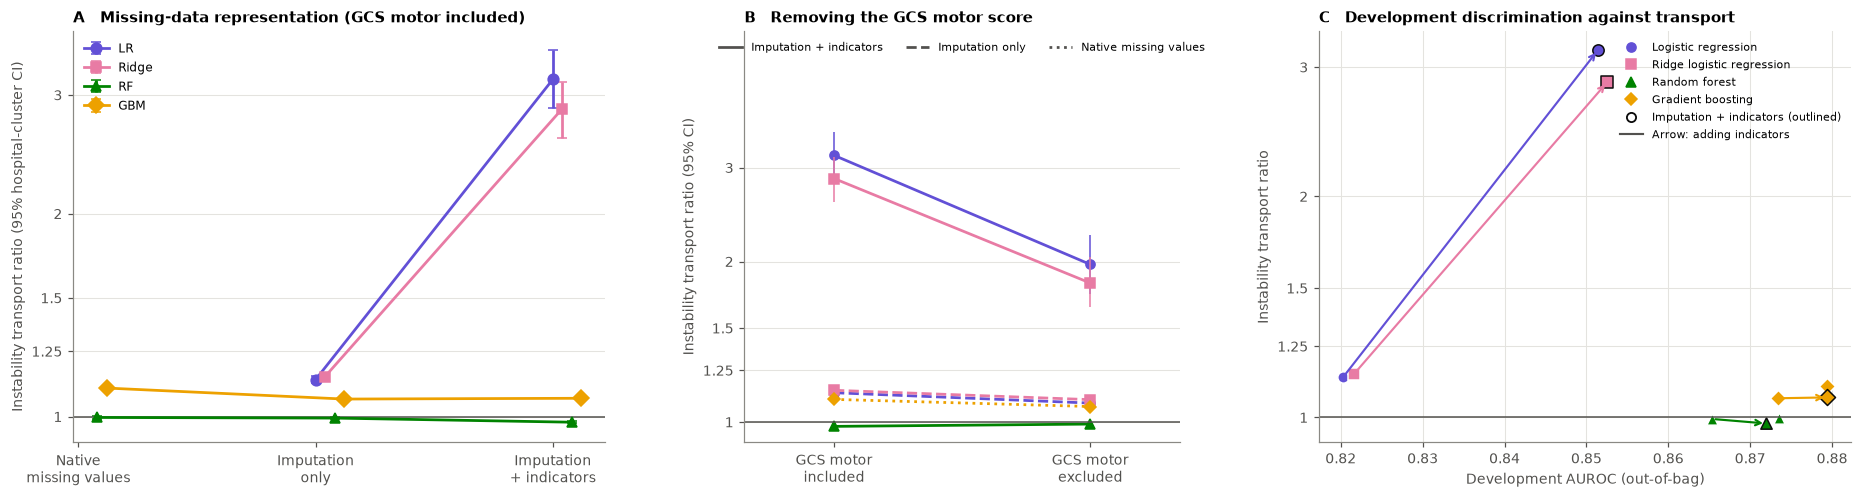

In [42]:
if ADD_RUN["factorial"]:
    keep_nogcs = [c for c in PRED if c != "gcs_motor_min"]
    X_dev_ng, X_ext_ng = dev[keep_nogcs].to_numpy(np.float64), ext[keep_nogcs].to_numpy(np.float64)
    FACT_SPEC = []   # (model, representation, gcs, loader)
    for m in MODELS_LIST:
        prim_rep = "native" if m == "hgb" else "ind"
        FACT_SPEC.append((m, prim_rep, "included", lambda m=m: primary_subset(m)))
        FACT_SPEC.append((m, prim_rep, "excluded", lambda m=m: sens_arrays("S4a", m)))
        if m in ("lr", "ridge", "rf"):
            FACT_SPEC.append((m, "imp", "included", lambda m=m: sens_arrays("S7", m)))
    if "rf" in MODELS_LIST and SK_VERSION >= (1, 4):
        FACT_SPEC.append(("rf", "native", "included", lambda: addon_audit(
            "rf_native", "rf", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=1),
            X_dev, y_dev, X_ext, y_ext)))
    if "hgb" in MODELS_LIST:
        FACT_SPEC.append(("hgb", "imp", "included", lambda: addon_audit(
            "hgb_imp", "hgb", Pipeline([("prep", GroupedImputer(None, scale=False)), ("model", hgb_estimator())]),
            X_dev, y_dev, X_ext, y_ext)))
        FACT_SPEC.append(("hgb", "ind", "included", lambda: addon_audit(
            "hgb_ind", "hgb", Pipeline([("prep", GroupedImputer(GROUP_INDEX, scale=False)), ("model", hgb_estimator())]),
            X_dev, y_dev, X_ext, y_ext)))
    for m in [m for m in ("lr", "ridge") if m in MODELS_LIST]:
        FACT_SPEC.append((m, "imp", "excluded", lambda m=m: addon_audit(f"{m}_imp_nogcs", m, make_estimator(m, None),
                                                                        X_dev_ng, y_dev, X_ext_ng, y_ext)))
    fact_rows, fact_pat = [], []
    with timed("Addendum 22: factorial experiment"):
        for m, rep, gcs, loader in FACT_SPEC:
            arrs = loader()
            if arrs is None:
                print(f"   skipped {m} / {rep} / GCS {gcs}: sensitivity file not found (was the model in STUDY_P3_SENS_MODELS?)")
                continue
            row, prow = transport_summary(f"{rep}|{gcs}", m, arrs["yd"], arrs["P"], arrs["inbag"], arrs["ye"], arrs["pe"], arrs["Pe"],
                                          MISS_DEV, MISS_EXT, ci="hospitals", seed_key=("fact", m, rep, gcs))
            row.update({"representation": REP_LABELS[rep], "gcs_motor": gcs})
            fact_rows.append(row)
            fact_pat += [dict(r, representation=REP_LABELS[rep], gcs_motor=gcs) for r in prow]
    TABLEA4 = pd.DataFrame(fact_rows)
    TABLEA4P = pd.DataFrame(fact_pat)
    save_table(TABLEA4.assign(model=TABLEA4["model"].map(MODEL_LABELS)).drop(columns="analysis").round(5), "tableA4_factorial_missingness",
               "Addendum: model class x missing-data representation x GCS motor score")
    save_table(TABLEA4P.assign(model=TABLEA4P["model"].map(MODEL_LABELS)).drop(columns="analysis").round(5),
               "tableA4b_factorial_by_pattern", "Addendum: factorial cells, instability transport by missingness pattern")
    show_cols = ["model", "representation", "gcs_motor", "auroc_oob", "auroc_external", "oe_external", "itr", "itr_lower", "itr_upper",
                 "dir", "unstable_per_1000_development", "unstable_per_1000_external", "ess_median_external"]
    display(TABLEA4[show_cols].assign(model=TABLEA4["model"].map(MODEL_SHORT)).round(3))
    ADDENDUM["factorial"] = TABLEA4[show_cols].to_dict(orient="records")

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.1, 0.9, 1.1]})
    ax = axes[0]
    reps_order = ["Native missing values", "Imputation only", "Imputation + indicators"]
    for m in MODELS_LIST:
        t = TABLEA4[(TABLEA4["model"] == m) & (TABLEA4["gcs_motor"] == "included")].set_index("representation")
        xs = [i for i, r in enumerate(reps_order) if r in t.index]
        ys = [t.loc[reps_order[i], "itr"] for i in xs]
        lo = [t.loc[reps_order[i], "itr_lower"] for i in xs]
        hi = [t.loc[reps_order[i], "itr_upper"] for i in xs]
        ax.errorbar(np.array(xs) + 0.04 * MODELS_LIST.index(m), ys, yerr=[np.array(ys) - lo, np.array(hi) - ys], color=MODEL_COLORS[m],
                    marker=MODEL_MARKERS[m], markersize=7, lw=1.8, capsize=3, label=MODEL_SHORT[m])
    ax.axhline(1, color=INK2, lw=1)
    ratio_axis(ax, "y", min(TABLEA4["itr_lower"].min(), 0.95), max(TABLEA4["itr_upper"].max(), 1.05))
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Native\nmissing values", "Imputation\nonly", "Imputation\n+ indicators"])
    ax.set_ylabel("Instability transport ratio (95% hospital-cluster CI)")
    ax.set_title("Missing-data representation (GCS motor included)")
    ax.legend(fontsize=8)
    ax.grid(axis="x", visible=False)
    panel_label(ax, "A")

    ax = axes[1]
    rep_ls = {"Imputation + indicators": "-", "Imputation only": "--", "Native missing values": ":"}
    for m in MODELS_LIST:
        t = TABLEA4[TABLEA4["model"] == m]
        for r_, g in t.groupby("representation"):
            g = g.set_index("gcs_motor").reindex(["included", "excluded"])
            if g["itr"].notna().all():
                ax.plot([0, 1], g["itr"], color=MODEL_COLORS[m], ls=rep_ls[r_], marker=MODEL_MARKERS[m], markersize=6, lw=1.8)
                ax.vlines([0, 1], g["itr_lower"], g["itr_upper"], color=MODEL_COLORS[m], lw=1)
    ax.axhline(1, color=INK2, lw=1)
    ratio_axis(ax, "y", min(TABLEA4["itr_lower"].min(), 0.95), max(TABLEA4["itr_upper"].max(), 1.05))
    lo_b, hi_b = ax.get_ylim()
    ax.set_ylim(lo_b, hi_b * (1.45 if ax.get_yscale() == "log" else 1.0) + (0 if ax.get_yscale() == "log" else 0.18 * (hi_b - lo_b)))
    ax.set_xlim(-0.35, 1.35)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["GCS motor\nincluded", "GCS motor\nexcluded"])
    ax.set_ylabel("Instability transport ratio (95% CI)")
    ax.set_title("Removing the GCS motor score")
    ax.legend(handles=[Line2D([0], [0], color=INK2, ls=s, lw=1.8, label=r_) for r_, s in rep_ls.items()
                       if (TABLEA4["representation"] == r_).any()], fontsize=7.5, loc="upper center", ncol=3, frameon=False)
    ax.grid(axis="x", visible=False)
    panel_label(ax, "B")

    ax = axes[2]
    for m in MODELS_LIST:
        t = TABLEA4[(TABLEA4["model"] == m) & (TABLEA4["gcs_motor"] == "included")].set_index("representation")
        for r in t.index:
            ax.scatter(t.loc[r, "auroc_oob"], t.loc[r, "itr"], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m], s=55,
                       edgecolors=INK if r == "Imputation + indicators" else "white", linewidths=1)
        if {"Imputation only", "Imputation + indicators"} <= set(t.index):
            a, b = t.loc["Imputation only"], t.loc["Imputation + indicators"]
            ax.annotate("", xy=(b["auroc_oob"], b["itr"]), xytext=(a["auroc_oob"], a["itr"]),
                        arrowprops=dict(arrowstyle="->", color=MODEL_COLORS[m], lw=1.4))
    ax.axhline(1, color=INK2, lw=1)
    ratio_axis(ax, "y", min(TABLEA4["itr"].min(), 0.95), max(TABLEA4["itr"].max(), 1.05))
    ax.set_xlabel("Development AUROC (out-of-bag)")
    ax.set_ylabel("Instability transport ratio")
    ax.set_title("Development discrimination against transport")
    ax.legend(handles=model_handles(MODELS_LIST, line=False)
              + [Line2D([0], [0], marker="o", lw=0, mfc="white", mec=INK, mew=1.2, label="Imputation + indicators (outlined)"),
                 Line2D([0], [0], color=INK2, lw=1.4, marker=">", markersize=0, label="Arrow: adding indicators")], fontsize=7.5, loc="best")
    panel_label(ax, "C")
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA4_factorial", "Addendum: factorial experiment on missing-data representation")

## 23. Transport in three directions (Figure A5, Table A5)

The main analysis moved models from one academic centre (MIMIC-IV) to a multi-hospital network (eICU-CRD). Two further directions test whether the findings are specific to that direction:

* **Reverse:** develop in eICU-CRD (94,114 patients, 205 hospitals), evaluate in MIMIC-IV.
* **Temporal:** develop in MIMIC-IV patients from the earlier anchor-year groups, evaluate in the latest group (same hospital, later years).

The models, refits (100) and summaries are identical to the forward direction (the forward row uses the first 100 primary refits). External intervals: hospital-cluster bootstrap for eICU-CRD, patient bootstrap for MIMIC-IV.

**Hypotheses, written down before these analyses were run.** If instability transport is driven by missingness patterns that are rare in development but common in deployment:

* **H1 (reverse).** The ratio for logistic and ridge regression will be clearly smaller than in the forward direction (upper 95% limit below the forward lower limit), because the measurement patterns of MIMIC-IV patients are common in eICU-CRD.
* **H2 (temporal).** The ratio will lie between 0.8 and 1.25 for all model classes, because measurement practice within one hospital changes less than between hospitals.
* **H3 (all directions).** For logistic and ridge regression, the ratio will be higher for patients whose missingness pattern is rare or never seen in the development data than for patients with common patterns.

The verdicts are computed automatically below and reported whatever they are.


>>> Addendum 23: transport in three directions
   audit reverse        LR       0.6 min
   audit temporal       LR       0.2 min
   audit reverse        Ridge    2.7 min
   audit temporal       Ridge    1.1 min
   audit reverse        RF      34.7 min
   audit temporal       RF       8.4 min
   audit reverse        GBM      3.6 min
   audit temporal       GBM      1.4 min
<<< Addendum 23: transport in three directions: 53.1 min


,analysis,model,n_development,n_external,auroc_external,oe_external,itr,itr_lower,itr_upper,dir,unstable_per_1000_development,unstable_per_1000_external,ess_median_external
0,Forward: MIMIC-IV to eICU-CRD,LR,39966,94114,0.807,0.800,3.165,2.830,3.499,2.834,76.490,247.901,196.404
1,Reverse: eICU-CRD to MIMIC-IV,LR,94114,39966,0.825,1.344,1.046,1.040,1.052,1.050,58.217,53.245,3155.502
2,Temporal: MIMIC-IV earlier to 2017 - 2019,LR,31353,8613,0.874,0.879,0.996,0.982,1.011,1.004,88.604,83.595,1050.394
3,Forward: MIMIC-IV to eICU-CRD,Ridge,39966,94114,0.808,0.806,2.863,2.608,3.146,2.895,75.089,252.088,232.581
4,Reverse: eICU-CRD to MIMIC-IV,Ridge,94114,39966,0.825,1.337,1.059,1.053,1.066,1.059,56.368,52.169,3461.983
5,Temporal: MIMIC-IV earlier to 2017 - 2019,Ridge,31353,8613,0.874,0.887,1.006,0.993,1.019,0.991,86.531,79.415,1154.078
6,Forward: MIMIC-IV to eICU-CRD,RF,39966,94114,0.835,0.783,0.981,0.977,0.985,0.977,111.795,150.817,445.172
7,Reverse: eICU-CRD to MIMIC-IV,RF,94114,39966,0.855,1.120,0.972,0.971,0.974,0.953,107.944,118.050,655.997
8,Temporal: MIMIC-IV earlier to 2017 - 2019,RF,31353,8613,0.894,1.049,1.007,1.004,1.011,0.991,123.401,103.448,483.509
9,Forward: MIMIC-IV to eICU-CRD,GBM,39966,94114,0.839,0.750,1.103,1.091,1.116,1.087,149.052,224.727,106.264


,hypothesis,model,supported,evidence
0,H1 reverse smaller than forward,Logistic regression,True,reverse 1.05 (1.04 to 1.05); forward 3.16 (2.8...
1,H1 reverse smaller than forward,Ridge logistic regression,True,reverse 1.06 (1.05 to 1.07); forward 2.86 (2.6...
2,H2 temporal ratio within 0.8 to 1.25,Logistic regression,True,1.00 (0.98 to 1.01)
3,H2 temporal ratio within 0.8 to 1.25,Ridge logistic regression,True,1.01 (0.99 to 1.02)
4,H2 temporal ratio within 0.8 to 1.25,Random forest,True,1.01 (1.00 to 1.01)
5,H2 temporal ratio within 0.8 to 1.25,Gradient boosting,True,1.01 (1.00 to 1.02)
6,H3 rare or unseen patterns above common,Logistic regression (Forward: MIMIC-IV to eICU...,True,"common 1.09; rare or unseen 4.53, 5.25"
7,H3 rare or unseen patterns above common,Ridge logistic regression (Forward: MIMIC-IV t...,True,"common 1.08; rare or unseen 4.04, 4.59"
8,H3 rare or unseen patterns above common,Logistic regression (Reverse: eICU-CRD to MIMI...,True,"common 0.95; rare or unseen 1.20, 1.73"
9,H3 rare or unseen patterns above common,Ridge logistic regression (Reverse: eICU-CRD t...,True,"common 0.95; rare or unseen 1.25, 1.78"


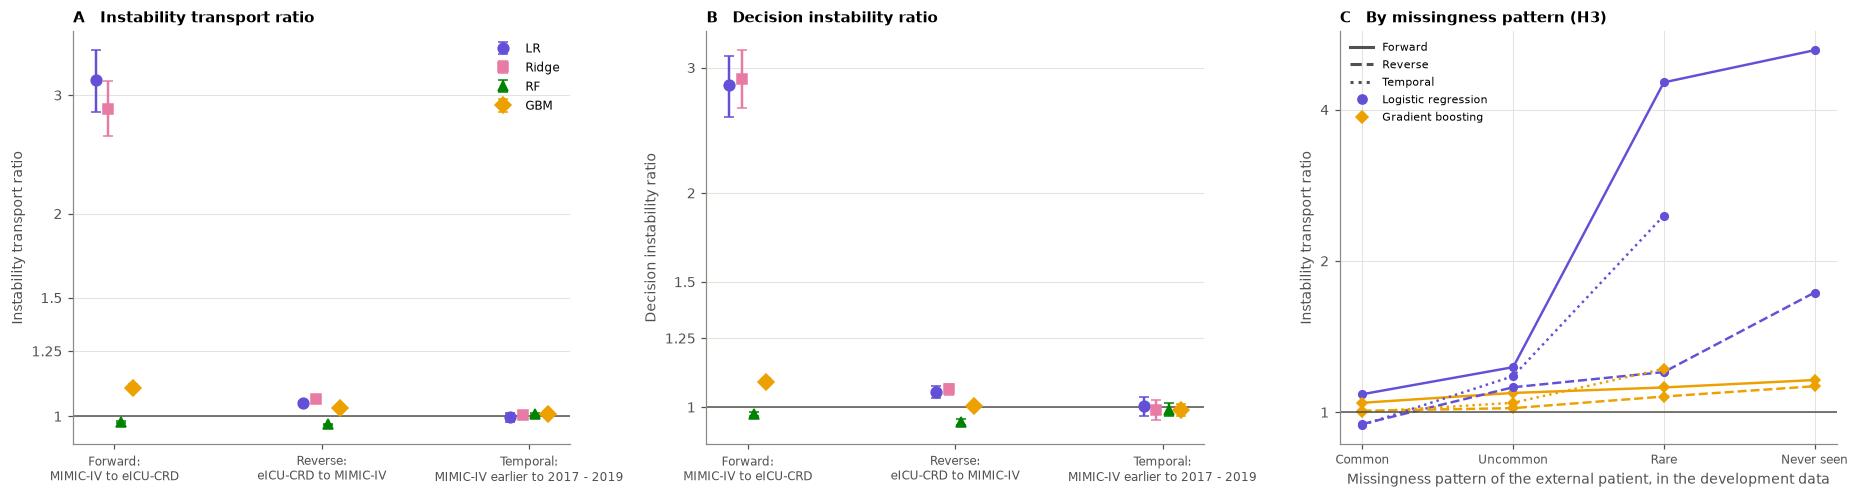

In [43]:
if ADD_RUN["transport"]:
    tr_rows, tr_pat = [], []
    groups_latest = sorted(dev["year_group"].dropna().astype(str).unique()) if "year_group" in dev else []
    latest = groups_latest[-1] if len(groups_latest) >= 2 else None
    with timed("Addendum 23: transport in three directions"):
        for m in ADD_TRANSPORT_MODELS:
            a = primary_subset(m)
            row, prow = transport_summary("Forward: MIMIC-IV to eICU-CRD", m, a["yd"], a["P"], a["inbag"], a["ye"], a["pe"], a["Pe"],
                                          MISS_DEV, MISS_EXT, ci="hospitals", seed_key=("dir-fwd", m))
            tr_rows.append(row)
            tr_pat += prow
            a = addon_audit("reverse", m, make_estimator(m, GROUP_INDEX), X_ext, y_ext, X_dev, y_dev)
            row, prow = transport_summary("Reverse: eICU-CRD to MIMIC-IV", m, a["yd"], a["P"], a["inbag"], a["ye"], a["pe"], a["Pe"],
                                          MISS_EXT, MISS_DEV, ci="patients", seed_key=("dir-rev", m))
            tr_rows.append(row)
            tr_pat += prow
            if latest is not None:
                late = (dev["year_group"].astype(str) == latest).to_numpy()
                a = addon_audit("temporal", m, make_estimator(m, GROUP_INDEX), X_dev[~late], y_dev[~late], X_dev[late], y_dev[late])
                row, prow = transport_summary(f"Temporal: MIMIC-IV earlier to {latest}", m, a["yd"], a["P"], a["inbag"], a["ye"], a["pe"],
                                              a["Pe"], MISS_DEV[~late], MISS_DEV[late], ci="patients", seed_key=("dir-tmp", m))
                tr_rows.append(row)
                tr_pat += prow
    TABLEA5 = pd.DataFrame(tr_rows)
    TABLEA5P = pd.DataFrame(tr_pat)
    save_table(TABLEA5.assign(model=TABLEA5["model"].map(MODEL_LABELS)).round(5), "tableA5_transport_directions",
               "Addendum: instability transport forward, reverse and over time")
    save_table(TABLEA5P.assign(model=TABLEA5P["model"].map(MODEL_LABELS)).round(5), "tableA5b_transport_directions_by_pattern",
               "Addendum: instability transport by missingness pattern in each direction")
    display(TABLEA5[["analysis", "model", "n_development", "n_external", "auroc_external", "oe_external", "itr", "itr_lower", "itr_upper",
                     "dir", "unstable_per_1000_development", "unstable_per_1000_external", "ess_median_external"]]
            .assign(model=TABLEA5["model"].map(MODEL_SHORT)).round(3))

    verdicts = []
    fwd = TABLEA5[TABLEA5["analysis"].str.startswith("Forward")].set_index("model")
    rev = TABLEA5[TABLEA5["analysis"].str.startswith("Reverse")].set_index("model")
    tmp = TABLEA5[TABLEA5["analysis"].str.startswith("Temporal")].set_index("model")
    for m in [m for m in ("lr", "ridge") if m in rev.index]:
        ok = bool(rev.loc[m, "itr_upper"] < fwd.loc[m, "itr_lower"])
        verdicts.append({"hypothesis": "H1 reverse smaller than forward", "model": MODEL_LABELS[m], "supported": ok,
                         "evidence": f"reverse {rev.loc[m, 'itr']:.2f} ({rev.loc[m, 'itr_lower']:.2f} to {rev.loc[m, 'itr_upper']:.2f}); "
                                     f"forward {fwd.loc[m, 'itr']:.2f} ({fwd.loc[m, 'itr_lower']:.2f} to {fwd.loc[m, 'itr_upper']:.2f})"})
    for m in tmp.index:
        ok = bool(0.8 <= tmp.loc[m, "itr"] <= 1.25)
        verdicts.append({"hypothesis": "H2 temporal ratio within 0.8 to 1.25", "model": MODEL_LABELS[m], "supported": ok,
                         "evidence": f"{tmp.loc[m, 'itr']:.2f} ({tmp.loc[m, 'itr_lower']:.2f} to {tmp.loc[m, 'itr_upper']:.2f})"})
    for (direction, m), t in TABLEA5P.groupby(["analysis", "model"]):
        if m not in ("lr", "ridge"):
            continue
        t = t.set_index("pattern")
        common = t["itr"].get(PATTERN_LABELS[0], np.nan)
        rare = t.loc[[p for p in PATTERN_LABELS[2:] if p in t.index], "itr"]
        if np.isfinite(common) and len(rare):
            verdicts.append({"hypothesis": "H3 rare or unseen patterns above common", "model": f"{MODEL_LABELS[m]} ({direction})",
                             "supported": bool((rare > common).all()),
                             "evidence": f"common {common:.2f}; rare or unseen {', '.join(f'{v:.2f}' for v in rare)}"})
        else:
            verdicts.append({"hypothesis": "H3 rare or unseen patterns above common", "model": f"{MODEL_LABELS[m]} ({direction})",
                             "supported": None, "evidence": "fewer than 50 patients with rare or unseen patterns"})
    VERDICTS = pd.DataFrame(verdicts)
    save_table(VERDICTS, "tableA5c_hypothesis_verdicts", "Addendum: pre-stated hypotheses H1 to H3 and their verdicts")
    ADDENDUM["transport_directions"] = TABLEA5.drop(columns=[]).to_dict(orient="records")
    ADDENDUM["hypotheses"] = VERDICTS.to_dict(orient="records")
    display(VERDICTS)

    directions = list(dict.fromkeys(TABLEA5["analysis"]))
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    for k, (col, lo, hi, title) in enumerate([("itr", "itr_lower", "itr_upper", "Instability transport ratio"),
                                              ("dir", "dir_lower", "dir_upper", "Decision instability ratio")]):
        ax = axes[k]
        for m in ADD_TRANSPORT_MODELS:
            t = TABLEA5[TABLEA5["model"] == m].set_index("analysis").reindex(directions)
            xs = np.arange(len(directions)) + 0.06 * (ADD_TRANSPORT_MODELS.index(m) - 1.5)
            ax.errorbar(xs, t[col], yerr=[t[col] - t[lo], t[hi] - t[col]], color=MODEL_COLORS[m], marker=MODEL_MARKERS[m],
                        markersize=7, lw=0, elinewidth=1.6, capsize=3, label=MODEL_SHORT[m])
        ax.axhline(1, color=INK2, lw=1)
        ratio_axis(ax, "y", min(TABLEA5[lo].min(), 0.95), max(TABLEA5[hi].max(), 1.05))
        ax.set_xticks(range(len(directions)))
        ax.set_xticklabels([d.replace(": ", ":\n") for d in directions], fontsize=8)
        ax.set_ylabel(title)
        ax.set_title(title)
        ax.grid(axis="x", visible=False)
        panel_label(ax, "AB"[k])
    axes[0].legend(fontsize=8)
    ax = axes[2]
    ls = dict(zip(directions, ["-", "--", ":"]))
    for d in directions:
        for m in [m for m in ("lr", "hgb") if m in ADD_TRANSPORT_MODELS]:
            t = TABLEA5P[(TABLEA5P["analysis"] == d) & (TABLEA5P["model"] == m)].set_index("pattern").reindex(PATTERN_LABELS)
            xs_ok = np.flatnonzero(t["itr"].notna().to_numpy())
            ax.plot(xs_ok, t["itr"].to_numpy()[xs_ok], color=MODEL_COLORS[m], ls=ls[d], marker=MODEL_MARKERS[m], markersize=5, lw=1.6)
    ax.axhline(1, color=INK2, lw=1)
    if len(TABLEA5P):
        ratio_axis(ax, "y", min(TABLEA5P["itr"].min(), 0.95), max(TABLEA5P["itr"].max(), 1.05))
    ax.set_xticks(range(len(PATTERN_LABELS)))
    ax.set_xticklabels(["Common", "Uncommon", "Rare", "Never seen"], fontsize=8)
    ax.set_xlabel("Missingness pattern of the external patient, in the development data")
    ax.set_ylabel("Instability transport ratio")
    ax.set_title("By missingness pattern (H3)")
    ax.legend(handles=[Line2D([0], [0], color=INK2, ls=ls[d], label=d.split(":")[0]) for d in directions]
              + model_handles([m for m in ("lr", "hgb") if m in ADD_TRANSPORT_MODELS], line=False), fontsize=7.5)
    panel_label(ax, "C")
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA5_transport_directions", "Addendum: instability transport forward, reverse and over time")

## 24. Extended ground truth: 200 independent samples, 20 audited samples (Figure A6, Table A6)

Notebook 2 estimated true instability from 30 independent development samples per size and checked the bootstrap in 5 of them. For the heavy-tailed regression models in eICU-CRD this left visible Monte Carlo noise (sizes 3,906 and 4,000 disagreed). The experiment is repeated with fresh random streams at the analytic minimum size for every model class (200 independent samples, 20 of them audited with 100 refits each, exactly as notebook 2), and additionally at the largest size for logistic regression. Reported for each audited sample: the bootstrap-to-truth ratio of the instability index in both populations, the true and estimated instability transport ratio, flag sensitivity and positive predictive value, and the deferral comparison at the bootstrap flag rate and at 20% deferred. The original 30-sample estimates are shown alongside, so the effect of the larger experiment is visible.


>>> Addendum 24: extended ground truth
   LR     n = 3,906: 1.3 min
   Ridge  n = 3,906: 6.3 min
   RF     n = 3,906: 19.5 min
   GBM    n = 3,906: 18.0 min
   LR     n = 16,000: 4.0 min
<<< Addendum 24: extended ground truth: 49.1 min


,model,n,truth_eicu_instability_index,truth_eicu_ii_mc_lower,truth_eicu_ii_mc_upper,true_itr,boot_itr,ratio_eicu,ratio_eicu_p10,ratio_eicu_p90,ratio_audit,sensitivity_eicu,ppv_eicu,capture_bootstrap_20,capture_distance_20,share_samples_bootstrap_beats_distance_20
0,LR,3906,0.112,0.097,0.126,3.002,2.082,0.487,0.265,1.050,0.985,0.514,0.846,0.314,0.260,1.0
1,Ridge,3906,0.081,0.072,0.089,2.830,1.950,0.665,0.363,1.134,1.049,0.616,0.868,0.348,0.315,1.0
2,RF,3906,0.018,0.018,0.018,0.974,0.979,1.026,0.986,1.079,1.020,0.717,0.804,0.554,0.532,1.0
3,GBM,3906,0.052,0.051,0.053,1.035,1.023,0.923,0.797,1.068,0.946,0.618,0.865,0.445,0.407,1.0
4,LR,16000,0.053,0.049,0.056,3.361,3.007,0.849,0.677,1.048,0.989,0.699,0.930,0.437,0.361,1.0


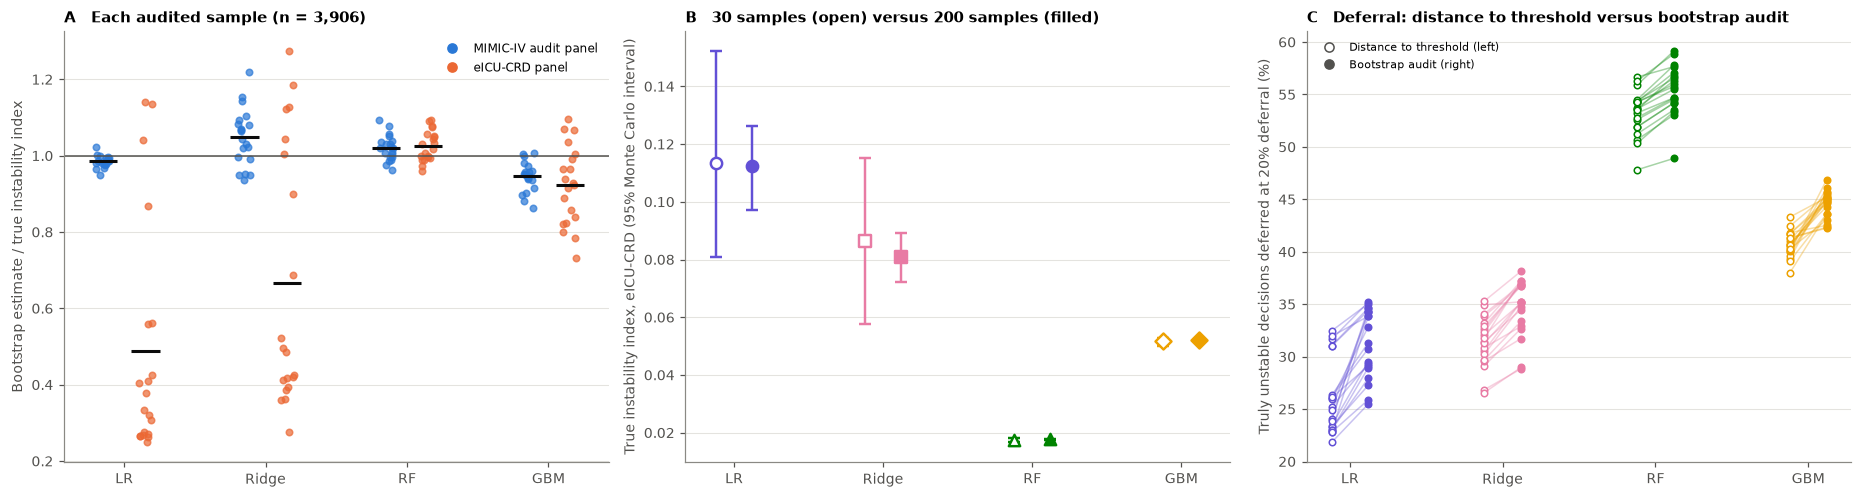

In [44]:
def gt_truth_task(builder, samples, seeds, X, y, Xa, Xp):
    out_a, out_p = [], []
    for idx, s in zip(samples, seeds):
        model, _ = fit_quietly(builder, X[idx], y[idx], random_state=s % (2**31 - 1))
        out_a.append(builder.predict_risk(model, Xa).astype(np.float32))
        out_p.append(builder.predict_risk(model, Xp).astype(np.float32))
    return np.vstack(out_a), np.vstack(out_p)


def gt_boot_task(builder, dev_idx, seeds, X, y, Xa, Xp):
    Xd, yd = X[dev_idx], y[dev_idx]
    n = dev_idx.size
    Pa, Pp = np.empty((len(seeds), Xa.shape[0]), np.float32), np.empty((len(seeds), Xp.shape[0]), np.float32)
    for j, s in enumerate(seeds):
        rng = np.random.default_rng(s)
        for _ in range(50):
            b = rng.integers(0, n, n)
            if 0 < yd[b].sum() < n:
                break
        model, _ = fit_quietly(builder, Xd[b], yd[b], random_state=s % (2**31 - 1))
        Pa[j], Pp[j] = builder.predict_risk(model, Xa), builder.predict_risk(model, Xp)
    return Pa, Pp


def gt_samples(n, K, seed):
    rng = np.random.default_rng(seed)
    if K * n <= POOL.size:
        perm = rng.permutation(POOL)
        return [np.sort(perm[k * n:(k + 1) * n]) for k in range(K)], 0.0
    return [np.sort(rng.choice(POOL, size=n, replace=False)) for _ in range(K)], n / POOL.size


def truth_mc_centred(T, f, n_boot, seed):
    """Monte Carlo 95% interval of the true instability index and unstable share, centred on the estimate.

    Resampling development samples with replacement duplicates some of them, which shrinks their spread; the bootstrap
    distribution is therefore shifted so that its median equals the full-sample estimate (bias-corrected percentile).
    """
    T = np.asarray(T, dtype=np.float64)
    s = truth_summary(T, f)
    ii_hat = float(np.mean(s["mape"]))
    us_hat = float(np.mean(s[f"minority@{T0:g}"] > UNSTABLE))
    rng = np.random.default_rng(seed)
    K = T.shape[0]
    c = 1.0 / math.sqrt(1.0 - f)
    L = logit(T)
    ii, us = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        pick = rng.integers(0, K, K)
        Tb, Lb = T[pick], L[pick]
        ii[b] = np.mean(np.abs(Tb - Tb.mean(axis=0)).mean(axis=0)) * math.sqrt(K / (K - 1)) * c
        q = norm.cdf((Lb.mean(axis=0) - t0_logit) / np.maximum(Lb.std(axis=0, ddof=1) * c, 1e-9))
        us[b] = np.mean(np.minimum(q, 1 - q) > UNSTABLE)
    ii_ci = ii_hat + np.quantile(ii, [0.025, 0.975]) - np.median(ii)
    us_ci = np.clip(us_hat + np.quantile(us, [0.025, 0.975]) - np.median(us), 0, 1)
    return ii_hat, ii_ci, us_hat, us_ci


def keep_summary(s):
    return {k: np.asarray(s[k], dtype=np.float32) for k in ("mean", "sd", "mape", f"minority_emp@{T0:g}", f"minority@{T0:g}")}


def run_gt(m, n):
    K, R, B, ch = ADD["gt_k"], ADD["gt_r"], ADD["gt_b"], ADD["gt_chunk"]
    builder = ModelBuilder(make_estimator(m, GROUP_INDEX))
    X_a, X_p = X_dev[AUDIT], X_ext[PANEL]
    tpath = ADD_CACHE / f"gt_truth_{m}_{n}_k{K}.npz"
    if CONFIG["force"] or not tpath.exists():
        samples, f = gt_samples(n, K, seed_for("gt-samples", m, n))
        seeds = [seed_for("gt-truth", m, n, k) for k in range(K)]
        outs = run_parallel([delayed(gt_truth_task)(builder, samples[c:c + ch], seeds[c:c + ch], X_dev, y_dev, X_a, X_p)
                             for c in range(0, K, ch)])
        np.savez_compressed(tpath, T_aud=np.vstack([o[0] for o in outs]), T_pan=np.vstack([o[1] for o in outs]),
                            samples=np.vstack(samples).astype(np.int32), f=f)
    tz = np.load(tpath)
    for r in range(R):
        bpath = ADD_CACHE / f"gt_boot_{m}_{n}_k{K}_r{r}_b{B}.npz"
        if CONFIG["force"] or not bpath.exists():
            seeds = [seed_for("gt-boot", m, n, r, b) for b in range(B)]
            outs = run_parallel([delayed(gt_boot_task)(builder, tz["samples"][r], seeds[c:c + ch], X_dev, y_dev, X_a, X_p)
                                 for c in range(0, B, ch)])
            Pa, Pp = np.vstack([o[0] for o in outs]), np.vstack([o[1] for o in outs])
            sa = keep_summary(spread_summary(Pa, ref=tz["T_aud"][r].astype(np.float64)))
            sp = keep_summary(spread_summary(Pp, ref=tz["T_pan"][r].astype(np.float64)))
            np.savez_compressed(bpath, **{f"aud__{k}": v for k, v in sa.items()}, **{f"pan__{k}": v for k, v in sp.items()})
    return tz


if ADD_RUN["ground_truth"]:
    GT_PLAN = [(m, N_FOCUS) for m in MODELS_LIST]
    if "lr" in MODELS_LIST and max(SIZES) != N_FOCUS:
        GT_PLAN.append(("lr", max(SIZES)))
    gt_rows, gt_long = [], []
    with timed("Addendum 24: extended ground truth"):
        for m, n in GT_PLAN:
            t0 = time.perf_counter()
            tz = run_gt(m, n)
            f = float(tz["f"])
            T_aud, T_pan = tz["T_aud"], tz["T_pan"]
            ta, tp = truth_summary(T_aud, f), truth_summary(T_pan, f)
            _, (ii_lo, ii_hi), _, (us_lo, us_hi) = truth_mc_centred(T_pan, f, MC_BOOT, seed_for("gt-mc", m, n))
            _, (ia_lo, ia_hi), _, _ = truth_mc_centred(T_aud, f, MC_BOOT, seed_for("gt-mc-aud", m, n))
            true_itr = est_itr(ta, tp)
            tii_e, tii_a = float(np.mean(tp["mape"])), float(np.mean(ta["mape"]))
            truly = tp[f"minority@{T0:g}"] > UNSTABLE
            for r in range(ADD["gt_r"]):
                bz = np.load(ADD_CACHE / f"gt_boot_{m}_{n}_k{ADD['gt_k']}_r{r}_b{ADD['gt_b']}.npz")
                sa = {k.split("__", 1)[1]: bz[k].astype(np.float64) for k in bz.files if k.startswith("aud__")}
                sp = {k.split("__", 1)[1]: bz[k].astype(np.float64) for k in bz.files if k.startswith("pan__")}
                flag = sp[f"minority_emp@{T0:g}"] > UNSTABLE
                deployed = T_pan[r].astype(np.float64)
                rng = np.random.default_rng(seed_for("gt-defer", m, n, r))
                scores = {"bootstrap": sp[f"minority_emp@{T0:g}"] + 1e-3 * sp[f"minority@{T0:g}"],
                          "distance": -np.abs(logit(deployed) - t0_logit), "random": rng.random(truly.size),
                          "oracle": tp[f"minority@{T0:g}"]}
                q_star = float(flag.mean())
                op_q = operating_point(truly, scores, q_star)
                op_20 = operating_point(truly, scores, 0.20)
                gt_long.append({"model": m, "n": n, "sample": r, "boot_itr": est_itr(sa, sp),
                                "ratio_eicu": float(np.mean(sp["mape"])) / tii_e, "ratio_audit": float(np.mean(sa["mape"])) / tii_a,
                                "sensitivity_eicu": float((flag & truly).sum() / max(truly.sum(), 1)),
                                "ppv_eicu": float((flag & truly).sum() / max(flag.sum(), 1)), "flag_rate": q_star,
                                **{f"capture_{k}_flag_rate": v["capture"] for k, v in op_q.items()},
                                **{f"capture_{k}_20": v["capture"] for k, v in op_20.items()}})
            g = pd.DataFrame([r for r in gt_long if r["model"] == m and r["n"] == n])
            orig = MVX[(MVX["model"] == m) & (MVX["n"] == n)]
            row = {"model": m, "n": n, "independent_samples": ADD["gt_k"], "audited_samples": ADD["gt_r"], "f": f,
                   "truth_eicu_instability_index": tii_e, "truth_eicu_ii_mc_lower": ii_lo, "truth_eicu_ii_mc_upper": ii_hi,
                   "truth_audit_instability_index": tii_a, "truth_audit_ii_mc_lower": ia_lo, "truth_audit_ii_mc_upper": ia_hi,
                   "truth_eicu_unstable_share": float(truly.mean()), "truth_eicu_unstable_mc_lower": us_lo, "truth_eicu_unstable_mc_upper": us_hi,
                   "true_itr": true_itr}
            for k in ("boot_itr", "ratio_eicu", "ratio_audit", "sensitivity_eicu", "ppv_eicu", "flag_rate",
                      "capture_bootstrap_flag_rate", "capture_distance_flag_rate", "capture_random_flag_rate",
                      "capture_bootstrap_20", "capture_distance_20", "capture_random_20", "capture_oracle_20"):
                row[k] = float(g[k].mean())
                row[f"{k}_p10"], row[f"{k}_p90"] = float(g[k].quantile(0.1)), float(g[k].quantile(0.9))
            row["share_samples_bootstrap_beats_distance_20"] = float(np.mean(g["capture_bootstrap_20"] > g["capture_distance_20"]))
            if len(orig):
                o = orig.iloc[0]
                oz = np.load(MV_CACHE / f"truth_{m}_{n}.npz")
                o_ii, (o_lo, o_hi), _, _ = truth_mc_centred(oz["T_pan"], float(oz["f"]), MC_BOOT, seed_for("gt-mc-orig", m, n))
                row.update({"original_truth_eicu_ii": o_ii, "original_truth_eicu_ii_mc_lower": o_lo, "original_truth_eicu_ii_mc_upper": o_hi,
                            "original_independent_samples": int(oz["T_pan"].shape[0]), "original_true_itr": o["true_itr"],
                            "original_ratio_eicu": o["ratio_eicu"], "original_ratio_audit": o["ratio_audit"]})
            gt_rows.append(row)
            print(f"   {MODEL_SHORT[m]:<6} n = {n:,}: {(time.perf_counter() - t0) / 60:.1f} min", flush=True)
    TABLEA6 = pd.DataFrame(gt_rows)
    TABLEA6L = pd.DataFrame(gt_long)
    save_table(TABLEA6.assign(model=TABLEA6["model"].map(MODEL_LABELS)).round(5), "tableA6_extended_ground_truth",
               "Addendum: ground truth from 200 independent samples and bootstrap accuracy in 20 audited samples")
    save_table(TABLEA6L.assign(model=TABLEA6L["model"].map(MODEL_LABELS)).round(5), "tableA6b_extended_ground_truth_by_sample",
               "Addendum: bootstrap accuracy and deferral for every audited sample")
    ADDENDUM["extended_ground_truth"] = TABLEA6.to_dict(orient="records")
    display(TABLEA6[["model", "n", "truth_eicu_instability_index", "truth_eicu_ii_mc_lower", "truth_eicu_ii_mc_upper", "true_itr",
                     "boot_itr", "ratio_eicu", "ratio_eicu_p10", "ratio_eicu_p90", "ratio_audit", "sensitivity_eicu", "ppv_eicu",
                     "capture_bootstrap_20", "capture_distance_20", "share_samples_bootstrap_beats_distance_20"]]
            .assign(model=TABLEA6["model"].map(MODEL_SHORT)).round(3))

    focus_models = [m for m in MODELS_LIST if ((TABLEA6L["model"] == m) & (TABLEA6L["n"] == N_FOCUS)).any()]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
    ax = axes[0]
    rng_j = np.random.default_rng(0)
    for i, m in enumerate(focus_models):
        g = TABLEA6L[(TABLEA6L["model"] == m) & (TABLEA6L["n"] == N_FOCUS)]
        for dx, col, c in ((-0.15, "ratio_audit", DB_COLORS["MIMIC-IV"]), (0.15, "ratio_eicu", DB_COLORS["eICU-CRD"])):
            ax.scatter(i + dx + rng_j.uniform(-0.05, 0.05, len(g)), g[col], s=18, color=c, alpha=0.7)
            ax.hlines(g[col].mean(), i + dx - 0.1, i + dx + 0.1, color=INK, lw=2)
    ax.axhline(1, color=INK2, lw=1)
    ax.set_xticks(range(len(focus_models)))
    ax.set_xticklabels([MODEL_SHORT[m] for m in focus_models])
    ax.set_ylabel("Bootstrap estimate / true instability index")
    ax.set_title(f"Each audited sample (n = {N_FOCUS:,})")
    ax.legend(handles=[Line2D([0], [0], marker="o", lw=0, color=DB_COLORS["MIMIC-IV"], label="MIMIC-IV audit panel"),
                       Line2D([0], [0], marker="o", lw=0, color=DB_COLORS["eICU-CRD"], label="eICU-CRD panel")], fontsize=8)
    ax.grid(axis="x", visible=False)
    panel_label(ax, "A")

    ax = axes[1]
    k_orig = None
    for i, m in enumerate(focus_models):
        r = TABLEA6[(TABLEA6["model"] == m) & (TABLEA6["n"] == N_FOCUS)].iloc[0]
        pts = [(i + 0.12, r["truth_eicu_instability_index"], r["truth_eicu_ii_mc_lower"], r["truth_eicu_ii_mc_upper"], MODEL_COLORS[m])]
        if "original_truth_eicu_ii" in r and np.isfinite(r["original_truth_eicu_ii"]):
            k_orig = int(r["original_independent_samples"])
            pts.append((i - 0.12, r["original_truth_eicu_ii"], r["original_truth_eicu_ii_mc_lower"], r["original_truth_eicu_ii_mc_upper"], "white"))
        for x, y_, lo, hi, face in pts:
            ax.vlines(x, lo, hi, color=MODEL_COLORS[m], lw=1.6)
            ax.hlines([lo, hi], x - 0.04, x + 0.04, color=MODEL_COLORS[m], lw=1.6)
            ax.scatter([x], [y_], marker=MODEL_MARKERS[m], s=55, facecolors=face, edgecolors=MODEL_COLORS[m], linewidths=1.6, zorder=3)
    ax.set_xticks(range(len(focus_models)))
    ax.set_xticklabels([MODEL_SHORT[m] for m in focus_models])
    ax.set_ylabel("True instability index, eICU-CRD (95% Monte Carlo interval)")
    ax.set_title(f"{k_orig or 30} samples (open) versus {ADD['gt_k']} samples (filled)")
    ax.grid(axis="x", visible=False)
    panel_label(ax, "B")

    ax = axes[2]
    for i, m in enumerate(focus_models):
        g = TABLEA6L[(TABLEA6L["model"] == m) & (TABLEA6L["n"] == N_FOCUS)]
        for _, rr in g.iterrows():
            ax.plot([i - 0.12, i + 0.12], [100 * rr["capture_distance_20"], 100 * rr["capture_bootstrap_20"]], color=MODEL_COLORS[m],
                    alpha=0.35, lw=1)
        ax.scatter([i - 0.12] * len(g), 100 * g["capture_distance_20"], facecolors="white", edgecolors=MODEL_COLORS[m], s=18, zorder=3)
        ax.scatter([i + 0.12] * len(g), 100 * g["capture_bootstrap_20"], color=MODEL_COLORS[m], s=18, zorder=3)
    ax.set_xticks(range(len(focus_models)))
    ax.set_xticklabels([MODEL_SHORT[m] for m in focus_models])
    ax.set_ylabel("Truly unstable decisions deferred at 20% deferral (%)")
    ax.set_title("Deferral: distance to threshold versus bootstrap audit")
    ax.legend(handles=[Line2D([0], [0], marker="o", lw=0, mfc="white", mec=INK2, label="Distance to threshold (left)"),
                       Line2D([0], [0], marker="o", lw=0, color=INK2, label="Bootstrap audit (right)")], fontsize=7.5)
    ax.grid(axis="x", visible=False)
    panel_label(ax, "C")
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA6_extended_ground_truth", "Addendum: extended ground truth and bootstrap accuracy")

## 25. Two-way multiverse: model choice versus development sample, measured symmetrically (Figure A7, Table A7)

Section 10 compared a single Rashomon set fitted once on the development pool with refits of one model on the full sample. A reviewer noted that the two sides differed in how they were formed. Here both come from one grid: **every candidate specification is refitted on the same bootstrap resamples of the development pool** (20 resamples x 12 specifications).

The primary comparison is **pairwise disagreement**, which does not depend on how many models are compared: the share of eICU-CRD patients whose decision differs between two specifications trained on the same resample, against the share whose decision differs between one specification trained on two different resamples. Both use the same training size and no reference model. 95% intervals come from bootstrapping the 20 resamples (pairs of identical resamples are excluded on the sample side). The rule of section 10 (any disagreement among k decisions, k specifications versus k consecutive resamples) is reported as well, with the 2.5th to 97.5th percentile range across resamples. A two-way decomposition of each patient's predicted log-odds then splits the variance into specification, sample and interaction components (method of moments), overall, by predicted risk and by missingness pattern. Sets: the Rashomon set within 0.01 AUROC (primary), within 0.02, and all 12 specifications.


>>> Addendum 25: two-way multiverse
<<< Addendum 25: two-way multiverse: 19.2 min


,set,models,threshold,model_choice_per_1000,model_choice_lower,model_choice_upper,sample_per_1000,sample_lower,sample_upper,difference_per_1000,difference_lower,difference_upper,ratio_model_choice_to_sample
0,Rashomon set (AUROC within 0.01),5,0.1,147.6,146.0,149.3,95.5,93.9,97.0,52.2,50.0,54.3,1.5
1,Rashomon set (AUROC within 0.01),5,0.2,99.8,98.4,101.1,77.1,75.9,78.2,22.7,21.3,24.1,1.3
2,Rashomon set (AUROC within 0.01),5,0.3,66.2,64.5,67.7,52.1,51.3,52.9,14.1,13.0,15.1,1.3
3,Rashomon set (AUROC within 0.02),8,0.1,150.0,147.4,152.8,88.5,86.3,90.8,61.5,59.1,64.2,1.7
4,Rashomon set (AUROC within 0.02),8,0.2,100.7,98.7,102.8,67.1,65.5,68.8,33.6,31.7,35.4,1.5
5,Rashomon set (AUROC within 0.02),8,0.3,68.7,66.6,70.7,42.8,41.7,43.8,25.9,24.2,27.6,1.6
6,All 12 specifications,12,0.1,173.4,171.1,176.2,84.5,80.3,89.0,88.8,85.5,92.2,2.1
7,All 12 specifications,12,0.2,110.2,107.9,112.8,62.5,59.6,65.4,47.7,44.9,50.6,1.8
8,All 12 specifications,12,0.3,72.0,69.2,75.0,41.1,39.0,43.2,30.9,28.3,33.7,1.8


,set,models,window,threshold,model_choice_per_1000,model_choice_range_lower,model_choice_range_upper,sample_per_1000,sample_range_lower,sample_range_upper,both_per_1000
0,Rashomon set (AUROC within 0.01),5,5,0.1,290.8,277.4,301.2,195.9,192.1,198.7,149.5
1,Rashomon set (AUROC within 0.01),5,5,0.2,205.3,193.1,215.5,158.3,153.9,162.0,118.8
2,Rashomon set (AUROC within 0.01),5,5,0.3,135.6,121.3,148.1,107.6,104.8,111.4,83.8
3,Rashomon set (AUROC within 0.02),8,8,0.1,365.6,346.5,408.8,222.3,215.8,226.2,204.7
4,Rashomon set (AUROC within 0.02),8,8,0.2,257.4,240.3,277.7,168.9,164.8,173.7,159.2
5,Rashomon set (AUROC within 0.02),8,8,0.3,172.8,153.0,192.5,108.6,105.3,112.7,110.6
6,All 12 specifications,12,12,0.1,454.7,443.4,466.9,243.4,233.5,248.8,259.4
7,All 12 specifications,12,12,0.2,303.4,284.6,325.2,180.1,173.2,184.0,191.4
8,All 12 specifications,12,12,0.3,197.7,173.9,224.3,119.3,114.5,122.4,129.6


,set,models,share_Specification,share_Development sample,share_Interaction,median_sd_Specification,median_sd_Development sample,median_sd_Interaction
0,Rashomon set (AUROC within 0.01),5,0.513,0.156,0.331,0.437,0.220,0.323
1,Rashomon set (AUROC within 0.02),8,0.600,0.102,0.298,0.482,0.175,0.302
2,All 12 specifications,12,0.681,0.083,0.237,0.546,0.167,0.298


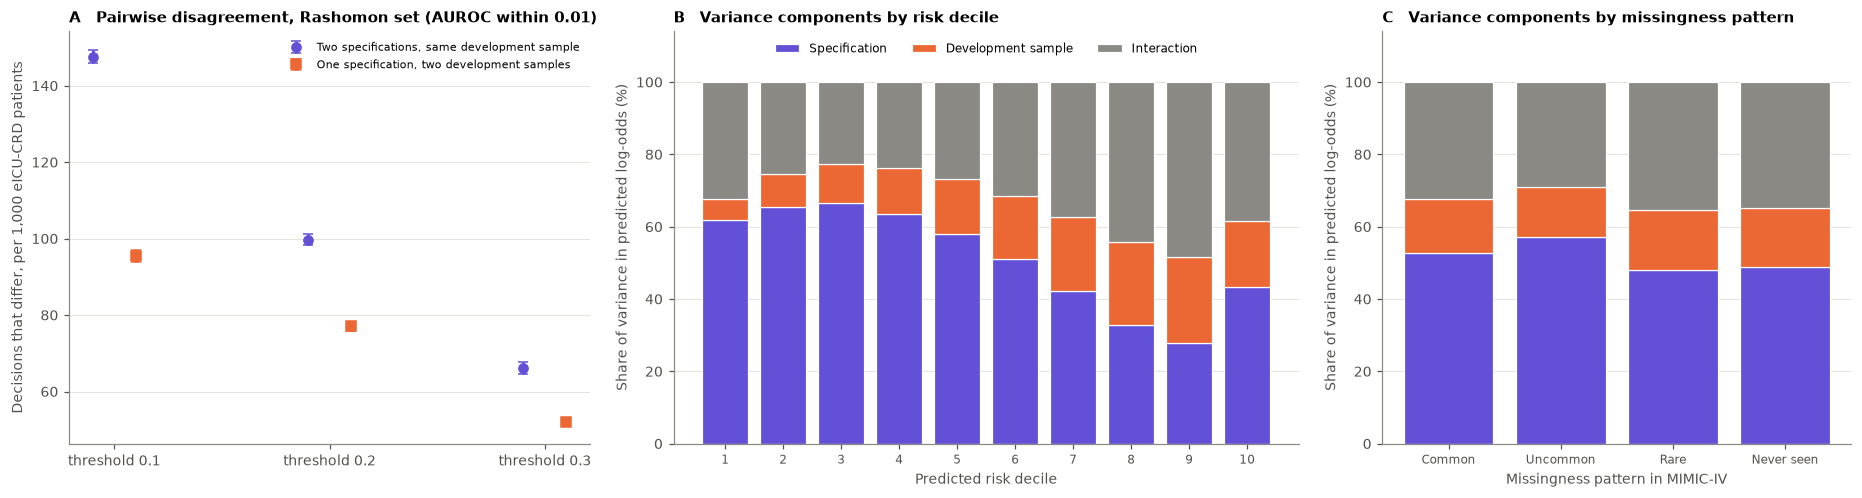

In [45]:
def twoway_task(key, r, sample_seed, fit_seed, X, y, pool, Xe):
    rng = np.random.default_rng(sample_seed)
    b = pool[rng.integers(0, pool.size, pool.size)]
    builder = ModelBuilder(SPECS[key][2]())
    model, _ = fit_quietly(builder, X[b], y[b], random_state=fit_seed % (2**31 - 1))
    return key, r, builder.predict_risk(model, Xe).astype(np.float32)


def not_all_equal(D, axis):
    return D.any(axis=axis) & ~D.all(axis=axis)


if ADD_RUN["twoway"]:
    R2 = ADD["twoway_r"]
    with timed("Addendum 25: two-way multiverse"):
        missing = [r for r in range(R2) if CONFIG["force"] or not (ADD_CACHE / f"twoway_r{r}.npz").exists()]
        if missing:
            outs = run_parallel([delayed(twoway_task)(k, r, seed_for("twoway-sample", r), seed_for("twoway-fit", k, r), X_dev, y_dev, POOL, X_ext)
                                 for r in missing for k in SPEC_KEYS])
            got = {(k, r): p for k, r, p in outs}
            for r in missing:
                np.savez_compressed(ADD_CACHE / f"twoway_r{r}.npz", P=np.vstack([got[(k, r)] for k in SPEC_KEYS]))
        TW = np.stack([np.load(ADD_CACHE / f"twoway_r{r}.npz")["P"] for r in range(R2)], axis=1)   # specs x resamples x patients

    sets = {f"Rashomon set (AUROC within {CONFIG['rashomon_epsilon']:g})": np.flatnonzero(SPEC_TABLE[f"rashomon_{CONFIG['rashomon_epsilon']:g}"]),
            f"Rashomon set (AUROC within {CONFIG['rashomon_epsilon_sensitivity']:g})":
                np.flatnonzero(SPEC_TABLE[f"rashomon_{CONFIG['rashomon_epsilon_sensitivity']:g}"]),
            "All 12 specifications": np.arange(len(SPEC_KEYS))}
    amb_rows, pair_rows, vc_rows, vc_bins = [], [], [], []
    for name, M in sets.items():
        k = len(M)
        if k < 2:
            continue
        kw = min(k, R2)
        L = logit(TW[M].astype(np.float64))
        for t in THRESHOLDS:
            D = TW[M] >= t
            # pairwise disagreement: two specifications on the same resample, or one specification on two resamples
            spec_pairs = [(i, j) for i in range(k) for j in range(i + 1, k)]
            mc_pair = np.array([np.mean([np.mean(D[i, r] != D[j, r]) for i, j in spec_pairs]) for r in range(R2)])
            S = np.zeros((R2, R2))
            for r in range(R2):
                for r2 in range(r + 1, R2):
                    S[r, r2] = S[r2, r] = np.mean([np.mean(D[s, r] != D[s, r2]) for s in range(k)])
            off = ~np.eye(R2, dtype=bool)
            mc_hat, sa_hat = mc_pair.mean(), S[off].mean()
            rng_tw = np.random.default_rng(seed_for("twoway-ci", name, t))
            boot = np.empty((2000, 2))
            for bi in range(2000):
                idx = rng_tw.integers(0, R2, R2)
                sub = S[np.ix_(idx, idx)]
                keep = idx[:, None] != idx[None, :]
                boot[bi] = mc_pair[idx].mean(), sub[keep].mean() if keep.any() else np.nan
            dif = boot[:, 0] - boot[:, 1]
            pair_rows.append({"set": name, "models": k, "threshold": t,
                              "model_choice_per_1000": 1000 * mc_hat,
                              "model_choice_lower": 1000 * np.nanquantile(boot[:, 0], 0.025), "model_choice_upper": 1000 * np.nanquantile(boot[:, 0], 0.975),
                              "sample_per_1000": 1000 * sa_hat,
                              "sample_lower": 1000 * np.nanquantile(boot[:, 1], 0.025), "sample_upper": 1000 * np.nanquantile(boot[:, 1], 0.975),
                              "difference_per_1000": 1000 * (mc_hat - sa_hat),
                              "difference_lower": 1000 * np.nanquantile(dif, 0.025), "difference_upper": 1000 * np.nanquantile(dif, 0.975),
                              "ratio_model_choice_to_sample": mc_hat / sa_hat if sa_hat > 0 else np.nan})
            # any disagreement among k decisions (the rule of section 10), k specifications versus k resamples
            model_r = np.array([not_all_equal(D[:, r, :], 0).mean() for r in range(R2)])
            samp_r = np.array([[not_all_equal(D[s, [(r + j) % R2 for j in range(kw)], :], 0).mean() for r in range(R2)] for s in range(k)]).mean(axis=0)
            ref = int(np.flatnonzero(M == BEST)[0]) if BEST in M else 0
            both = np.array([(not_all_equal(D[:, r, :], 0) & not_all_equal(D[ref, [(r + j) % R2 for j in range(kw)], :], 0)).mean()
                             for r in range(R2)])
            amb_rows.append({"set": name, "models": k, "window": kw, "threshold": t,
                             "model_choice_per_1000": 1000 * model_r.mean(), "model_choice_range_lower": 1000 * np.quantile(model_r, 0.025),
                             "model_choice_range_upper": 1000 * np.quantile(model_r, 0.975),
                             "sample_per_1000": 1000 * samp_r.mean(), "sample_range_lower": 1000 * np.quantile(samp_r, 0.025),
                             "sample_range_upper": 1000 * np.quantile(samp_r, 0.975), "both_per_1000": 1000 * both.mean()})
        grand = L.mean(axis=(0, 1))
        a = L.mean(axis=1) - grand
        bb = L.mean(axis=0) - grand
        resid = L - grand - a[:, None, :] - bb[None, :, :]
        ms_a = R2 * (a ** 2).sum(axis=0) / (k - 1)
        ms_b = k * (bb ** 2).sum(axis=0) / (R2 - 1)
        ms_e = (resid ** 2).sum(axis=(0, 1)) / ((k - 1) * (R2 - 1))
        v_spec, v_samp, v_int = np.maximum((ms_a - ms_e) / R2, 0), np.maximum((ms_b - ms_e) / k, 0), ms_e
        tot = np.maximum(v_spec + v_samp + v_int, 1e-12)
        shares = {"Specification": v_spec / tot, "Development sample": v_samp / tot, "Interaction": v_int / tot}
        vc_rows.append({"set": name, "models": k, **{f"share_{kk}": float(v.mean()) for kk, v in shares.items()},
                        **{f"median_sd_{kk}": float(np.median(np.sqrt(v))) for kk, v in
                           (("Specification", v_spec), ("Development sample", v_samp), ("Interaction", v_int))}})
        risk = expit(grand)
        dec = np.clip(np.searchsorted(np.quantile(risk, np.linspace(0, 1, 11)[1:-1]), risk, side="right"), 0, 9)
        for d in range(10):
            sel = dec == d
            vc_bins.append({"set": name, "by": "risk decile", "level": str(d + 1), **{kk: float(v[sel].mean()) for kk, v in shares.items()}})
        for c, lab in enumerate(PATTERN_LABELS):
            sel = PATTERN_CLASS == c
            if sel.sum() >= 50:
                vc_bins.append({"set": name, "by": "missingness pattern", "level": lab, **{kk: float(v[sel].mean()) for kk, v in shares.items()}})
    TABLEA7 = pd.DataFrame(pair_rows)
    TABLEA7K = pd.DataFrame(amb_rows)
    TABLEA7V = pd.DataFrame(vc_rows)
    TABLEA7B = pd.DataFrame(vc_bins)
    save_table(TABLEA7.round(4), "tableA7_two_way_pairwise_disagreement",
               "Addendum: pairwise decision disagreement, model choice versus development sample (two-way multiverse)")
    save_table(TABLEA7K.round(4), "tableA7d_two_way_any_disagreement", "Addendum: any disagreement among k specifications versus k resamples")
    save_table(TABLEA7V.round(4), "tableA7b_two_way_variance_components", "Addendum: variance components of predicted log-odds")
    save_table(TABLEA7B.round(4), "tableA7c_two_way_variance_by_group", "Addendum: variance components by risk decile and missingness pattern")
    ADDENDUM["two_way_ambiguity"] = TABLEA7.to_dict(orient="records")
    ADDENDUM["two_way_any_disagreement"] = TABLEA7K.to_dict(orient="records")
    ADDENDUM["two_way_variance"] = TABLEA7V.to_dict(orient="records")
    display(TABLEA7.round(1))
    display(TABLEA7K.round(1))
    display(TABLEA7V.round(3))

    main_set = list(sets)[0]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1, 1.2, 0.9]})
    ax = axes[0]
    t7 = TABLEA7[TABLEA7["set"] == main_set]
    xs = np.arange(len(t7))
    ax.errorbar(xs - 0.1, t7["model_choice_per_1000"], yerr=[t7["model_choice_per_1000"] - t7["model_choice_lower"],
                                                            t7["model_choice_upper"] - t7["model_choice_per_1000"]],
                fmt="o", color="#6250d6", capsize=3, label="Two specifications, same development sample")
    ax.errorbar(xs + 0.1, t7["sample_per_1000"], yerr=[t7["sample_per_1000"] - t7["sample_lower"], t7["sample_upper"] - t7["sample_per_1000"]],
                fmt="s", color=DB_COLORS["eICU-CRD"], capsize=3, label="One specification, two development samples")
    ax.set_xticks(xs)
    ax.set_xticklabels([f"threshold {t:g}" for t in t7["threshold"]])
    ax.set_ylabel("Decisions that differ, per 1,000 eICU-CRD patients")
    ax.set_title(f"Pairwise disagreement, {main_set}", fontsize=9.5)
    ax.legend(fontsize=7.5)
    ax.grid(axis="x", visible=False)
    panel_label(ax, "A")
    comp_cols = {"Specification": "#6250d6", "Development sample": DB_COLORS["eICU-CRD"], "Interaction": NEUTRAL}
    for ax, by, letter in ((axes[1], "risk decile", "B"), (axes[2], "missingness pattern", "C")):
        t = TABLEA7B[(TABLEA7B["set"] == main_set) & (TABLEA7B["by"] == by)]
        bottom = np.zeros(len(t))
        for comp, col in comp_cols.items():
            ax.bar(range(len(t)), 100 * t[comp], bottom=100 * bottom, color=col, width=0.8, edgecolor="white", linewidth=0.8, label=comp)
            bottom += t[comp].to_numpy()
        ax.set_xticks(range(len(t)))
        ax.set_xticklabels(t["level"] if by == "risk decile" else [l.split(" (")[0].replace(" in MIMIC-IV", "") for l in t["level"]],
                           fontsize=8)
        ax.set_ylabel("Share of variance in predicted log-odds (%)")
        ax.set_xlabel("Predicted risk decile" if by == "risk decile" else "Missingness pattern in MIMIC-IV")
        ax.set_title(f"Variance components by {by}", fontsize=9.5)
        ax.set_ylim(0, 114)
        ax.set_yticks(range(0, 101, 20))
        ax.grid(axis="x", visible=False)
        panel_label(ax, letter)
    axes[1].legend(fontsize=8, loc="upper center", ncol=3, frameon=False)
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA7_two_way_multiverse", "Addendum: symmetric comparison of model-choice and sample ambiguity")

## 26. Simulation study with known data-generating mechanisms (Figure A8, Table A8)

Real data cannot show that the new measures respond to what they are meant to measure, because the cause of any shift is unknown. The simulation fixes the cause. It is reported in the ADEMP structure recommended for simulation studies (Morris, White and Crowther, 2019).

* **Aims.** (1) Does the bootstrap instability transport ratio recover the true ratio? (2) Does it rise when, and only when, the external population moves to where the model's predictions are less certain? (3) Is it unaffected by shifts that change calibration but not uncertainty?
* **Data-generating mechanisms.** Eight correlated normal predictors (correlation 0.3); true log-odds -2.4 + 0.9 x1 + 0.7 x2 + 0.5 x3 + 0.4 x4 + 0.3 x5 + 0.2 x6 (x7 and x8 are noise), outcome prevalence about 12%; x1 missing completely at random in 1% of development patients (as the GCS motor score is rarely missing in MIMIC-IV). Development and external samples of 4,000 patients. Five external scenarios:

| Scenario | External change | Expected behaviour |
|---|---|---|
| No shift | none | ratio about 1 for every model; calibration preserved |
| Case-mix shift | x2 to x4 shifted by +1 SD | ratio somewhat above 1 for logistic regression (predictions further from the data centre) |
| Missingness shift | x1 missing in 35% | ratio well above 1 for logistic regression with an indicator; about 1 with imputation only |
| Outcome-rate shift | intercept +0.7 | ratio unchanged (instability depends on the predictors, not the outcome); O/E moves away from 1 |
| Predictor-effect shift | effect of x1 halved | ratio unchanged; calibration slope and discrimination change |

* **Estimand.** The true instability transport ratio for each model and scenario: the summed SD of predictions across 100 independent development samples for external patients, divided by the SD expected at the same predicted risk for development-like patients.
* **Methods.** Logistic regression with a missingness indicator, logistic regression with imputation only, gradient boosting with native missing values (same hyperparameters as the empirical analysis). In each of 50 replicates a fresh development sample is audited with 100 bootstrap refits, exactly as in the empirical analysis, and the same refits are applied to all five external samples.
* **Performance measures.** Mean bootstrap ratio, its bias against the true ratio with Monte Carlo standard error (SD across replicates divided by the square root of the number of replicates), relative bias, and the 2.5th to 97.5th percentiles across replicates; mean external AUROC, O/E and calibration slope.


>>> Addendum 26: simulation study
<<< Addendum 26: simulation study: 79.7 min


,scenario,model,itr,itr_lower,itr_upper,auroc,oe,slope,true_itr,bootstrap_over_true_itr,bias,itr_sd_across_replicates,replicates,bias_mcse,relative_bias_percent
6,No shift,"GBM, native missing values",1.003,0.995,1.012,0.851,1.044,0.745,0.993,1.010,0.010,0.005,50,0.001,1.024
7,No shift,"LR, imputation only",1.000,0.989,1.009,0.871,1.006,0.987,0.987,1.013,0.013,0.006,50,0.001,1.266
8,No shift,LR + missingness indicator,0.999,0.985,1.013,0.871,1.006,0.984,0.989,1.010,0.010,0.010,50,0.001,1.013
0,Case-mix shift,"GBM, native missing values",1.039,1.017,1.060,0.836,1.038,0.728,1.040,0.999,-0.001,0.010,50,0.001,-0.057
1,Case-mix shift,"LR, imputation only",1.103,1.061,1.138,0.861,0.993,0.983,1.085,1.017,0.018,0.021,50,0.003,1.700
2,Case-mix shift,LR + missingness indicator,1.106,1.070,1.153,0.860,0.994,0.979,1.088,1.016,0.017,0.025,50,0.004,1.592
3,Missingness shift,"GBM, native missing values",1.078,1.050,1.115,0.834,1.066,0.721,1.075,1.003,0.003,0.020,50,0.003,0.280
4,Missingness shift,"LR, imputation only",1.002,0.990,1.016,0.860,1.078,1.010,0.995,1.007,0.007,0.007,50,0.001,0.748
5,Missingness shift,LR + missingness indicator,1.838,1.626,2.168,0.856,1.027,0.988,1.815,1.012,0.023,0.164,50,0.023,1.248
9,Outcome-rate shift,"GBM, native missing values",1.004,0.995,1.013,0.845,1.484,0.737,0.993,1.011,0.011,0.006,50,0.001,1.101


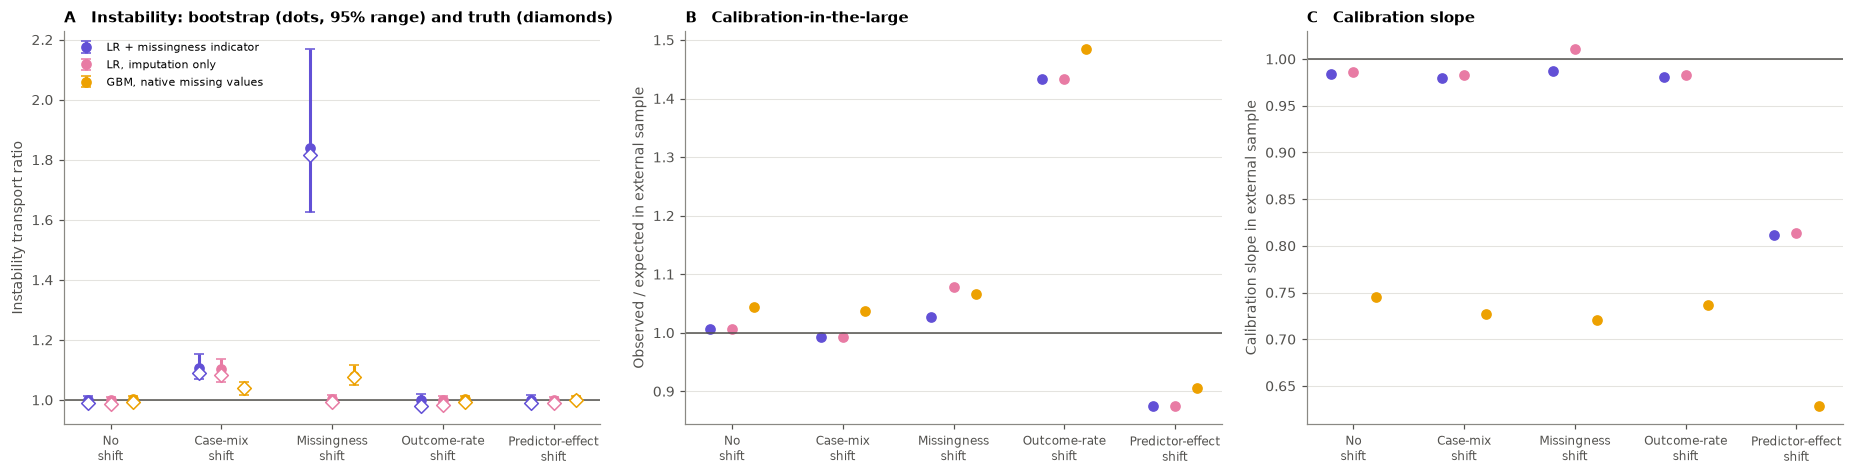

In [46]:
SIM_P, SIM_RHO, SIM_INTERCEPT, SIM_DEV_MISS = 8, 0.3, -2.4, 0.01
SIM_BETA = np.array([0.9, 0.7, 0.5, 0.4, 0.3, 0.2, 0.0, 0.0])
SIM_SCENARIOS = {"No shift": {}, "Case-mix shift": {"shift": 1.0}, "Missingness shift": {"miss": 0.35},
                 "Outcome-rate shift": {"intercept": 0.7}, "Predictor-effect shift": {"beta1": 0.5}}
SIM_MODELS = {"lr_ind": "LR + missingness indicator", "lr_imp": "LR, imputation only", "gbm": "GBM, native missing values"}
SIM_COLORS = {"lr_ind": "#6250d6", "lr_imp": "#e87ba4", "gbm": "#eda100"}


def sim_draw(n, rng, shift=0.0, miss=SIM_DEV_MISS, intercept=0.0, beta1=1.0):
    cov = np.full((SIM_P, SIM_P), SIM_RHO)
    np.fill_diagonal(cov, 1.0)
    X = rng.multivariate_normal(np.zeros(SIM_P), cov, size=n)
    X[:, 1:4] += shift
    beta = SIM_BETA.copy()
    beta[0] *= beta1
    y = (rng.random(n) < expit(SIM_INTERCEPT + intercept + X @ beta)).astype(np.int64)
    X[rng.random(n) < miss, 0] = np.nan
    return X, y


def sim_estimator(name):
    if name == "lr_ind":
        return Pipeline([("prep", GroupedImputer([[0]])), ("model", LogisticRegression(C=np.inf, max_iter=5000))])
    if name == "lr_imp":
        return Pipeline([("prep", GroupedImputer(None)), ("model", LogisticRegression(C=np.inf, max_iter=5000))])
    return hgb_estimator()


def sim_rep_task(rep, model_key, B, n):
    Xd, yd = sim_draw(n, np.random.default_rng(seed_for("sim-dev", rep)))
    exts = {s: sim_draw(n, np.random.default_rng(seed_for("sim-ext", rep, s)), **kw) for s, kw in SIM_SCENARIOS.items()}
    builder = ModelBuilder(sim_estimator(model_key))
    base, _ = fit_quietly(builder, Xd, yd, random_state=seed_for("sim-fit", rep, model_key) % (2**31 - 1))
    P = np.empty((B, n))
    Pe = {s: np.empty((B, n)) for s in SIM_SCENARIOS}
    inbag = np.zeros((B, n), bool)
    rng = np.random.default_rng(seed_for("sim-boot", rep, model_key))
    for b in range(B):
        idx = rng.integers(0, n, n)
        mdl, _ = fit_quietly(builder, Xd[idx], yd[idx], random_state=int(rng.integers(0, 2**31 - 1)))
        P[b] = builder.predict_risk(mdl, Xd)
        for s, (Xe, _) in exts.items():
            Pe[s][b] = builder.predict_risk(mdl, Xe)
        inbag[b, idx] = True
    w = (~inbag).astype(np.float64)
    nn = w.sum(axis=0)
    ok = nn >= (5 if B >= 50 else 2)
    mean = (w * P).sum(axis=0) / np.maximum(nn, 1)
    sd = np.sqrt((w * (P - mean) ** 2).sum(axis=0) / np.maximum(nn - 1, 1))
    curve = risk_curve(mean[ok], sd[ok])
    rows = []
    for s, (Xe, ye) in exts.items():
        pe = builder.predict_risk(base, Xe)
        met = ext_metrics(ye, pe)
        rows.append({"scenario": s, "model": model_key, "replicate": rep,
                     "itr": Pe[s].std(axis=0, ddof=1).sum() / curve(Pe[s].mean(axis=0)).sum(),
                     "auroc": met["auroc"], "oe": met["oe_ratio"], "slope": met["calibration_slope"]})
    return rows


def sim_truth_task(model_key, ks, n):
    Xp, _ = sim_draw(n, np.random.default_rng(seed_for("sim-panel-dev")))
    panels = {s: sim_draw(n, np.random.default_rng(seed_for("sim-panel-ext", s)), **kw)[0] for s, kw in SIM_SCENARIOS.items()}
    builder = ModelBuilder(sim_estimator(model_key))
    out_d, out_e = [], {s: [] for s in SIM_SCENARIOS}
    for k in ks:
        Xd, yd = sim_draw(n, np.random.default_rng(seed_for("sim-truth-dev", k)))
        mdl, _ = fit_quietly(builder, Xd, yd, random_state=seed_for("sim-truth-fit", model_key, k) % (2**31 - 1))
        out_d.append(builder.predict_risk(mdl, Xp))
        for s in SIM_SCENARIOS:
            out_e[s].append(builder.predict_risk(mdl, panels[s]))
    return np.vstack(out_d), {s: np.vstack(v) for s, v in out_e.items()}


if ADD_RUN["simulation"]:
    spath = ADD_CACHE / f"simulation_r{ADD['sim_reps']}_b{ADD['sim_b']}_n{ADD['sim_n']}.parquet"
    tpath = ADD_CACHE / f"simulation_truth_k{ADD['sim_k']}_n{ADD['sim_n']}.parquet"
    with timed("Addendum 26: simulation study"):
        if CONFIG["force"] or not spath.exists():
            outs = run_parallel([delayed(sim_rep_task)(rep, mk, ADD["sim_b"], ADD["sim_n"]) for rep in range(ADD["sim_reps"]) for mk in SIM_MODELS])
            pd.DataFrame([r for o in outs for r in o]).to_parquet(spath, index=False)
        if CONFIG["force"] or not tpath.exists():
            chunks = np.array_split(np.arange(ADD["sim_k"]), max(1, min(N_JOBS, ADD["sim_k"])))
            trows = []
            for mk in SIM_MODELS:
                outs = run_parallel([delayed(sim_truth_task)(mk, list(c), ADD["sim_n"]) for c in chunks if len(c)])
                Td = np.vstack([o[0] for o in outs])
                curve = risk_curve(Td.mean(axis=0), Td.std(axis=0, ddof=1))
                for s in SIM_SCENARIOS:
                    Te = np.vstack([o[1][s] for o in outs])
                    trows.append({"scenario": s, "model": mk, "true_itr": Te.std(axis=0, ddof=1).sum() / curve(Te.mean(axis=0)).sum()})
            pd.DataFrame(trows).to_parquet(tpath, index=False)
    SIM = pd.read_parquet(spath)
    SIMT = pd.read_parquet(tpath)
    TABLEA8 = (SIM.groupby(["scenario", "model"])
               .agg(itr=("itr", "mean"), itr_lower=("itr", lambda s: s.quantile(0.025)), itr_upper=("itr", lambda s: s.quantile(0.975)),
                    auroc=("auroc", "mean"), oe=("oe", "mean"), slope=("slope", "mean")).reset_index()
               .merge(SIMT, on=["scenario", "model"], how="left"))
    TABLEA8["bootstrap_over_true_itr"] = TABLEA8["itr"] / TABLEA8["true_itr"]
    TABLEA8["bias"] = TABLEA8["itr"] - TABLEA8["true_itr"]
    sd_rep = SIM.groupby(["scenario", "model"])["itr"].agg(["std", "count"]).reset_index()
    TABLEA8 = TABLEA8.merge(sd_rep, on=["scenario", "model"], how="left")
    TABLEA8["bias_mcse"] = TABLEA8["std"] / np.sqrt(TABLEA8["count"])
    TABLEA8["relative_bias_percent"] = 100 * TABLEA8["bias"] / TABLEA8["true_itr"]
    TABLEA8 = TABLEA8.rename(columns={"count": "replicates", "std": "itr_sd_across_replicates"})
    TABLEA8["scenario"] = pd.Categorical(TABLEA8["scenario"], list(SIM_SCENARIOS), ordered=True)
    TABLEA8 = TABLEA8.sort_values(["scenario", "model"])
    save_table(TABLEA8.assign(model=TABLEA8["model"].map(SIM_MODELS)).round(4), "tableA8_simulation",
               "Addendum: simulation study, bootstrap and true instability transport ratio and external performance")
    ADDENDUM["simulation"] = TABLEA8.assign(scenario=TABLEA8["scenario"].astype(str)).to_dict(orient="records")
    display(TABLEA8.assign(model=TABLEA8["model"].map(SIM_MODELS)).round(3))

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
    scen = list(SIM_SCENARIOS)
    off = np.linspace(-0.2, 0.2, len(SIM_MODELS))
    for ax, (col, lo, hi, ylabel, ref), letter in zip(axes, [("itr", "itr_lower", "itr_upper", "Instability transport ratio", 1),
                                                         ("oe", None, None, "Observed / expected in external sample", 1),
                                                         ("slope", None, None, "Calibration slope in external sample", 1)], "ABC"):
        for o, mk in zip(off, SIM_MODELS):
            t = TABLEA8[TABLEA8["model"] == mk].set_index("scenario").reindex(scen)
            xs = np.arange(len(scen)) + o
            if lo:
                ax.errorbar(xs, t[col], yerr=[t[col] - t[lo], t[hi] - t[col]], fmt="o", color=SIM_COLORS[mk], capsize=3, label=SIM_MODELS[mk])
                ax.scatter(xs, t["true_itr"], marker="D", facecolors="white", edgecolors=SIM_COLORS[mk], s=40, zorder=4)
            else:
                ax.scatter(xs, t[col], color=SIM_COLORS[mk], s=36, label=SIM_MODELS[mk])
        ax.axhline(ref, color=INK2, lw=1)
        ax.set_xticks(range(len(scen)))
        ax.set_xticklabels([s.replace(" shift", "\nshift") for s in scen], fontsize=8)
        ax.set_ylabel(ylabel)
        ax.grid(axis="x", visible=False)
        ax.set_title({"A": "Instability: bootstrap (dots, 95% range) and truth (diamonds)", "B": "Calibration-in-the-large",
                      "C": "Calibration slope"}[letter], fontsize=9.5)
        panel_label(ax, letter)
    axes[0].legend(fontsize=7.5, loc="upper left")
    fig.tight_layout()
    save_figure(fig, "p3_addendum_figA8_simulation", "Addendum: simulation study with known data-generating mechanisms")

## 27. Addendum digest, reproducibility files, updated provenance and final checks

The digest collects the numbers needed to answer each review point. The environment lock file records the exact version of every installed package, and the reproduction map lists every file this notebook wrote with its description, so each table and figure can be traced to the cell that produced it. The provenance manifest and study hash are then re-saved to include the addendum, and the final checks are repeated.

**Points that remain manuscript tasks rather than analyses:** a PROBAST+AI self-assessment in the supplement; the cpmaudit source code, tests, pinned environment and a Zenodo DOI released on GitHub with the paper; and clear labelling of sections 18 to 27 as post hoc.

In [47]:
import importlib.metadata as _md

lock = sorted(f"{d.metadata['Name']}=={d.version}" for d in _md.distributions() if d.metadata.get("Name"))
lock_path = DIRS["logs"] / "environment_lock.txt"
lock_path.write_text("\n".join(lock) + "\n", encoding="utf-8")
PROV.register(lock_path, "environment", "Exact versions of all installed Python packages")

lines = ["**Addendum digest (post hoc analyses).**"]
if "monte_carlo" in ADDENDUM:
    mc = ADDENDUM["monte_carlo"]
    lines.append(f"- **Monte Carlo precision ({mc[0]['refits']} refits).** Monte Carlo SD of the instability transport ratio: "
                 + ", ".join(f"{r['model']} {r['itr']:.2f} (SD {r['itr_mc_sd']:.3f}; at 1,000 refits {r['itr_mc_sd_at_1000']:.3f})" for r in mc)
                 + ". Empirical decision-unstable per 1,000 in MIMIC-IV: "
                 + ", ".join(f"{r['model']} {r['unstable_per_1000_development']:.0f} (SD {r['unstable_per_1000_development_mc_sd']:.1f})" for r in mc)
                 + "; change from half the refits: " + ", ".join(
                     f"{next(v for c, v in r.items() if c.startswith('unstable_per_1000_development_change')):+.1f}%" for r in mc)
                 + ". Decision instability ratio, empirical versus logit-normal counts: "
                 + ", ".join(f"{r['model']} {r['dir']:.2f} versus {r['dir_logitnormal']:.2f}" for r in mc) + ".")
if "effective_sample_size" in ADDENDUM:
    lines.append("- **Effective sample size (median, MIMIC-IV versus eICU-CRD).** " + "; ".join(
        f"{r['model']} {r['median_development']:,.0f} versus {r['median_external']:,.0f}" for r in ADDENDUM["effective_sample_size"]) + ".")
if "factorial" in ADDENDUM:
    t = pd.DataFrame(ADDENDUM["factorial"])
    t = t[t["gcs_motor"] == "included"]
    lines.append("- **Factorial experiment (ITR, GCS included).** " + "; ".join(
        f"{MODEL_SHORT[m]}: " + ", ".join(f"{r.representation.lower()} {r.itr:.2f}" for r in g.itertuples()) for m, g in t.groupby("model", sort=False)) + ".")
if "hypotheses" in ADDENDUM:
    lines.append("- **Pre-stated transport hypotheses.** " + "; ".join(
        f"{r['hypothesis']} for {r['model']}: {'supported' if r['supported'] else ('not testable' if r['supported'] is None else 'not supported')} ({r['evidence']})"
        for r in ADDENDUM["hypotheses"]) + ".")
if "extended_ground_truth" in ADDENDUM:
    lines.append("- **Extended ground truth.** " + "; ".join(
        f"{MODEL_SHORT[r['model']]} n = {r['n']:,}: bootstrap/truth eICU-CRD {r['ratio_eicu']:.2f} (10th to 90th percentile "
        f"{r['ratio_eicu_p10']:.2f} to {r['ratio_eicu_p90']:.2f}), MIMIC-IV {r['ratio_audit']:.2f}; true ITR {r['true_itr']:.2f}; "
        f"20% deferral captures {100 * r['capture_bootstrap_20']:.0f}% (bootstrap) versus {100 * r['capture_distance_20']:.0f}% (distance)"
        for r in ADDENDUM["extended_ground_truth"]) + ".")
if "two_way_ambiguity" in ADDENDUM:
    t = pd.DataFrame(ADDENDUM["two_way_ambiguity"])
    t = t[(t["set"] == t["set"].iloc[0]) & (t["threshold"] == T0)].iloc[0]
    v = pd.DataFrame(ADDENDUM["two_way_variance"]).iloc[0]
    lines.append(f"- **Two-way multiverse ({t['set']}, threshold {T0:g}).** Decisions differing per 1,000 eICU-CRD patients: "
                 f"two specifications on the same sample {t['model_choice_per_1000']:.0f} ({t['model_choice_lower']:.0f} to {t['model_choice_upper']:.0f}), "
                 f"one specification on two samples {t['sample_per_1000']:.0f} ({t['sample_lower']:.0f} to {t['sample_upper']:.0f}); "
                 f"difference {t['difference_per_1000']:.0f} (95% CI {t['difference_lower']:.0f} to {t['difference_upper']:.0f}). "
                 f"Variance of predicted log-odds: specification {100 * v['share_Specification']:.0f}%, development sample "
                 f"{100 * v['share_Development sample']:.0f}%, interaction {100 * v['share_Interaction']:.0f}%.")
if "simulation" in ADDENDUM:
    t = pd.DataFrame(ADDENDUM["simulation"])
    lines.append("- **Simulation (bootstrap ITR / true ITR).** " + "; ".join(
        f"{r['scenario']}, {SIM_MODELS[r['model']]}: {r['itr']:.2f} / {r['true_itr']:.2f}" for r in ADDENDUM["simulation"]) + ".")
add_text = "\n".join(lines)
display(Markdown(add_text))
(DIRS["tables"] / "results_digest_addendum.md").write_text(add_text, encoding="utf-8")
PROV.register(DIRS["tables"] / "results_digest_addendum.md", "markdown", "Generated addendum results paragraph")
save_json(ADDENDUM, "results_digest_addendum", "Addendum: key numbers for responses to review", folder="tables")

repro = pd.DataFrame([{"file": e["file"], "kind": e["kind"], "description": e["description"], "sha256": e["sha256"][:16]}
                      for e in PROV.entries]).drop_duplicates(subset="file", keep="last")
save_table(repro, "table_reproduction_map", "Every file written by notebook 3 with its description and hash")

p3_manifest_path = PROV.save({"config": {k: (str(v) if isinstance(v, Path) else v) for k, v in CONFIG.items()},
                              "addendum_config": {k: (list(v) if isinstance(v, (tuple, np.ndarray)) else v) for k, v in ADD.items()},
                              "addendum_sections": ADD_RUN, "sensitivity_models": SENS_MODELS})
manifests = {"notebook 1": load_manifest(P1 / "logs" / "provenance_manifest.json"), "notebook 2": p2_manifest,
             "notebook 3": load_manifest(p3_manifest_path)}
chain = "".join((mf or {}).get("final_chain_sha256", "missing") for mf in manifests.values())
STUDY["created_utc"] = dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")
STUDY["notebooks"] = {k: ({"final_chain_sha256": v.get("final_chain_sha256"), "files": len(v.get("files", [])),
                           "finished_utc": v.get("finished_utc")} if v else "manifest not found") for k, v in manifests.items()}
STUDY["study_sha256"] = hashlib.sha256(chain.encode()).hexdigest()
STUDY["addendum"] = True
(PROJECT / "outputs" / "study_manifest.json").write_text(json.dumps(STUDY, indent=2, default=str), encoding="utf-8")

fig_names = sorted({p.stem for p in DIRS["figures"].glob("p3_*.png")})
assert not [n for n in fig_names if not (DIRS["figures"] / f"{n}.pdf").exists()], "a figure lacks its PDF version"
problems = []
for path in DIRS["tables"].glob("*.csv"):
    t = pd.read_csv(path)
    bad_cols = [c for c in t.columns if c.lower() in {"stay_id", "patient_id", "subject_id", "hadm_id", "patientunitstayid", "site_id"}]
    if bad_cols or (len(t) > 0.2 * min(N_DEV, N_EXT) and path.name != "table_reproduction_map.csv"):
        problems.append({"table": path.name, "identifier_columns": bad_cols, "rows": len(t)})
assert not problems, f"Tables that may contain patient-level data: {problems}"
for private in (DIRS["data"], CACHE.parent):
    assert (private / ".gitignore").read_text().strip() == "*", f"{private} is not excluded from version control"
add_figs = [n for n in fig_names if "addendum" in n]
print(f"Addendum figures: {len(add_figs)} ({', '.join(add_figs)})")
print(f"Total figures: {len(fig_names)}; tables: {len(list(DIRS['tables'].glob('*.csv')))}; registered files: {len(PROV.entries)}")
print("Study hash (with addendum):", STUDY["study_sha256"])
print(f"Timed steps in this run: {sum(s['seconds'] for s in PROV.steps) / 60:.1f} min. Preset: {PRESET}.")

**Addendum digest (post hoc analyses).**
- **Monte Carlo precision (200 refits).** Monte Carlo SD of the instability transport ratio: Logistic regression 3.04 (SD 0.087; at 1,000 refits 0.039), Ridge logistic regression 2.93 (SD 0.075; at 1,000 refits 0.034), Random forest 0.98 (SD 0.001; at 1,000 refits 0.001), Gradient boosting 1.10 (SD 0.004; at 1,000 refits 0.002). Empirical decision-unstable per 1,000 in MIMIC-IV: Logistic regression 77 (SD 0.8), Ridge logistic regression 76 (SD 0.7), Random forest 113 (SD 0.5), Gradient boosting 150 (SD 0.6); change from half the refits: +1.1%, +0.9%, +1.1%, +0.5%. Decision instability ratio, empirical versus logit-normal counts: Logistic regression 2.81 versus 3.32, Ridge logistic regression 2.86 versus 3.10, Random forest 0.98 versus 0.99, Gradient boosting 1.09 versus 1.10.
- **Effective sample size (median, MIMIC-IV versus eICU-CRD).** Logistic regression 1,459 versus 202; Ridge logistic regression 1,574 versus 225; Random forest 500 versus 443; Gradient boosting 288 versus 104.
- **Factorial experiment (ITR, GCS included).** LR: imputation + indicators 3.16, imputation only 1.13; Ridge: imputation + indicators 2.86, imputation only 1.15; RF: imputation + indicators 0.98, imputation only 1.00, native missing values 1.00; GBM: native missing values 1.10, imputation only 1.06, imputation + indicators 1.06.
- **Pre-stated transport hypotheses.** H1 reverse smaller than forward for Logistic regression: supported (reverse 1.05 (1.04 to 1.05); forward 3.16 (2.83 to 3.50)); H1 reverse smaller than forward for Ridge logistic regression: supported (reverse 1.06 (1.05 to 1.07); forward 2.86 (2.61 to 3.15)); H2 temporal ratio within 0.8 to 1.25 for Logistic regression: supported (1.00 (0.98 to 1.01)); H2 temporal ratio within 0.8 to 1.25 for Ridge logistic regression: supported (1.01 (0.99 to 1.02)); H2 temporal ratio within 0.8 to 1.25 for Random forest: supported (1.01 (1.00 to 1.01)); H2 temporal ratio within 0.8 to 1.25 for Gradient boosting: supported (1.01 (1.00 to 1.02)); H3 rare or unseen patterns above common for Logistic regression (Forward: MIMIC-IV to eICU-CRD): supported (common 1.09; rare or unseen 4.53, 5.25); H3 rare or unseen patterns above common for Ridge logistic regression (Forward: MIMIC-IV to eICU-CRD): supported (common 1.08; rare or unseen 4.04, 4.59); H3 rare or unseen patterns above common for Logistic regression (Reverse: eICU-CRD to MIMIC-IV): supported (common 0.95; rare or unseen 1.20, 1.73); H3 rare or unseen patterns above common for Ridge logistic regression (Reverse: eICU-CRD to MIMIC-IV): supported (common 0.95; rare or unseen 1.25, 1.78); H3 rare or unseen patterns above common for Logistic regression (Temporal: MIMIC-IV earlier to 2017 - 2019): supported (common 0.94; rare or unseen 2.46); H3 rare or unseen patterns above common for Ridge logistic regression (Temporal: MIMIC-IV earlier to 2017 - 2019): supported (common 0.95; rare or unseen 2.46).
- **Extended ground truth.** LR n = 3,906: bootstrap/truth eICU-CRD 0.49 (10th to 90th percentile 0.27 to 1.05), MIMIC-IV 0.99; true ITR 3.00; 20% deferral captures 31% (bootstrap) versus 26% (distance); Ridge n = 3,906: bootstrap/truth eICU-CRD 0.67 (10th to 90th percentile 0.36 to 1.13), MIMIC-IV 1.05; true ITR 2.83; 20% deferral captures 35% (bootstrap) versus 31% (distance); RF n = 3,906: bootstrap/truth eICU-CRD 1.03 (10th to 90th percentile 0.99 to 1.08), MIMIC-IV 1.02; true ITR 0.97; 20% deferral captures 55% (bootstrap) versus 53% (distance); GBM n = 3,906: bootstrap/truth eICU-CRD 0.92 (10th to 90th percentile 0.80 to 1.07), MIMIC-IV 0.95; true ITR 1.04; 20% deferral captures 45% (bootstrap) versus 41% (distance); LR n = 16,000: bootstrap/truth eICU-CRD 0.85 (10th to 90th percentile 0.68 to 1.05), MIMIC-IV 0.99; true ITR 3.36; 20% deferral captures 44% (bootstrap) versus 36% (distance).
- **Two-way multiverse (Rashomon set (AUROC within 0.01), threshold 0.1).** Decisions differing per 1,000 eICU-CRD patients: two specifications on the same sample 148 (146 to 149), one specification on two samples 95 (94 to 97); difference 52 (95% CI 50 to 54). Variance of predicted log-odds: specification 51%, development sample 16%, interaction 33%.
- **Simulation (bootstrap ITR / true ITR).** No shift, GBM, native missing values: 1.00 / 0.99; No shift, LR, imputation only: 1.00 / 0.99; No shift, LR + missingness indicator: 1.00 / 0.99; Case-mix shift, GBM, native missing values: 1.04 / 1.04; Case-mix shift, LR, imputation only: 1.10 / 1.08; Case-mix shift, LR + missingness indicator: 1.11 / 1.09; Missingness shift, GBM, native missing values: 1.08 / 1.08; Missingness shift, LR, imputation only: 1.00 / 0.99; Missingness shift, LR + missingness indicator: 1.84 / 1.82; Outcome-rate shift, GBM, native missing values: 1.00 / 0.99; Outcome-rate shift, LR, imputation only: 1.00 / 0.98; Outcome-rate shift, LR + missingness indicator: 1.00 / 0.98; Predictor-effect shift, GBM, native missing values: 1.00 / 1.00; Predictor-effect shift, LR, imputation only: 1.00 / 0.99; Predictor-effect shift, LR + missingness indicator: 1.00 / 0.99.

Addendum figures: 8 (p3_addendum_figA1_monte_carlo, p3_addendum_figA2_effective_sample_size, p3_addendum_figA3_thresholds_tolerances, p3_addendum_figA4_factorial, p3_addendum_figA5_transport_directions, p3_addendum_figA6_extended_ground_truth, p3_addendum_figA7_two_way_multiverse, p3_addendum_figA8_simulation)
Total figures: 24; tables: 38; registered files: 107
Study hash (with addendum): 587377914671c2d30c1d5a5ec24d6e2a8bd5da3f9f817e12f772c9a3961a536f
Timed steps in this run: 228.2 min. Preset: full.


In [48]:
gt = np.load(ADD_CACHE / f"gt_truth_lr_{N_FOCUS}_k{ADD['gt_k']}.npz")
chk = TABLEA6L[(TABLEA6L["model"] == "lr") & (TABLEA6L["n"] == N_FOCUS)].set_index("sample")
M = np.asarray(MISS_DEV)
cols = list(GROUP_COLS) if len(GROUP_COLS) == M.shape[1] else [f"group_{j}" for j in range(M.shape[1])]
counts = pd.DataFrame([M[gt["samples"][r]].sum(axis=0) for r in chk.index], index=chk.index, columns=cols)
rho = {g: spearmanr(counts[g], chk["ratio_eicu"]).correlation for g in cols if counts[g].nunique() > 1}
display(pd.Series(rho).sort_values().round(2))
g = max(rho, key=lambda k: abs(rho[k]))
display(counts[[g]].join(chk[["ratio_eicu", "boot_itr"]]).sort_values(g))

gcs_motor     -0.34
bilirubin     -0.30
resp_rate     -0.21
albumin       -0.16
mbp           -0.15
dbp           -0.11
lactate       -0.11
inr           -0.10
sbp           -0.08
creatinine    -0.05
platelets      0.00
bun            0.01
hemoglobin     0.05
wbc            0.12
glucose        0.13
chloride       0.16
bicarbonate    0.17
spo2           0.19
sodium         0.21
temperature    0.24
potassium      0.26
gcs_total      0.46
dtype: float64

,gcs_total,ratio_eicu,boot_itr
sample,,,
13,546,0.320577,1.751522
8,559,0.270281,1.864181
15,562,1.040510,2.708081
2,565,0.263099,1.798462
10,575,0.410106,1.932317
1,575,0.265387,1.930400
19,577,0.267553,1.766800
17,578,0.308123,1.895126
12,579,0.266470,2.032222
